# ASTRO-HEROES — Reordered Colab Notebook

Original analysis retained. Cells reordered so datasets, DEMs, validation and derived slope products exist before use. Remote DEM availability and scientific outputs still require a live Colab run.

Additional optional Marswalk routing demo from the newly uploaded file is appended at the end. It requires the separate `marswalk_router.py` file, which was not included in the uploaded Python script. ZIP download and Google Drive backup are opt-in cells.

In [106]:
# STEP 1: IMPORT PYTHON LIBRARIES
# Marswalk - Terrain Analysis
# ==========================================

# Data handling and numerical calculations
import pandas as pd
import numpy as np

# Working with raster terrain and satellite imagery
import rasterio

# Creating scientific plots and visualizations
import matplotlib.pyplot as plt

# Displaying tables and outputs inside Google Colab
from IPython.display import display

# Check the installed library versions
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

print("\nBasic Python environment setup completed.")

# ==========================================


Pandas: 2.2.3
NumPy: 2.4.6
Matplotlib: 3.10.0

Basic Python environment setup completed.


In [107]:
# STEP 2: CREATE ASTRO-HEROES WORKSPACE
# Purpose: Organize project files and outputs
# ==========================================

import os

# Main project directory
PROJECT_PATH = "/content/ASTRO_HEROES"

# Folder for original project datasets
DATA_PATH = os.path.join(PROJECT_PATH, "data")

# Folder for processed data and analysis results
OUTPUT_PATH = os.path.join(PROJECT_PATH, "outputs")

# Create the project folders
os.makedirs(DATA_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Confirm successful setup
print("ASTRO-HEROES workspace created successfully!")
print("Project folder:", PROJECT_PATH)
print("Data folder:", DATA_PATH)
print("Output folder:", OUTPUT_PATH)

# ==========================================


ASTRO-HEROES workspace created successfully!
Project folder: /content/ASTRO_HEROES
Data folder: /content/ASTRO_HEROES/data
Output folder: /content/ASTRO_HEROES/outputs


In [108]:
# STEP 3: VERIFY PROJECT FOLDERS
# Purpose: Confirm that the workspace is ready
# ==========================================

# Check the contents of the data folder
print("DATA FOLDER:")
print(os.listdir(DATA_PATH))

# Check the contents of the outputs folder
print("\nOUTPUT FOLDER:")
print(os.listdir(OUTPUT_PATH))

# ==========================================


DATA FOLDER:
['Mount_Sharp_Natural_Data.csv', 'Gale_Crater_DEM_HiRISE_Data.csv']

OUTPUT FOLDER:
['layers', 'Mount_Sharp_NASA_CTX_Combined.png', 'obstacles.geojson', 'route.json', 'route_rerouted.json']


In [109]:
# STEP 4: DOWNLOAD WAYPOINT DATASET
# Purpose: Download the shared CSV into our
# local ASTRO-HEROES project workspace
# ==========================================

%pip -q install gdown

import gdown

# Insert the Google Drive file ID
file_id = "1CfpXYMLGYx-_gnW9s9Wu5JA33jM97_d4"

# Build the download link
url = f"https://drive.google.com/uc?id={file_id}"

# Save the original dataset in our project data folder
destination = os.path.join(DATA_PATH, "Mount_Sharp_Natural_Data.csv")

gdown.download(url, destination, quiet=False)

print("\nDownload completed.")

# ==========================================


Downloading...
From: https://drive.google.com/uc?id=1CfpXYMLGYx-_gnW9s9Wu5JA33jM97_d4
To: /content/ASTRO_HEROES/data/Mount_Sharp_Natural_Data.csv
100%|██████████| 5.16k/5.16k [00:00<00:00, 5.43MB/s]


Download completed.


In [110]:
# STEP 5: VERIFY DOWNLOADED DATASET
# Purpose: Confirm file integrity and location
# ==========================================

import os

# Define the dataset path
waypoint_file = os.path.join(
    DATA_PATH, "Mount_Sharp_Natural_Data.csv"
)

# Check whether the file exists
if os.path.isfile(waypoint_file):
    file_size = os.path.getsize(waypoint_file) / 1024

    print("Dataset successfully verified!")
    print("File name:", os.path.basename(waypoint_file))
    print(f"File size: {file_size:.2f} KB")
else:
    print("Dataset not found. Please check the download.")

# ==========================================


Dataset successfully verified!
File name: Mount_Sharp_Natural_Data.csv
File size: 5.04 KB


In [111]:
# STEP 6: DOWNLOAD GALE CRATER TERRAIN DATA
# Purpose: Add the second dataset to our
# ASTRO-HEROES local project workspace
# ==========================================

# Insert the Google Drive file ID for the Gale Crater CSV
file_id = "1pIDAKomuf74uALNvfBWC4Vwzpkkgri2J"

# Generate the direct download link
url = f"https://drive.google.com/uc?id={file_id}"

# Define the destination inside our project data folder
destination = os.path.join(
    DATA_PATH, "Gale_Crater_DEM_HiRISE_Data.csv"
)

# Download the original dataset
gdown.download(url, destination, quiet=False)

print("\nGale Crater dataset download completed.")

# ==========================================


Downloading...
From: https://drive.google.com/uc?id=1pIDAKomuf74uALNvfBWC4Vwzpkkgri2J
To: /content/ASTRO_HEROES/data/Gale_Crater_DEM_HiRISE_Data.csv
100%|██████████| 4.36k/4.36k [00:00<00:00, 11.3MB/s]


Gale Crater dataset download completed.


In [112]:
# STEP 7: VERIFY GALE CRATER DATASET
# Purpose: Confirm that the second CSV file
# exists in our project workspace
# ==========================================

# Define the path to the downloaded dataset
gale_file = os.path.join(
    DATA_PATH, "Gale_Crater_DEM_HiRISE_Data.csv"
)

# Check whether the file exists and report its size
if os.path.isfile(gale_file):
    file_size = os.path.getsize(gale_file) / 1024

    print("Gale Crater dataset successfully verified!")
    print("File name:", os.path.basename(gale_file))
    print(f"File size: {file_size:.2f} KB")
else:
    print("Dataset not found. Please check the download.")

# ==========================================


Gale Crater dataset successfully verified!
File name: Gale_Crater_DEM_HiRISE_Data.csv
File size: 4.26 KB


In [113]:
# STEP 8: LOAD MOUNT SHARP WAYPOINT DATA
# Purpose: Read the CSV into Python so we can
# inspect and analyze its terrain information
# ==========================================

# Load the original CSV file into a DataFrame
waypoints_df = pd.read_csv(waypoint_file)

# Display the dataset dimensions (rows, columns)
print("Dataset dimensions:", waypoints_df.shape)

# Display all column names
print("\nDataset columns:")
print(waypoints_df.columns.tolist())

# Display the first five records
print("\nFirst five waypoints:")
display(waypoints_df.head())

# ==========================================


Dataset dimensions: (50, 1)

Dataset columns:
['Waypoint_ID;Latitude;Longitude;Elevation_m;Slope_deg;Boot_Sinkage_cm;Traction_Coefficient;Dynamic_Stability_Index;Surface_Temp_C;Risk_Level;DataSource']

First five waypoints:


,Waypoint_ID;Latitude;Longitude;Elevation_m;Slope_deg;Boot_Sinkage_cm;Traction_Coefficient;Dynamic_Stability_Index;Surface_Temp_C;Risk_Level;DataSource
0,1;-4.5813;137.44293;-4467.23;16.89;8.47;0.628;...
1,2;-4.58299;137.4452;-4447.79;7.26;5.19;0.638;0...
2,3;-4.58489;137.44736;-4433.69;2.88;4.91;0.839;...
3,4;-4.58661;137.44941;-4422.5;8.55;4.7;0.748;0....
4,5;-4.58812;137.45089;-4387.63;7.7;5.33;0.628;0...


In [114]:
# STEP 9: READ CSV WITH THE CORRECT SEPARATOR
# Purpose: Separate the 11 fields correctly
# ==========================================

# Reload the dataset using semicolon as the delimiter
waypoints_df = pd.read_csv(waypoint_file, sep=";")

# Check the corrected dataset dimensions
print("Dataset dimensions:", waypoints_df.shape)

# Display the column names
print("\nDataset columns:")
print(waypoints_df.columns.tolist())

# Display the first five records
print("\nFirst five waypoints:")
display(waypoints_df.head())

# ==========================================


Dataset dimensions: (50, 11)

Dataset columns:
['Waypoint_ID', 'Latitude', 'Longitude', 'Elevation_m', 'Slope_deg', 'Boot_Sinkage_cm', 'Traction_Coefficient', 'Dynamic_Stability_Index', 'Surface_Temp_C', 'Risk_Level', 'DataSource']

First five waypoints:


,Waypoint_ID,Latitude,Longitude,Elevation_m,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Surface_Temp_C,Risk_Level,DataSource
0,1,-4.58130,137.44293,-4467.23,16.89,8.47,0.628,0.757,-58.2,Medium,NASA_Mars_Trek_Mount_Sharp_Natural
1,2,-4.58299,137.44520,-4447.79,7.26,5.19,0.638,0.751,-61.6,Medium,NASA_Mars_Trek_Mount_Sharp_Natural
2,3,-4.58489,137.44736,-4433.69,2.88,4.91,0.839,0.946,-63.8,Low,NASA_Mars_Trek_Mount_Sharp_Natural
3,4,-4.58661,137.44941,-4422.50,8.55,4.70,0.748,0.793,-55.6,Low,NASA_Mars_Trek_Mount_Sharp_Natural
4,5,-4.58812,137.45089,-4387.63,7.70,5.33,0.628,0.766,-59.8,Medium,NASA_Mars_Trek_Mount_Sharp_Natural


In [115]:
# STEP 10: CHECK DATA QUALITY
# Purpose: Identify missing values, duplicate
# records, and incorrect column data types
# ==========================================

# Display the data type of every column
print("COLUMN DATA TYPES:")
print(waypoints_df.dtypes)

# Count missing values in each column
print("\nMISSING VALUES:")
print(waypoints_df.isnull().sum())

# Count duplicate rows
print("\nDUPLICATE ROWS:")
print(waypoints_df.duplicated().sum())

# Display a general dataset summary
print("\nDATASET SUMMARY:")
waypoints_df.info()

# ==========================================


COLUMN DATA TYPES:
Waypoint_ID                  int64
Latitude                   float64
Longitude                  float64
Elevation_m                float64
Slope_deg                  float64
Boot_Sinkage_cm            float64
Traction_Coefficient       float64
Dynamic_Stability_Index    float64
Surface_Temp_C             float64
Risk_Level                  object
DataSource                  object
dtype: object

MISSING VALUES:
Waypoint_ID                0
Latitude                   0
Longitude                  0
Elevation_m                0
Slope_deg                  0
Boot_Sinkage_cm            0
Traction_Coefficient       0
Dynamic_Stability_Index    0
Surface_Temp_C             0
Risk_Level                 0
DataSource                 0
dtype: int64

DUPLICATE ROWS:
0

DATASET SUMMARY:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   ---------

In [116]:
# STEP 9A: LOAD AND VERIFY BOTH DATASETS
# ==========================================

import pandas as pd
import numpy as np

# Load both datasets using semicolon separators
waypoints_df = pd.read_csv(waypoint_file, sep=";")
gale_df = pd.read_csv(gale_file, sep=";")

# Check dimensions
print("MOUNT SHARP:", waypoints_df.shape)
print("GALE CRATER:", gale_df.shape)

# Check column names
print("\nMOUNT SHARP COLUMNS:")
print(waypoints_df.columns.tolist())

print("\nGALE CRATER COLUMNS:")
print(gale_df.columns.tolist())

# Check missing values
print("\nMISSING VALUES:")
print("Mount Sharp:", waypoints_df.isna().sum().sum())
print("Gale Crater:", gale_df.isna().sum().sum())

# Verify waypoint IDs
assert waypoints_df["Waypoint_ID"].is_unique
assert gale_df["Point_ID"].is_unique

# Verify number of rows
assert len(waypoints_df) == 50
assert len(gale_df) == 50

print("\nBoth datasets loaded successfully!")

# ==========================================


MOUNT SHARP: (50, 11)
GALE CRATER: (50, 11)

MOUNT SHARP COLUMNS:
['Waypoint_ID', 'Latitude', 'Longitude', 'Elevation_m', 'Slope_deg', 'Boot_Sinkage_cm', 'Traction_Coefficient', 'Dynamic_Stability_Index', 'Surface_Temp_C', 'Risk_Level', 'DataSource']

GALE CRATER COLUMNS:
['Point_ID', 'Latitude_Deg', 'Longitude_Deg', 'Elevation_Meters', 'Slope_Angle_Deg', 'Surface_Roughness', 'Radiation_Level_mSv', 'Temperature_C', 'Soil_Cohesion_kPa', 'Risk_Level', 'DataSource']

MISSING VALUES:
Mount Sharp: 0
Gale Crater: 0

Both datasets loaded successfully!


In [117]:
# STEP 9B: TERRAIN DATA RELIABILITY CHECK
# ==========================================

# Sort datasets by point ID
mount_check = waypoints_df.sort_values(
    "Waypoint_ID"
).copy()

gale_check = gale_df.sort_values(
    "Point_ID"
).copy()

# Calculate consecutive elevation differences
mount_check["Elevation_Diff_m"] = (
    mount_check["Elevation_m"].diff()
)

gale_check["Elevation_Diff_m"] = (
    gale_check["Elevation_Meters"].diff()
)

# Display elevation difference statistics
print("MOUNT SHARP ELEVATION DIFFERENCES:")
print(mount_check["Elevation_Diff_m"].describe())

print("\nGALE CRATER ELEVATION DIFFERENCES:")
print(gale_check["Elevation_Diff_m"].describe())

# Check unique elevation increments
print("\nUNIQUE ELEVATION INCREMENTS:")

print(
    "Mount Sharp:",
    mount_check["Elevation_Diff_m"].dropna().round(3).unique()
)

print(
    "Gale Crater:",
    gale_check["Elevation_Diff_m"].dropna().round(3).unique()
)

# Check slope variation
print("\nUNIQUE SLOPE VALUES:")

print(
    "Mount Sharp:",
    mount_check["Slope_deg"].nunique()
)

print(
    "Gale Crater:",
    gale_check["Slope_Angle_Deg"].nunique()
)

# Check declared sources
print("\nDATA SOURCE LABELS:")

print("Mount Sharp:", mount_check["DataSource"].unique())
print("Gale Crater:", gale_check["DataSource"].unique())

# ==========================================


MOUNT SHARP ELEVATION DIFFERENCES:
count    49.000000
mean     27.455510
std      12.344547
min      -6.440000
25%      21.820000
50%      27.080000
75%      34.870000
max      51.280000
Name: Elevation_Diff_m, dtype: float64

GALE CRATER ELEVATION DIFFERENCES:
count    49.0
mean     15.0
std       0.0
min      15.0
25%      15.0
50%      15.0
75%      15.0
max      15.0
Name: Elevation_Diff_m, dtype: float64

UNIQUE ELEVATION INCREMENTS:
Mount Sharp: [19.44 14.1  11.19 34.87 23.62 28.88 28.98 24.14 -6.44 42.73 26.17 25.06
 47.63 22.7  41.83  6.39 34.76 10.16 28.52 38.9  14.33 21.82 30.68 27.08
 37.99 31.85 19.18 25.77 50.73 31.06  9.87 30.32 44.59 13.22 44.04 22.5
 34.75 40.34 40.66 15.18 24.86 29.95  7.62 24.78 23.69 25.29 51.28 29.1
 39.16]
Gale Crater: [15.]

UNIQUE SLOPE VALUES:
Mount Sharp: 50
Gale Crater: 7

DATA SOURCE LABELS:
Mount Sharp: ['NASA_Mars_Trek_Mount_Sharp_Natural']
Gale Crater: ['NASA_Mars_Trek_Gale_DEM_HiRISE']


In [118]:
# STEP 11: SUMMARIZE TERRAIN PARAMETERS
# Purpose: Understand the numerical ranges
# of elevation, slope, and mobility values
# ==========================================

# Select all numerical columns except the waypoint ID
numerical_data = waypoints_df.drop(columns=["Waypoint_ID"])

# Calculate descriptive statistics
statistics = numerical_data.describe()

# Display the results with readable formatting
display(statistics.round(3))

# ==========================================


,Latitude,Longitude,Elevation_m,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Surface_Temp_C
count,50.000,50.000,50.000,50.000,50.000,50.000,50.000,50.000
mean,-4.618,137.495,-3829.782,10.503,6.130,0.727,0.780,-61.786
std,0.021,0.031,406.618,3.960,1.853,0.097,0.104,2.738
min,-4.654,137.443,-4467.230,1.600,1.780,0.548,0.530,-66.300
25%,-4.636,137.469,-4182.582,7.885,4.760,0.650,0.751,-63.800
50%,-4.619,137.495,-3850.695,10.050,6.025,0.716,0.770,-61.500
75%,-4.600,137.521,-3482.508,13.550,7.248,0.805,0.855,-59.900
max,-4.581,137.548,-3121.910,18.890,10.300,0.948,0.987,-55.600


In [119]:
# STEP 12: IDENTIFY CHALLENGING WAYPOINTS
# Purpose: Locate points with potentially
# difficult terrain and mobility conditions
# ==========================================

# Parameters where higher values may indicate
# more challenging conditions
highest_parameters = [
    "Slope_deg",
    "Boot_Sinkage_cm"
]

# Parameters where lower values may indicate
# more challenging conditions
lowest_parameters = [
    "Traction_Coefficient",
    "Dynamic_Stability_Index"
]

# Find the five highest values for each parameter
for column in highest_parameters:
    print(f"\nHighest 5 values: {column}")

    display(
        waypoints_df.nlargest(5, column)[
            ["Waypoint_ID", "Latitude", "Longitude", column, "Risk_Level"]
        ]
    )

# Find the five lowest values for each parameter
for column in lowest_parameters:
    print(f"\nLowest 5 values: {column}")

    display(
        waypoints_df.nsmallest(5, column)[
            ["Waypoint_ID", "Latitude", "Longitude", column, "Risk_Level"]
        ]
    )

# ==========================================



Highest 5 values: Slope_deg


,Waypoint_ID,Latitude,Longitude,Slope_deg,Risk_Level
22,23,-4.61554,137.48978,18.89,High
48,49,-4.65217,137.54466,17.39,High
29,30,-4.62617,137.50582,17.36,Medium
0,1,-4.58130,137.44293,16.89,Medium
25,26,-4.61990,137.49579,16.29,Medium



Highest 5 values: Boot_Sinkage_cm


,Waypoint_ID,Latitude,Longitude,Boot_Sinkage_cm,Risk_Level
22,23,-4.61554,137.48978,10.30,High
48,49,-4.65217,137.54466,10.10,High
26,27,-4.62119,137.49972,9.28,Medium
31,32,-4.62878,137.50996,8.62,Medium
0,1,-4.58130,137.44293,8.47,Medium



Lowest 5 values: Traction_Coefficient


,Waypoint_ID,Latitude,Longitude,Traction_Coefficient,Risk_Level
22,23,-4.61554,137.48978,0.548,High
40,41,-4.64054,137.52793,0.572,Medium
25,26,-4.61990,137.49579,0.581,Medium
48,49,-4.65217,137.54466,0.593,High
35,36,-4.63387,137.51732,0.602,Medium



Lowest 5 values: Dynamic_Stability_Index


,Waypoint_ID,Latitude,Longitude,Dynamic_Stability_Index,Risk_Level
32,33,-4.62978,137.51161,0.530,Medium
22,23,-4.61554,137.48978,0.558,High
13,14,-4.60146,137.47016,0.582,Medium
48,49,-4.65217,137.54466,0.598,High
29,30,-4.62617,137.50582,0.613,Medium


In [120]:
# STEP 13: ANALYZE EXISTING RISK CATEGORIES
# Purpose: Compare the supplied risk labels
# with the terrain and mobility parameters
# ==========================================

# Count how many waypoints belong to each risk category
print("RISK CATEGORY COUNTS:")
display(waypoints_df["Risk_Level"].value_counts())

# Calculate average terrain and mobility values
# separately for each risk category
print("\nAVERAGE VALUES BY RISK CATEGORY:")

risk_summary = waypoints_df.groupby("Risk_Level")[
    [
        "Slope_deg",
        "Boot_Sinkage_cm",
        "Traction_Coefficient",
        "Dynamic_Stability_Index",
        "Surface_Temp_C"
    ]
].mean()

display(risk_summary.round(3))

# ==========================================


RISK CATEGORY COUNTS:


,count
Risk_Level,
Medium,28
Low,20
High,2



AVERAGE VALUES BY RISK CATEGORY:


,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Surface_Temp_C
Risk_Level,,,,,
High,18.140,10.200,0.570,0.578,-61.65
Low,7.086,4.504,0.817,0.853,-61.64
Medium,12.399,7.000,0.674,0.742,-61.90


In [121]:
# STEP 14: EXAMINE HIGH-RISK WAYPOINTS
# Purpose: Inspect the two points classified
# as High and compare their characteristics
# ==========================================

# Filter the dataset to show only High-risk points
high_risk_points = waypoints_df[
    waypoints_df["Risk_Level"] == "High"
]

# Display their full terrain and mobility information
print("HIGH-RISK WAYPOINT DETAILS:")

display(
    high_risk_points.sort_values("Slope_deg", ascending=False)
)

# Compare the High-risk points with the overall dataset averages
print("\nHIGH-RISK AVERAGES:")
display(
    high_risk_points.select_dtypes(include="number").mean().round(3)
)

# ==========================================


HIGH-RISK WAYPOINT DETAILS:


,Waypoint_ID,Latitude,Longitude,Elevation_m,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Surface_Temp_C,Risk_Level,DataSource
22,23,-4.61554,137.48978,-3927.45,18.89,10.3,0.548,0.558,-60.5,High,NASA_Mars_Trek_Mount_Sharp_Natural
48,49,-4.65217,137.54466,-3161.07,17.39,10.1,0.593,0.598,-62.8,High,NASA_Mars_Trek_Mount_Sharp_Natural



HIGH-RISK AVERAGES:


,0
Waypoint_ID,36.000
Latitude,-4.634
Longitude,137.517
Elevation_m,-3544.260
Slope_deg,18.140
Boot_Sinkage_cm,10.200
Traction_Coefficient,0.570
Dynamic_Stability_Index,0.578
Surface_Temp_C,-61.650


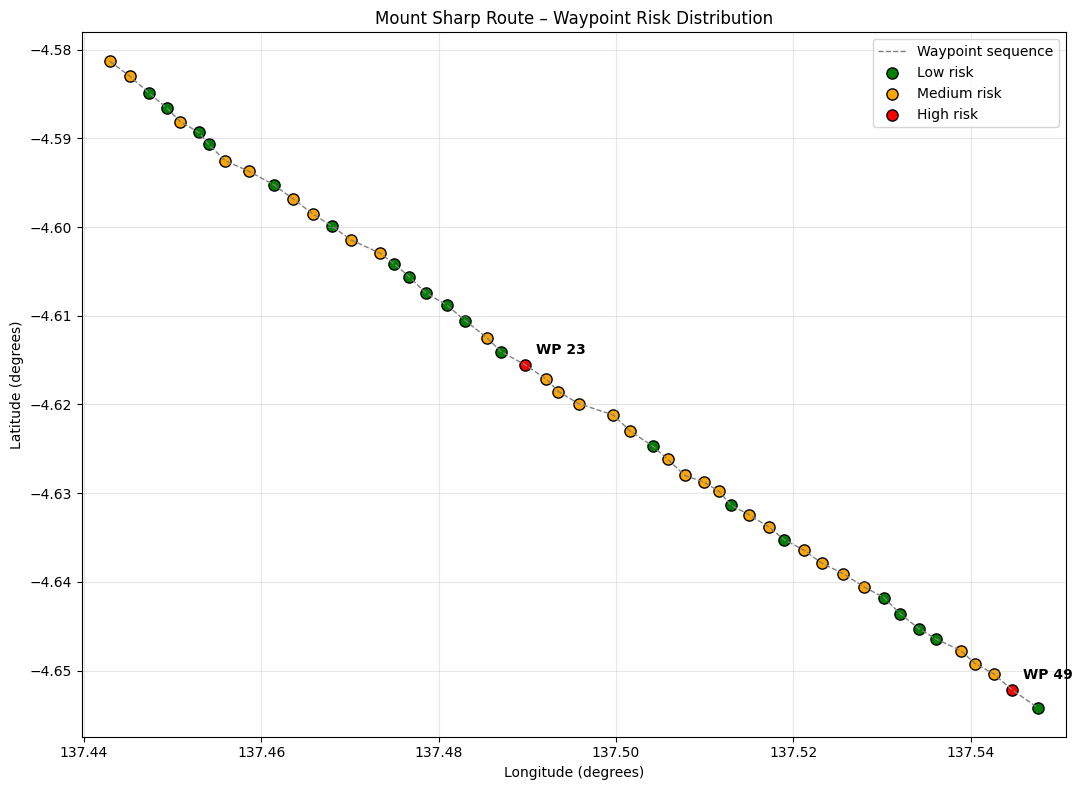

In [122]:
# STEP 15: PLOT THE MOUNT SHARP ROUTE
# Purpose: Visualize waypoint locations and
# their supplied risk classifications
# ==========================================

# Create a figure for the route
plt.figure(figsize=(11, 8))

# Draw a line connecting the waypoints in route order
plt.plot(
    waypoints_df["Longitude"],
    waypoints_df["Latitude"],
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Waypoint sequence"
)

# Define colors for the supplied risk categories
risk_colors = {
    "Low": "green",
    "Medium": "orange",
    "High": "red"
}

# Plot each risk category separately
for risk, color in risk_colors.items():

    # Select waypoints belonging to this category
    points = waypoints_df[
        waypoints_df["Risk_Level"] == risk
    ]

    # Display their geographic positions
    plt.scatter(
        points["Longitude"],
        points["Latitude"],
        color=color,
        label=f"{risk} risk",
        s=65,
        edgecolors="black"
    )

# Label the two High-risk waypoints
for waypoint_id in [23, 49]:

    point = waypoints_df[
        waypoints_df["Waypoint_ID"] == waypoint_id
    ].iloc[0]

    plt.annotate(
        f"WP {waypoint_id}",
        (point["Longitude"], point["Latitude"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

# Add titles and axis labels
plt.title("Mount Sharp Route – Waypoint Risk Distribution")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")

# Display the legend and grid
plt.legend()
plt.grid(alpha=0.3)

# Keep the geographic aspect approximately proportional
plt.gca().set_aspect("equal", adjustable="datalim")

plt.tight_layout()
plt.show()

# =====================================================


In [123]:
# STEP 16: CHECK WAYPOINT COORDINATE EXTENT
# Purpose: Check the geographic boundaries
# covered by our 50 waypoint locations
# ==========================================

# Calculate the minimum and maximum coordinates
# to determine the geographic area covered by the route

print("WAYPOINT GEOGRAPHIC EXTENT")

print(
    "Minimum latitude:",
    waypoints_df["Latitude"].min()
)

print(
    "Maximum latitude:",
    waypoints_df["Latitude"].max()
)

print(
    "Minimum longitude:",
    waypoints_df["Longitude"].min()
)

print(
    "Maximum longitude:",
    waypoints_df["Longitude"].max()
)

# ==========================================


WAYPOINT GEOGRAPHIC EXTENT
Minimum latitude: -4.6542
Maximum latitude: -4.5813
Minimum longitude: 137.44293
Maximum longitude: 137.54758


In [124]:
# STEP 17: VERIFY WAYPOINTS INSIDE MOSAIC
# Purpose: Check whether every waypoint falls
# inside the HiRISE mosaic geographic extent
# ==========================================

# Geographic boundaries of the HiRISE mosaic
mosaic_min_lat = -4.9254743
mosaic_max_lat = -4.2489588

mosaic_min_lon = 137.1224669
mosaic_max_lon = 137.7298129

# Check whether each waypoint is inside the mosaic boundaries
waypoints_df["Inside_Mosaic"] = (
    waypoints_df["Latitude"].between(mosaic_min_lat, mosaic_max_lat)
    &
    waypoints_df["Longitude"].between(mosaic_min_lon, mosaic_max_lon)
)

# Count the waypoints inside and outside the mosaic
inside_count = waypoints_df["Inside_Mosaic"].sum()
outside_count = (~waypoints_df["Inside_Mosaic"]).sum()

print("WAYPOINT COVERAGE CHECK")
print("Waypoints inside mosaic:", inside_count)
print("Waypoints outside mosaic:", outside_count)

# Display any waypoints outside the mosaic
print("\nWaypoints outside mosaic:")
display(
    waypoints_df.loc[
        ~waypoints_df["Inside_Mosaic"],
        ["Waypoint_ID", "Latitude", "Longitude"]
    ]
)

# ==========================================


WAYPOINT COVERAGE CHECK
Waypoints inside mosaic: 50
Waypoints outside mosaic: 0

Waypoints outside mosaic:


,Waypoint_ID,Latitude,Longitude


In [125]:
# STEP 18: PREPARE WAYPOINT MAPPING DATA
# Purpose: Create a clean working copy of the
# waypoint dataset for future spatial analysis
# ==========================================

# Select the fields needed for route mapping
mapping_columns = [
    "Waypoint_ID",
    "Latitude",
    "Longitude",
    "Elevation_m",
    "Slope_deg",
    "Risk_Level"
]

# Create a separate working copy
mapping_df = waypoints_df[mapping_columns].copy()

# Sort the points by waypoint sequence
mapping_df = mapping_df.sort_values("Waypoint_ID")

# Reset the table index for easier handling
mapping_df = mapping_df.reset_index(drop=True)

# Display the prepared mapping dataset
print("Prepared mapping dataset:")
print("Number of waypoints:", len(mapping_df))

display(mapping_df.head(10))

# ==========================================


Prepared mapping dataset:
Number of waypoints: 50


,Waypoint_ID,Latitude,Longitude,Elevation_m,Slope_deg,Risk_Level
0,1,-4.58130,137.44293,-4467.23,16.89,Medium
1,2,-4.58299,137.44520,-4447.79,7.26,Medium
2,3,-4.58489,137.44736,-4433.69,2.88,Low
3,4,-4.58661,137.44941,-4422.50,8.55,Low
4,5,-4.58812,137.45089,-4387.63,7.70,Medium
5,6,-4.58932,137.45297,-4364.01,8.67,Low
6,7,-4.59068,137.45409,-4335.13,9.43,Low
7,8,-4.59252,137.45594,-4306.15,14.21,Medium
8,9,-4.59370,137.45861,-4282.01,13.34,Medium
9,10,-4.59521,137.46140,-4288.45,6.59,Low


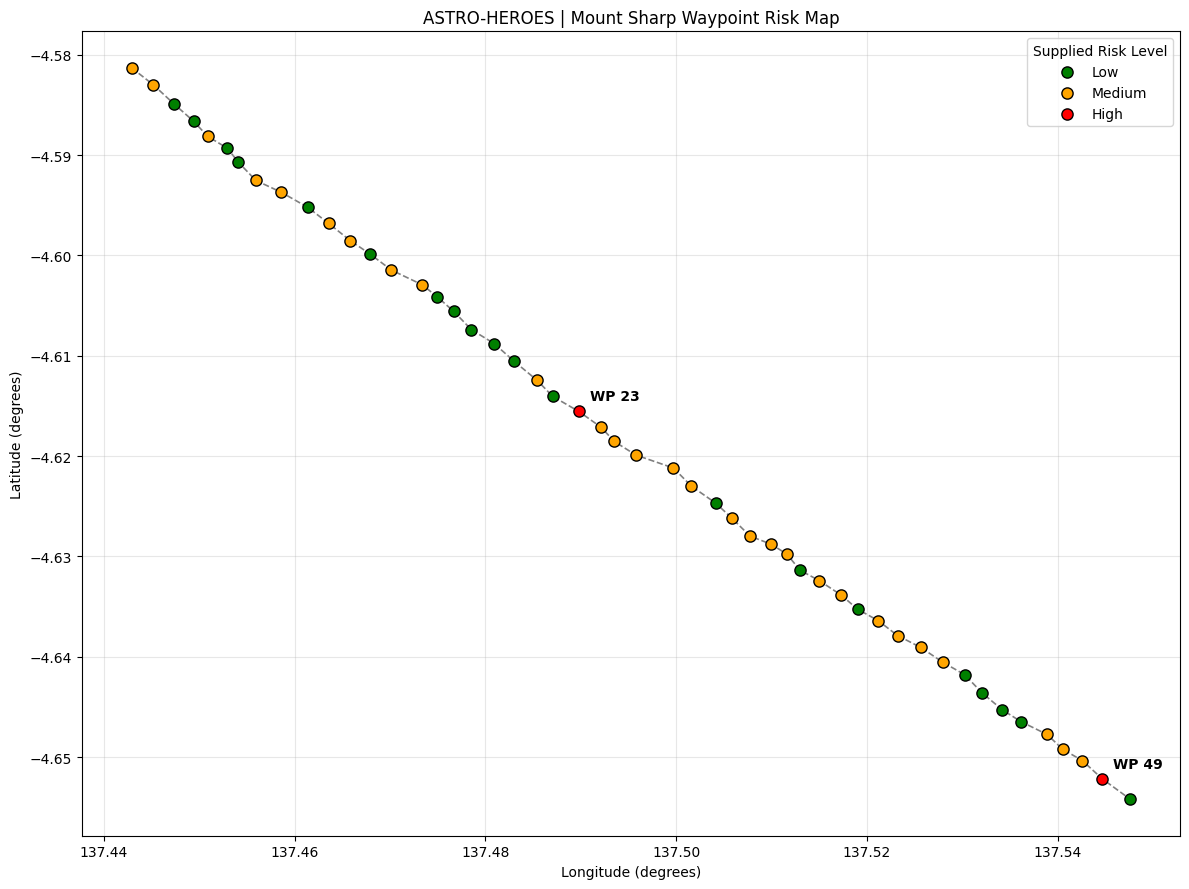

In [126]:
# STEP 19: VISUALIZE THE MOUNT SHARP ROUTE
# Purpose: Create a spatial view of the 50
# waypoints and their supplied risk levels
# ==========================================

# Create a figure
plt.figure(figsize=(12, 9))

# Connect the waypoints in their numerical order
plt.plot(
    mapping_df["Longitude"],
    mapping_df["Latitude"],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    zorder=1
)

# Define colors for the supplied risk categories
risk_colors = {
    "Low": "green",
    "Medium": "orange",
    "High": "red"
}

# Plot each risk category
for risk, color in risk_colors.items():

    points = mapping_df[mapping_df["Risk_Level"] == risk]

    plt.scatter(
        points["Longitude"],
        points["Latitude"],
        color=color,
        label=risk,
        s=65,
        edgecolors="black",
        zorder=2
    )

# Highlight the two High-risk waypoints
for waypoint_id in [23, 49]:

    point = mapping_df[
        mapping_df["Waypoint_ID"] == waypoint_id
    ].iloc[0]

    plt.annotate(
        f"WP {waypoint_id}",
        (point["Longitude"], point["Latitude"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

# Add map labels and title
plt.title("ASTRO-HEROES | Mount Sharp Waypoint Risk Map")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")

# Add legend and grid
plt.legend(title="Supplied Risk Level")
plt.grid(alpha=0.3)

# Display the visualization
plt.tight_layout()
plt.show()

# ==========================================


In [127]:
# STEP 20: CALCULATE WAYPOINT DISTANCES
# Purpose: Measure the horizontal distance
# between consecutive route waypoints
# ==========================================

# Mars's mean radius in kilometres
# Used here only as a spherical distance approximation
MARS_RADIUS_KM = 3389.5

# Convert latitude and longitude from degrees to radians
lat = np.radians(mapping_df["Latitude"].values)
lon = np.radians(mapping_df["Longitude"].values)

# Calculate coordinate differences between consecutive points
delta_lat = np.diff(lat)
delta_lon = np.diff(lon)

# Apply the Haversine formula
a = (
    np.sin(delta_lat / 2) ** 2
    + np.cos(lat[:-1]) * np.cos(lat[1:])
    * np.sin(delta_lon / 2) ** 2
)

central_angle = 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

# Calculate horizontal distances in kilometres
distances_km = MARS_RADIUS_KM * central_angle

# Add the distances to a separate table
distance_df = pd.DataFrame({
    "From_Waypoint": mapping_df["Waypoint_ID"].iloc[:-1].values,
    "To_Waypoint": mapping_df["Waypoint_ID"].iloc[1:].values,
    "Distance_km": distances_km
})

# Display the first ten distances
print("DISTANCES BETWEEN CONSECUTIVE WAYPOINTS:")
display(distance_df.head(10).round(3))

# Summarize waypoint spacing
print("\nDISTANCE SUMMARY:")
print(distance_df["Distance_km"].describe().round(3))

# ==========================================


DISTANCES BETWEEN CONSECUTIVE WAYPOINTS:


,From_Waypoint,To_Waypoint,Distance_km
0,1,2,0.167
1,2,3,0.170
2,3,4,0.158
3,4,5,0.125
4,5,6,0.142
5,6,7,0.104
6,7,8,0.154
7,8,9,0.172
8,9,10,0.187
9,10,11,0.159



DISTANCE SUMMARY:
count    49.000
mean      0.155
std       0.026
min       0.104
25%       0.135
50%       0.157
75%       0.167
max       0.244
Name: Distance_km, dtype: float64


In [128]:
# STEP 21: CALCULATE CUMULATIVE ROUTE DISTANCE
# Purpose: Determine the distance travelled
# from the starting waypoint to each point
# ==========================================

# Create a copy of the mapping dataset
route_analysis_df = mapping_df.copy()

# The first waypoint is our starting point
# Its cumulative distance is therefore zero
route_analysis_df["Cumulative_Distance_km"] = 0.0

# Calculate cumulative distance using the intervals
route_analysis_df.loc[1:, "Cumulative_Distance_km"] = (
    distance_df["Distance_km"].cumsum().values
)

# Display the route distance and elevation information
print("ROUTE DISTANCE AND ELEVATION:")

display(
    route_analysis_df[
        [
            "Waypoint_ID",
            "Cumulative_Distance_km",
            "Elevation_m",
            "Slope_deg"
        ]
    ].head(10).round(3)
)

# Display the total approximate route length
total_distance = route_analysis_df[
    "Cumulative_Distance_km"
].iloc[-1]

print(f"\nTotal approximate route length: {total_distance:.3f} km")

# ==========================================


ROUTE DISTANCE AND ELEVATION:


,Waypoint_ID,Cumulative_Distance_km,Elevation_m,Slope_deg
0,1,0.000,-4467.23,16.89
1,2,0.167,-4447.79,7.26
2,3,0.337,-4433.69,2.88
3,4,0.495,-4422.50,8.55
4,5,0.620,-4387.63,7.70
5,6,0.762,-4364.01,8.67
6,7,0.866,-4335.13,9.43
7,8,1.020,-4306.15,14.21
8,9,1.192,-4282.01,13.34
9,10,1.379,-4288.45,6.59



Total approximate route length: 7.595 km


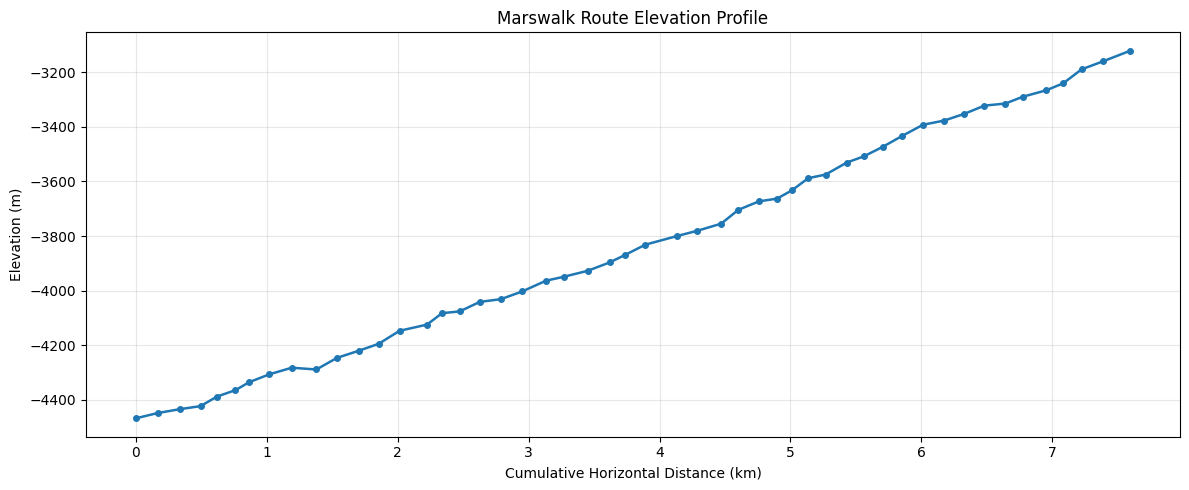

In [129]:
# STEP 22: CREATE THE ELEVATION PROFILE
# Purpose: Visualize elevation changes along
# the route using cumulative distance
# ==========================================

plt.figure(figsize=(12, 5))

# Plot elevation against cumulative route distance
plt.plot(
    route_analysis_df["Cumulative_Distance_km"],
    route_analysis_df["Elevation_m"],
    marker="o",
    linewidth=1.8,
    markersize=4
)

# Label the axes
plt.xlabel("Cumulative Horizontal Distance (km)")
plt.ylabel("Elevation (m)")

# Add a descriptive title
plt.title("Marswalk Route Elevation Profile")

# Add a grid to make elevation changes easier to read
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================


In [130]:
# STEP 23: CALCULATE ELEVATION CHANGES
# Purpose: Identify elevation gains and losses
# between consecutive waypoints
# ==========================================

# Calculate the elevation difference between
# each waypoint and the previous waypoint
route_analysis_df["Elevation_Change_m"] = (
    route_analysis_df["Elevation_m"].diff()
)

# Positive values indicate an increase in elevation
# Negative values indicate a decrease in elevation

# Find the largest elevation gain
largest_gain = route_analysis_df.loc[
    route_analysis_df["Elevation_Change_m"].idxmax()
]

# Find the largest elevation loss
largest_loss = route_analysis_df.loc[
    route_analysis_df["Elevation_Change_m"].idxmin()
]

print("LARGEST ELEVATION GAIN:")
display(largest_gain[[
    "Waypoint_ID",
    "Elevation_Change_m",
    "Cumulative_Distance_km"
]])

print("\nLARGEST ELEVATION LOSS:")
display(largest_loss[[
    "Waypoint_ID",
    "Elevation_Change_m",
    "Cumulative_Distance_km"
]])

# Display the first 10 elevation changes
print("\nFIRST 10 ELEVATION CHANGES:")
display(
    route_analysis_df[
        ["Waypoint_ID", "Elevation_m", "Elevation_Change_m"]
    ].head(10).round(2)
)

# ==========================================


LARGEST ELEVATION GAIN:


,47
Waypoint_ID,48
Elevation_Change_m,51.28
Cumulative_Distance_km,7.223126



LARGEST ELEVATION LOSS:


,9
Waypoint_ID,10
Elevation_Change_m,-6.44
Cumulative_Distance_km,1.37919



FIRST 10 ELEVATION CHANGES:


,Waypoint_ID,Elevation_m,Elevation_Change_m
0,1,-4467.23,NaN
1,2,-4447.79,19.44
2,3,-4433.69,14.10
3,4,-4422.50,11.19
4,5,-4387.63,34.87
5,6,-4364.01,23.62
6,7,-4335.13,28.88
7,8,-4306.15,28.98
8,9,-4282.01,24.14
9,10,-4288.45,-6.44


In [131]:
# STEP 24: ELEVATION-CHANGE RATE
# Align each elevation change with its
# corresponding waypoint-to-waypoint distance
# ==========================================

# Create a column for the distance of each interval
# The first waypoint has no preceding interval
route_analysis_df["Interval_Distance_km"] = np.nan

# Distance row 0 represents WP1 -> WP2,
# so it must align with the elevation change at WP2
route_analysis_df.loc[1:, "Interval_Distance_km"] = (
    distance_df["Distance_km"].values
)

# Calculate the average elevation-change rate
route_analysis_df["Elevation_Change_Rate_m_per_km"] = (
    route_analysis_df["Elevation_Change_m"]
    / route_analysis_df["Interval_Distance_km"]
)

# Find the largest positive and negative rates
valid_rates = route_analysis_df.dropna(
    subset=["Elevation_Change_Rate_m_per_km"]
)

print("HIGHEST ELEVATION-CHANGE RATE:")
display(
    valid_rates.loc[
        valid_rates["Elevation_Change_Rate_m_per_km"].idxmax(),
        [
            "Waypoint_ID",
            "Elevation_Change_m",
            "Interval_Distance_km",
            "Elevation_Change_Rate_m_per_km"
        ]
    ]
)

print("\nLOWEST ELEVATION-CHANGE RATE:")
display(
    valid_rates.loc[
        valid_rates["Elevation_Change_Rate_m_per_km"].idxmin(),
        [
            "Waypoint_ID",
            "Elevation_Change_m",
            "Interval_Distance_km",
            "Elevation_Change_Rate_m_per_km"
        ]
    ]
)

# Display the five intervals with the largest absolute rates
print("\nFIVE LARGEST ABSOLUTE ELEVATION-CHANGE RATES:")

display(
    valid_rates.assign(
        Absolute_Rate=lambda df:
        df["Elevation_Change_Rate_m_per_km"].abs()
    )
    .nlargest(5, "Absolute_Rate")[
        [
            "Waypoint_ID",
            "Elevation_Change_m",
            "Interval_Distance_km",
            "Elevation_Change_Rate_m_per_km"
        ]
    ].round(3)
)

# ==========================================


HIGHEST ELEVATION-CHANGE RATE:


,29
Waypoint_ID,30
Elevation_Change_m,50.73
Interval_Distance_km,0.131766
Elevation_Change_Rate_m_per_km,384.999422



LOWEST ELEVATION-CHANGE RATE:


,9
Waypoint_ID,10
Elevation_Change_m,-6.44
Interval_Distance_km,0.187207
Elevation_Change_Rate_m_per_km,-34.400405



FIVE LARGEST ABSOLUTE ELEVATION-CHANGE RATES:


,Waypoint_ID,Elevation_Change_m,Interval_Distance_km,Elevation_Change_Rate_m_per_km
29,30,50.73,0.132,384.999
15,16,41.83,0.115,365.202
47,48,51.28,0.141,363.555
33,34,44.59,0.125,357.230
13,14,47.63,0.160,298.530


In [132]:
# STEP 25: COMPARE INTERVAL SLOPE WITH
# SUPPLIED WAYPOINT SLOPE
# ==========================================

# Convert elevation-change rate into an angle.
# The rate is in metres per kilometre, so divide by 1000.
route_analysis_df["Average_Interval_Angle_deg"] = np.degrees(
    np.arctan(
        route_analysis_df["Elevation_Change_Rate_m_per_km"] / 1000
    )
)

# Display the largest elevation-change intervals
comparison_df = route_analysis_df.loc[
    valid_rates.nlargest(
        5, "Elevation_Change_Rate_m_per_km"
    ).index,
    [
        "Waypoint_ID",
        "Elevation_Change_m",
        "Interval_Distance_km",
        "Average_Interval_Angle_deg",
        "Slope_deg"
    ]
]

print("INTERVAL ANGLE VS SUPPLIED WAYPOINT SLOPE:")

display(comparison_df.round(2))

# ==========================================


INTERVAL ANGLE VS SUPPLIED WAYPOINT SLOPE:


,Waypoint_ID,Elevation_Change_m,Interval_Distance_km,Average_Interval_Angle_deg,Slope_deg
29,30,50.73,0.13,21.06,17.36
15,16,41.83,0.11,20.06,8.46
47,48,51.28,0.14,19.98,12.43
33,34,44.59,0.12,19.66,8.91
13,14,47.63,0.16,16.62,15.14


In [133]:
# STEP 26: PREPARE MOBILITY ANALYSIS DATA
# Purpose: Extract the parameters relevant
# to astronaut mobility along the route
# ==========================================

# Select waypoint and mobility measurements
mobility_df = waypoints_df[
    [
        "Waypoint_ID",
        "Latitude",
        "Longitude",
        "Boot_Sinkage_cm",
        "Traction_Coefficient",
        "Dynamic_Stability_Index",
        "Risk_Level"
    ]
].copy()

# Sort the records in route order
mobility_df = mobility_df.sort_values(
    "Waypoint_ID"
).reset_index(drop=True)

# Display the first 10 waypoints
print("MOBILITY DATA — FIRST 10 WAYPOINTS:")

display(mobility_df.head(10))

# Check the number of records
print("\nTotal waypoints:", len(mobility_df))

# ==========================================


MOBILITY DATA — FIRST 10 WAYPOINTS:


,Waypoint_ID,Latitude,Longitude,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Risk_Level
0,1,-4.58130,137.44293,8.47,0.628,0.757,Medium
1,2,-4.58299,137.44520,5.19,0.638,0.751,Medium
2,3,-4.58489,137.44736,4.91,0.839,0.946,Low
3,4,-4.58661,137.44941,4.70,0.748,0.793,Low
4,5,-4.58812,137.45089,5.33,0.628,0.766,Medium
5,6,-4.58932,137.45297,3.69,0.712,0.799,Low
6,7,-4.59068,137.45409,4.96,0.807,0.873,Low
7,8,-4.59252,137.45594,7.11,0.672,0.649,Medium
8,9,-4.59370,137.45861,7.77,0.648,0.755,Medium
9,10,-4.59521,137.46140,4.74,0.777,0.874,Low



Total waypoints: 50


In [134]:
# STEP 27: MOBILITY PARAMETER STATISTICS
# Purpose: Understand the overall range and
# variation of mobility conditions
# ==========================================

mobility_columns = [
    "Boot_Sinkage_cm",
    "Traction_Coefficient",
    "Dynamic_Stability_Index"
]

# Calculate descriptive statistics for all 50 waypoints
mobility_stats = mobility_df[mobility_columns].describe()

print("MOBILITY PARAMETER STATISTICS:")

display(mobility_stats.round(3))

# Identify the waypoint with the highest sinkage
highest_sinkage = mobility_df.loc[
    mobility_df["Boot_Sinkage_cm"].idxmax()
]

# Identify the waypoint with the lowest traction
lowest_traction = mobility_df.loc[
    mobility_df["Traction_Coefficient"].idxmin()
]

# Identify the waypoint with the lowest stability
lowest_stability = mobility_df.loc[
    mobility_df["Dynamic_Stability_Index"].idxmin()
]

print("\nHIGHEST BOOT SINKAGE:")
display(highest_sinkage[
    ["Waypoint_ID", "Boot_Sinkage_cm", "Risk_Level"]
])

print("\nLOWEST TRACTION:")
display(lowest_traction[
    ["Waypoint_ID", "Traction_Coefficient", "Risk_Level"]
])

print("\nLOWEST DYNAMIC STABILITY:")
display(lowest_stability[
    ["Waypoint_ID", "Dynamic_Stability_Index", "Risk_Level"]
])

# ==========================================


MOBILITY PARAMETER STATISTICS:


,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index
count,50.000,50.000,50.000
mean,6.130,0.727,0.780
std,1.853,0.097,0.104
min,1.780,0.548,0.530
25%,4.760,0.650,0.751
50%,6.025,0.716,0.770
75%,7.248,0.805,0.855
max,10.300,0.948,0.987



HIGHEST BOOT SINKAGE:


,22
Waypoint_ID,23
Boot_Sinkage_cm,10.3
Risk_Level,High



LOWEST TRACTION:


,22
Waypoint_ID,23
Traction_Coefficient,0.548
Risk_Level,High



LOWEST DYNAMIC STABILITY:


,32
Waypoint_ID,33
Dynamic_Stability_Index,0.53
Risk_Level,Medium


In [135]:
# STEP 28: SLOPE AND MOBILITY RELATIONSHIPS
# Purpose: Examine how terrain slope relates
# to the three mobility parameters
# ==========================================

# Add the supplied slope measurements to our
# mobility working dataset using waypoint IDs
slope_mobility_df = mobility_df.merge(
    waypoints_df[["Waypoint_ID", "Slope_deg"]],
    on="Waypoint_ID",
    how="left"
)

# Select the four parameters for comparison
comparison_columns = [
    "Slope_deg",
    "Boot_Sinkage_cm",
    "Traction_Coefficient",
    "Dynamic_Stability_Index"
]

# Calculate Pearson correlation
# This measures linear relationships
pearson_corr = slope_mobility_df[
    comparison_columns
].corr(method="pearson")

print("PEARSON CORRELATION:")
display(pearson_corr.round(3))

# Calculate Spearman correlation
# This measures whether variables tend to
# increase or decrease together, including
# relationships that may not be linear
spearman_corr = slope_mobility_df[
    comparison_columns
].corr(method="spearman")

print("\nSPEARMAN CORRELATION:")
display(spearman_corr.round(3))

# ==========================================


PEARSON CORRELATION:


,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index
Slope_deg,1.000,0.751,-0.706,-0.802
Boot_Sinkage_cm,0.751,1.000,-0.563,-0.596
Traction_Coefficient,-0.706,-0.563,1.000,0.546
Dynamic_Stability_Index,-0.802,-0.596,0.546,1.000



SPEARMAN CORRELATION:


,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index
Slope_deg,1.000,0.744,-0.679,-0.748
Boot_Sinkage_cm,0.744,1.000,-0.570,-0.583
Traction_Coefficient,-0.679,-0.570,1.000,0.553
Dynamic_Stability_Index,-0.748,-0.583,0.553,1.000


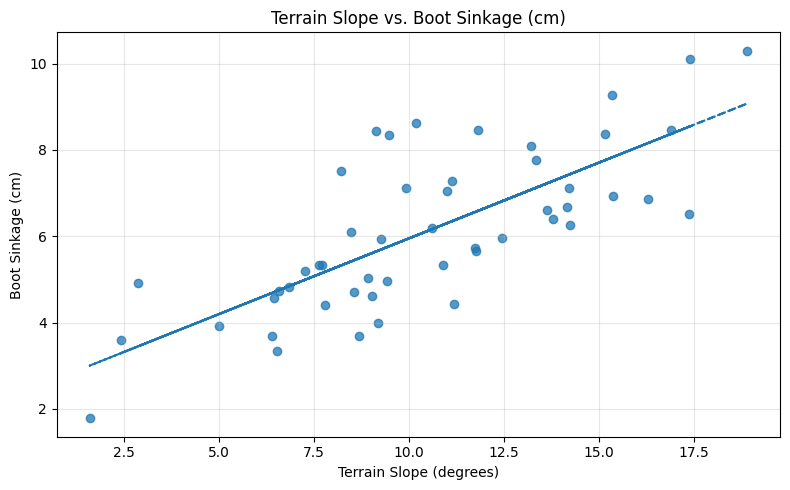

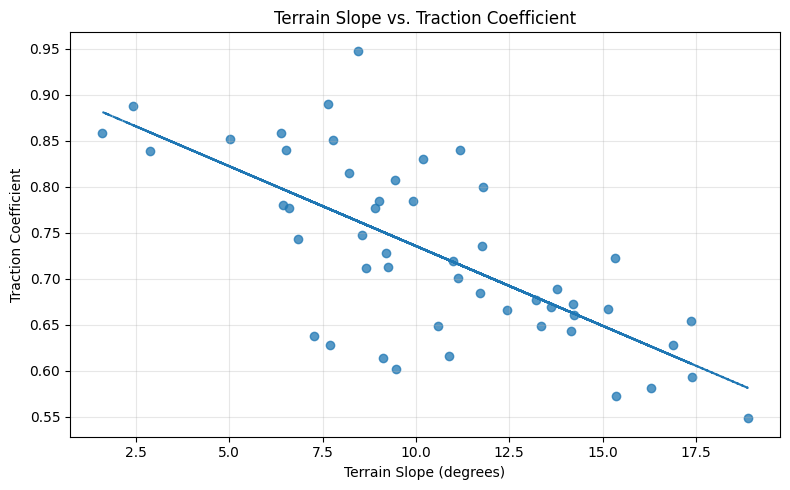

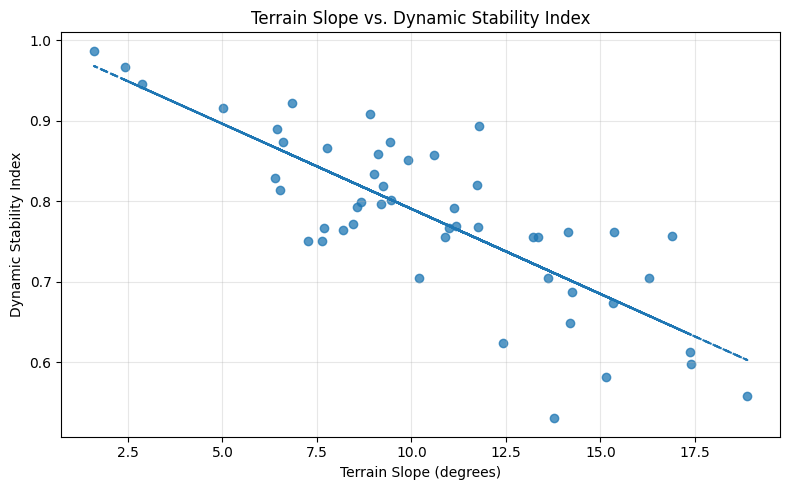

In [136]:
# STEP 29: VISUALIZE SLOPE-MOBILITY RELATIONSHIPS
# Purpose: Examine the relationships visually
# ==========================================

# Define the three mobility parameters to compare
mobility_parameters = [
    ("Boot_Sinkage_cm", "Boot Sinkage (cm)"),
    ("Traction_Coefficient", "Traction Coefficient"),
    ("Dynamic_Stability_Index", "Dynamic Stability Index")
]

# Create one scatterplot for each parameter
for column, label in mobility_parameters:

    plt.figure(figsize=(8, 5))

    # Plot slope against the selected mobility parameter
    plt.scatter(
        slope_mobility_df["Slope_deg"],
        slope_mobility_df[column],
        alpha=0.75
    )

    # Add a best-fit linear trend line
    x = slope_mobility_df["Slope_deg"]
    y = slope_mobility_df[column]

    coefficients = np.polyfit(x, y, 1)
    trend_line = np.poly1d(coefficients)

    plt.plot(
        x,
        trend_line(x),
        linestyle="--"
    )

    plt.xlabel("Terrain Slope (degrees)")
    plt.ylabel(label)
    plt.title(f"Terrain Slope vs. {label}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ==========================================


In [137]:
# STEP 30: IDENTIFY CRITICAL MOBILITY POINTS
# Purpose: Find locations with the most
# challenging values for each mobility factor
# ==========================================

# 1. Ten waypoints with the highest boot sinkage
highest_sinkage_points = mobility_df.nlargest(
    10, "Boot_Sinkage_cm"
)

# 2. Ten waypoints with the lowest traction
lowest_traction_points = mobility_df.nsmallest(
    10, "Traction_Coefficient"
)

# 3. Ten waypoints with the lowest stability
lowest_stability_points = mobility_df.nsmallest(
    10, "Dynamic_Stability_Index"
)

# Display the results
print("TOP 10 WAYPOINTS — HIGHEST BOOT SINKAGE")

display(
    highest_sinkage_points[
        ["Waypoint_ID", "Boot_Sinkage_cm", "Risk_Level"]
    ].reset_index(drop=True)
)

print("\nTOP 10 WAYPOINTS — LOWEST TRACTION")

display(
    lowest_traction_points[
        ["Waypoint_ID", "Traction_Coefficient", "Risk_Level"]
    ].reset_index(drop=True)
)

print("\nTOP 10 WAYPOINTS — LOWEST DYNAMIC STABILITY")

display(
    lowest_stability_points[
        ["Waypoint_ID", "Dynamic_Stability_Index", "Risk_Level"]
    ].reset_index(drop=True)
)

# ==========================================


TOP 10 WAYPOINTS — HIGHEST BOOT SINKAGE


,Waypoint_ID,Boot_Sinkage_cm,Risk_Level
0,23,10.30,High
1,49,10.10,High
2,27,9.28,Medium
3,32,8.62,Medium
4,1,8.47,Medium
5,47,8.46,Medium
6,28,8.43,Medium
7,14,8.36,Medium
8,36,8.35,Medium
9,40,8.10,Medium



TOP 10 WAYPOINTS — LOWEST TRACTION


,Waypoint_ID,Traction_Coefficient,Risk_Level
0,23,0.548,High
1,41,0.572,Medium
2,26,0.581,Medium
3,49,0.593,High
4,36,0.602,Medium
5,28,0.614,Medium
6,24,0.616,Medium
7,1,0.628,Medium
8,5,0.628,Medium
9,2,0.638,Medium



TOP 10 WAYPOINTS — LOWEST DYNAMIC STABILITY


,Waypoint_ID,Dynamic_Stability_Index,Risk_Level
0,33,0.530,Medium
1,23,0.558,High
2,14,0.582,Medium
3,49,0.598,High
4,30,0.613,Medium
5,48,0.624,Medium
6,8,0.649,Medium
7,27,0.674,Medium
8,31,0.687,Medium
9,12,0.704,Medium


In [138]:
# STEP 31: COMBINE MOBILITY PRIORITY INDICATORS
# Purpose: Identify waypoints appearing in
# multiple unfavorable mobility rankings
# ==========================================

# Identify waypoint IDs appearing in each top-10 list
sinkage_ids = set(highest_sinkage_points["Waypoint_ID"])
traction_ids = set(lowest_traction_points["Waypoint_ID"])
stability_ids = set(lowest_stability_points["Waypoint_ID"])

# Start with a copy of the mobility dataset
priority_df = mobility_df.copy()

# Mark whether each waypoint appears in each list
priority_df["High_Sinkage_Flag"] = (
    priority_df["Waypoint_ID"].isin(sinkage_ids)
)

priority_df["Low_Traction_Flag"] = (
    priority_df["Waypoint_ID"].isin(traction_ids)
)

priority_df["Low_Stability_Flag"] = (
    priority_df["Waypoint_ID"].isin(stability_ids)
)

# Count the number of unfavorable indicators
priority_df["Unfavorable_Indicator_Count"] = (
    priority_df[
        [
            "High_Sinkage_Flag",
            "Low_Traction_Flag",
            "Low_Stability_Flag"
        ]
    ].sum(axis=1)
)

# Sort from the most overlapping indicators to the least
priority_df = priority_df.sort_values(
    ["Unfavorable_Indicator_Count", "Waypoint_ID"],
    ascending=[False, True]
)

# Display waypoints with at least two indicators
print("WAYPOINTS WITH TWO OR MORE UNFAVORABLE INDICATORS:")

display(
    priority_df[
        priority_df["Unfavorable_Indicator_Count"] >= 2
    ][
        [
            "Waypoint_ID",
            "Boot_Sinkage_cm",
            "Traction_Coefficient",
            "Dynamic_Stability_Index",
            "Unfavorable_Indicator_Count",
            "Risk_Level"
        ]
    ].reset_index(drop=True).round(3)
)

# Count how many waypoints have 1, 2, or 3 indicators
print("\nINDICATOR OVERLAP SUMMARY:")

display(
    priority_df["Unfavorable_Indicator_Count"]
    .value_counts()
    .sort_index()
    .rename_axis("Number_of_Indicators")
    .to_frame("Number_of_Waypoints")
)

# ==========================================


WAYPOINTS WITH TWO OR MORE UNFAVORABLE INDICATORS:


,Waypoint_ID,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Unfavorable_Indicator_Count,Risk_Level
0,23,10.30,0.548,0.558,3,High
1,49,10.10,0.593,0.598,3,High
2,1,8.47,0.628,0.757,2,Medium
3,14,8.36,0.667,0.582,2,Medium
4,27,9.28,0.722,0.674,2,Medium
5,28,8.43,0.614,0.859,2,Medium
6,36,8.35,0.602,0.801,2,Medium



INDICATOR OVERLAP SUMMARY:


,Number_of_Waypoints
Number_of_Indicators,
0,29
1,14
2,5
3,2


In [139]:
# STEP 32: EXTRACT CRITICAL WAYPOINTS
# Purpose: Prepare the selected locations
# for spatial visualization and investigation
# ==========================================

# Waypoints appearing in at least two
# of the three unfavorable indicator lists
critical_ids = [23, 49, 1, 14, 27, 28, 36]

# Extract their location and engineering data
critical_waypoints_df = waypoints_df[
    waypoints_df["Waypoint_ID"].isin(critical_ids)
][
    [
        "Waypoint_ID",
        "Latitude",
        "Longitude",
        "Elevation_m",
        "Slope_deg",
        "Boot_Sinkage_cm",
        "Traction_Coefficient",
        "Dynamic_Stability_Index",
        "Risk_Level"
    ]
].copy()

# Sort by waypoint order along the route
critical_waypoints_df = critical_waypoints_df.sort_values(
    "Waypoint_ID"
).reset_index(drop=True)

# Display the extracted dataset
display(critical_waypoints_df)

# ==========================================


,Waypoint_ID,Latitude,Longitude,Elevation_m,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Risk_Level
0,1,-4.58130,137.44293,-4467.23,16.89,8.47,0.628,0.757,Medium
1,14,-4.60146,137.47016,-4146.86,15.14,8.36,0.667,0.582,Medium
2,23,-4.61554,137.48978,-3927.45,18.89,10.30,0.548,0.558,High
3,27,-4.62119,137.49972,-3799.85,15.34,9.28,0.722,0.674,Medium
4,28,-4.62300,137.50160,-3780.67,9.12,8.43,0.614,0.859,Medium
5,36,-4.63387,137.51732,-3531.07,9.47,8.35,0.602,0.801,Medium
6,49,-4.65217,137.54466,-3161.07,17.39,10.10,0.593,0.598,High


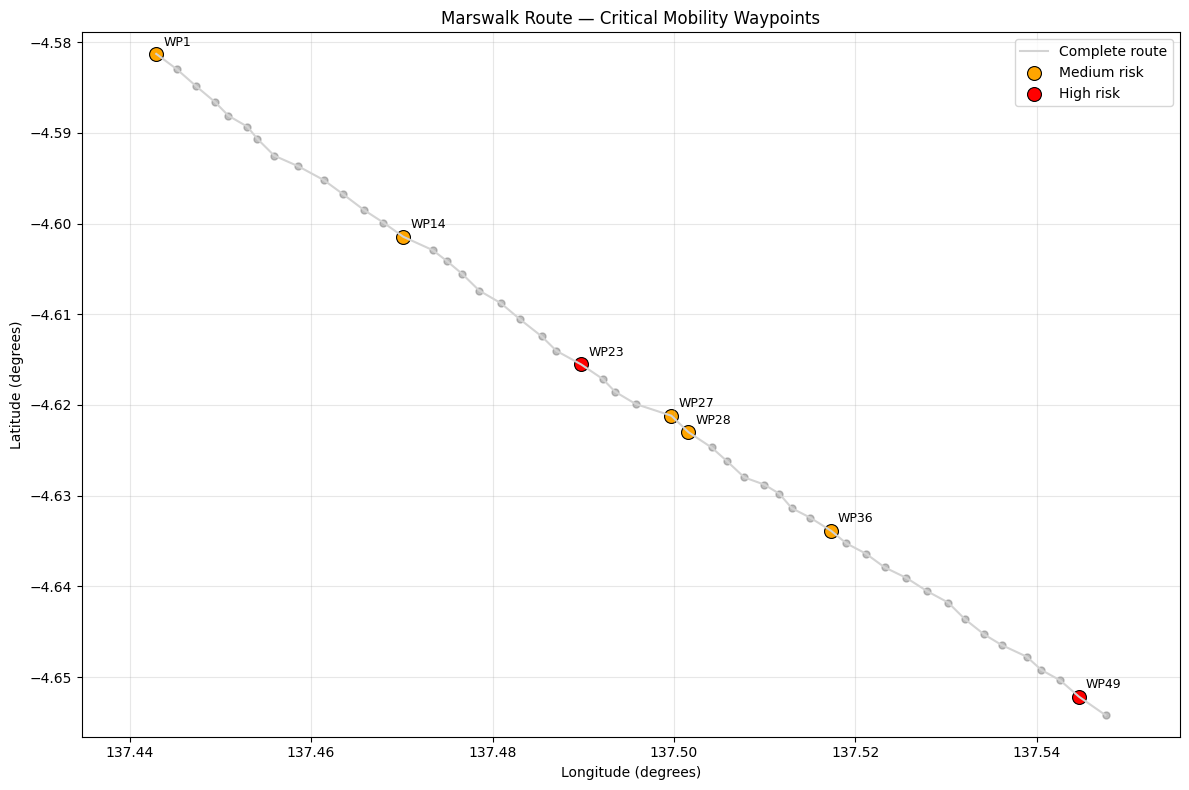

In [140]:
# STEP 33: CRITICAL WAYPOINT LOCATION MAP
# Purpose: Show mobility concern locations
# in relation to the complete route
# ==========================================

plt.figure(figsize=(12, 8))

# Draw the complete route as a light grey line
plt.plot(
    mapping_df["Longitude"],
    mapping_df["Latitude"],
    color="lightgrey",
    linewidth=1.5,
    label="Complete route"
)

# Show all 50 waypoints as small grey points
plt.scatter(
    mapping_df["Longitude"],
    mapping_df["Latitude"],
    color="grey",
    s=25,
    alpha=0.5
)

# Highlight critical waypoints with their supplied risk labels
for risk, color in [("Medium", "orange"), ("High", "red")]:

    subset = critical_waypoints_df[
        critical_waypoints_df["Risk_Level"] == risk
    ]

    plt.scatter(
        subset["Longitude"],
        subset["Latitude"],
        color=color,
        s=100,
        edgecolor="black",
        linewidth=0.8,
        label=f"{risk} risk"
    )

# Label each selected waypoint
for _, point in critical_waypoints_df.iterrows():

    plt.annotate(
        f"WP{int(point['Waypoint_ID'])}",
        (point["Longitude"], point["Latitude"]),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=9
    )

# Add map details
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Marswalk Route — Critical Mobility Waypoints")
plt.grid(alpha=0.3)
plt.legend()
plt.axis("equal")

plt.tight_layout()
plt.show()

# ==========================================


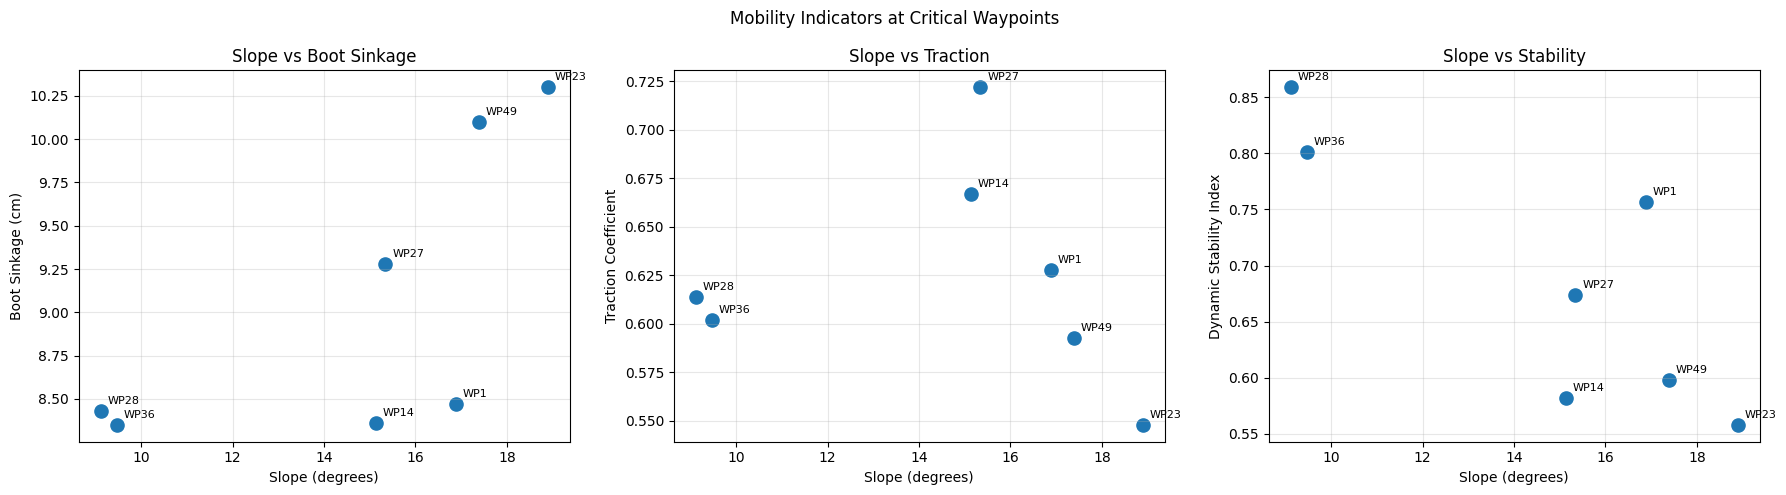

In [141]:
# STEP 34: CRITICAL WAYPOINT COMPARISON
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Define the comparisons explicitly
comparisons = [
    ("Boot_Sinkage_cm", "Boot Sinkage (cm)", "Slope vs Boot Sinkage"),
    ("Traction_Coefficient", "Traction Coefficient", "Slope vs Traction"),
    ("Dynamic_Stability_Index", "Dynamic Stability Index", "Slope vs Stability")
]

# Create the three plots
for ax, (column, y_label, title) in zip(axes, comparisons):

    ax.scatter(
        critical_waypoints_df["Slope_deg"],
        critical_waypoints_df[column],
        s=90
    )

    # Label each point using its waypoint ID
    for _, point in critical_waypoints_df.iterrows():
        ax.annotate(
            f"WP{int(point['Waypoint_ID'])}",
            (point["Slope_deg"], point[column]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_title(title)
    ax.set_xlabel("Slope (degrees)")
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.3)

plt.suptitle("Mobility Indicators at Critical Waypoints")
plt.tight_layout()
plt.show()

# ==========================================


In [142]:
# STEP 35: CONSOLIDATED ENGINEERING TABLE
# Purpose: Prepare a compact table of
# critical terrain and mobility measurements
# ==========================================

engineering_report_df = critical_waypoints_df[
    [
        "Waypoint_ID",
        "Latitude",
        "Longitude",
        "Elevation_m",
        "Slope_deg",
        "Boot_Sinkage_cm",
        "Traction_Coefficient",
        "Dynamic_Stability_Index",
        "Risk_Level"
    ]
].copy()

# Round numerical values for easier reading
engineering_report_df = engineering_report_df.round({
    "Latitude": 5,
    "Longitude": 5,
    "Elevation_m": 2,
    "Slope_deg": 2,
    "Boot_Sinkage_cm": 2,
    "Traction_Coefficient": 3,
    "Dynamic_Stability_Index": 3
})

display(engineering_report_df)


,Waypoint_ID,Latitude,Longitude,Elevation_m,Slope_deg,Boot_Sinkage_cm,Traction_Coefficient,Dynamic_Stability_Index,Risk_Level
0,1,-4.58130,137.44293,-4467.23,16.89,8.47,0.628,0.757,Medium
1,14,-4.60146,137.47016,-4146.86,15.14,8.36,0.667,0.582,Medium
2,23,-4.61554,137.48978,-3927.45,18.89,10.30,0.548,0.558,High
3,27,-4.62119,137.49972,-3799.85,15.34,9.28,0.722,0.674,Medium
4,28,-4.62300,137.50160,-3780.67,9.12,8.43,0.614,0.859,Medium
5,36,-4.63387,137.51732,-3531.07,9.47,8.35,0.602,0.801,Medium
6,49,-4.65217,137.54466,-3161.07,17.39,10.10,0.593,0.598,High


In [143]:
# STEP 36: GEOGRAPHIC PROXIMITY CHECK

# Select coordinates from both datasets.
route_points = waypoints_df[
    ["Waypoint_ID", "Latitude", "Longitude"]
].copy()

gale_points = gale_df[
    ["Point_ID", "Latitude_Deg", "Longitude_Deg"]
].copy()

# Convert coordinates from degrees to radians.
route_lat = np.radians(
    route_points["Latitude"].to_numpy()
)[:, None]

route_lon = np.radians(
    route_points["Longitude"].to_numpy()
)[:, None]

gale_lat = np.radians(
    gale_points["Latitude_Deg"].to_numpy()
)[None, :]

gale_lon = np.radians(
    gale_points["Longitude_Deg"].to_numpy()
)[None, :]

# Calculate great-circle distances using the Haversine formula.
# Mars mean radius = 3,389.5 km.
MARS_RADIUS_KM = 3389.5

dlat = gale_lat - route_lat
dlon = gale_lon - route_lon

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(route_lat) * np.cos(gale_lat)
    * np.sin(dlon / 2) ** 2
)

distances_km = (
    2 * MARS_RADIUS_KM
    * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

# Find the nearest Gale point for each route waypoint.
nearest_indices = np.argmin(distances_km, axis=1)

nearest_distances = distances_km[
    np.arange(len(route_points)),
    nearest_indices
]

# Create the proximity results table.
proximity_df = pd.DataFrame({
    "Waypoint_ID": route_points["Waypoint_ID"].to_numpy(),
    "Nearest_Gale_Point_ID": (
        gale_points["Point_ID"].to_numpy()[nearest_indices]
    ),
    "Distance_to_Nearest_Gale_km": nearest_distances
})

# Display all waypoint results.
print("NEAREST GALE POINT FOR EACH MOUNT SHARP WAYPOINT")
display(proximity_df.round(3))

# Summarize geographic separation.
print("\nGEOGRAPHIC PROXIMITY SUMMARY")
print(f"Closest distance:  {nearest_distances.min():.3f} km")
print(f"Average distance:  {nearest_distances.mean():.3f} km")
print(f"Median distance:   {np.median(nearest_distances):.3f} km")
print(f"Farthest distance: {nearest_distances.max():.3f} km")


NEAREST GALE POINT FOR EACH MOUNT SHARP WAYPOINT


,Waypoint_ID,Nearest_Gale_Point_ID,Distance_to_Nearest_Gale_km
0,1,1,0.137
1,2,2,0.304
2,3,2,0.453
3,4,2,0.601
4,5,2,0.724
5,6,2,0.853
6,7,2,0.957
7,8,3,1.110
8,9,3,1.251
9,10,3,1.419



GEOGRAPHIC PROXIMITY SUMMARY
Closest distance:  0.137 km
Average distance:  3.656 km
Median distance:   3.688 km
Farthest distance: 7.143 km


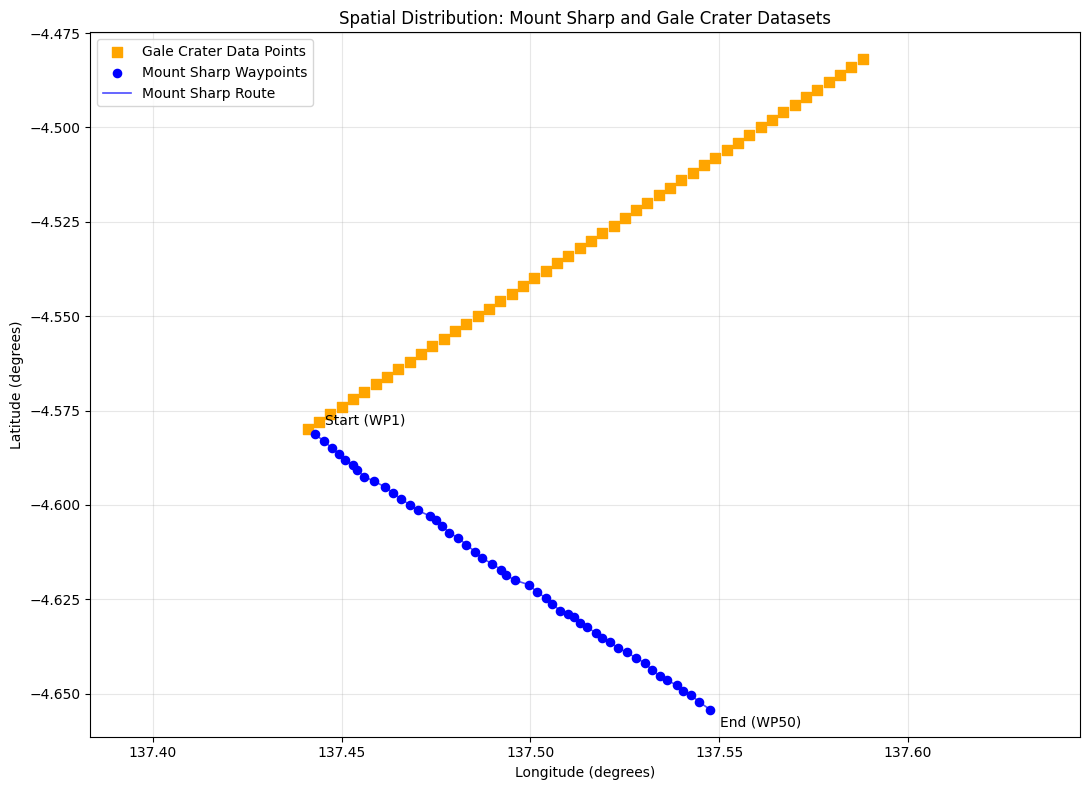

In [144]:
# STEP 37: SPATIAL DISTRIBUTION MAP

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 8))

# Plot Gale Crater sample points.
plt.scatter(
    gale_df["Longitude_Deg"],
    gale_df["Latitude_Deg"],
    color="orange",
    marker="s",
    s=55,
    label="Gale Crater Data Points",
    zorder=2
)

# Plot Mount Sharp waypoints.
plt.scatter(
    waypoints_df["Longitude"],
    waypoints_df["Latitude"],
    color="blue",
    marker="o",
    s=35,
    label="Mount Sharp Waypoints",
    zorder=3
)

# Connect Mount Sharp waypoints in route order.
plt.plot(
    waypoints_df["Longitude"],
    waypoints_df["Latitude"],
    color="blue",
    linewidth=1.2,
    alpha=0.7,
    label="Mount Sharp Route",
    zorder=1
)

# Label the beginning and end of the route.
plt.annotate(
    "Start (WP1)",
    (waypoints_df.iloc[0]["Longitude"],
     waypoints_df.iloc[0]["Latitude"]),
    xytext=(7, 7),
    textcoords="offset points"
)

plt.annotate(
    "End (WP50)",
    (waypoints_df.iloc[-1]["Longitude"],
     waypoints_df.iloc[-1]["Latitude"]),
    xytext=(7, -12),
    textcoords="offset points"
)

plt.title("Spatial Distribution: Mount Sharp and Gale Crater Datasets")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()


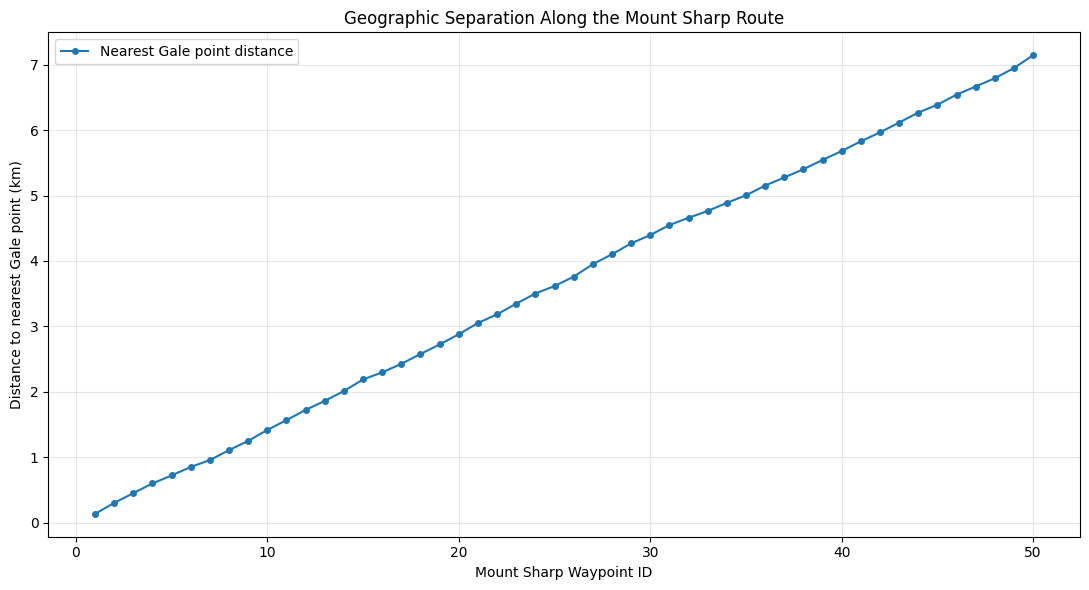

Correlation with waypoint order: 1.000
Interpretation: Strong positive association.


In [145]:
# STEP 38: NEAREST GALE POINT DISTANCE PROFILE

# Sort results by Mount Sharp waypoint order.
distance_profile_df = proximity_df.sort_values(
    "Waypoint_ID"
).copy()

# Calculate the correlation between waypoint order
# and distance to the nearest Gale point.
correlation = distance_profile_df[
    "Waypoint_ID"
].corr(
    distance_profile_df["Distance_to_Nearest_Gale_km"]
)

# Plot the distance profile.
plt.figure(figsize=(11, 6))

plt.plot(
    distance_profile_df["Waypoint_ID"],
    distance_profile_df["Distance_to_Nearest_Gale_km"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Nearest Gale point distance"
)

plt.xlabel("Mount Sharp Waypoint ID")
plt.ylabel("Distance to nearest Gale point (km)")
plt.title("Geographic Separation Along the Mount Sharp Route")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Display the correlation result.
print(f"Correlation with waypoint order: {correlation:.3f}")

if correlation > 0.7:
    print("Interpretation: Strong positive association.")
elif correlation > 0.3:
    print("Interpretation: Moderate positive association.")
elif correlation > 0:
    print("Interpretation: Weak positive association.")
else:
    print("Interpretation: No positive association.")


DISTANCE BETWEEN CONSECUTIVE GALE POINTS


,From_Point_ID,To_Point_ID,Distance_km
0,1,2,0.2128
1,2,3,0.2128
2,3,4,0.2128
3,4,5,0.2128
4,5,6,0.2128
5,6,7,0.2128
6,7,8,0.2128
7,8,9,0.2128
8,9,10,0.2128
9,10,11,0.2128



SPATIAL SAMPLING SUMMARY
Mean spacing:   0.2128 km
Median spacing: 0.2128 km
Minimum:        0.2128 km
Maximum:        0.2128 km
Standard deviation: 0.0000 km


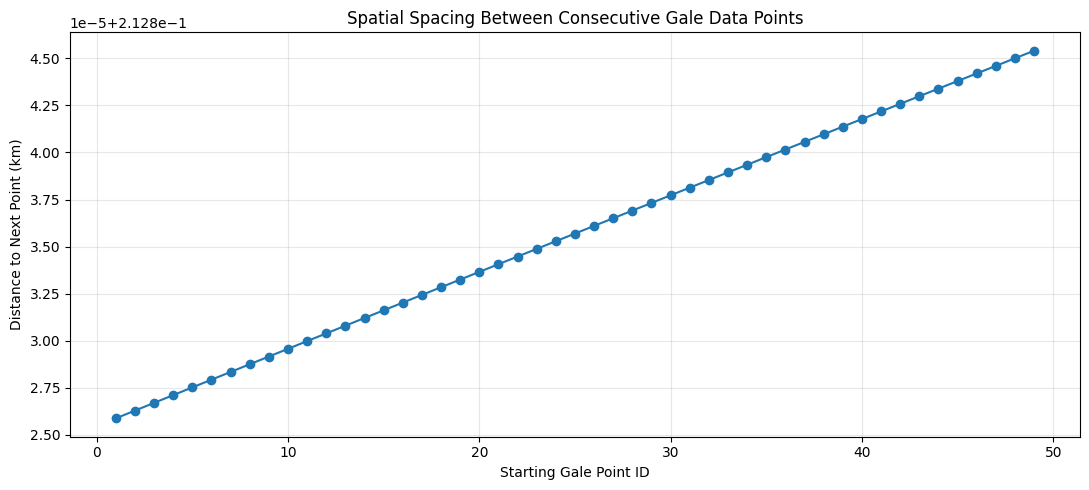

In [146]:
# STEP 39: GALE DATASET SPATIAL SAMPLING ANALYSIS

# Sort Gale points by their IDs.
gale_spacing_df = gale_df.sort_values("Point_ID").copy()
gale_spacing_df = gale_spacing_df.reset_index(drop=True)

# Convert coordinates to radians.
lat = np.radians(gale_spacing_df["Latitude_Deg"].to_numpy())
lon = np.radians(gale_spacing_df["Longitude_Deg"].to_numpy())

# Calculate distances between consecutive Gale points.
MARS_RADIUS_KM = 3389.5

dlat = np.diff(lat)
dlon = np.diff(lon)

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat[:-1]) * np.cos(lat[1:])
    * np.sin(dlon / 2) ** 2
)

consecutive_distances = (
    2 * MARS_RADIUS_KM
    * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

# Create a distance table.
gale_spacing_results = pd.DataFrame({
    "From_Point_ID": gale_spacing_df["Point_ID"].iloc[:-1].to_numpy(),
    "To_Point_ID": gale_spacing_df["Point_ID"].iloc[1:].to_numpy(),
    "Distance_km": consecutive_distances
})

# Display results.
print("DISTANCE BETWEEN CONSECUTIVE GALE POINTS")
display(gale_spacing_results.round(4))

# Calculate spacing statistics.
print("\nSPATIAL SAMPLING SUMMARY")
print(f"Mean spacing:   {np.mean(consecutive_distances):.4f} km")
print(f"Median spacing: {np.median(consecutive_distances):.4f} km")
print(f"Minimum:        {np.min(consecutive_distances):.4f} km")
print(f"Maximum:        {np.max(consecutive_distances):.4f} km")
print(f"Standard deviation: {np.std(consecutive_distances):.4f} km")

# Visualize the spacing pattern.
plt.figure(figsize=(11, 5))

plt.plot(
    gale_spacing_results["From_Point_ID"],
    gale_spacing_results["Distance_km"],
    marker="o",
    linewidth=1.5
)

plt.xlabel("Starting Gale Point ID")
plt.ylabel("Distance to Next Point (km)")
plt.title("Spatial Spacing Between Consecutive Gale Data Points")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [147]:
# STEP 40: GALE COORDINATE INCREMENT ANALYSIS

gale_ordered = gale_df.sort_values("Point_ID").reset_index(drop=True)

# Calculate coordinate changes between consecutive points.
gale_ordered["Latitude_Change"] = (
    gale_ordered["Latitude_Deg"].diff()
)

gale_ordered["Longitude_Change"] = (
    gale_ordered["Longitude_Deg"].diff()
)

print("COORDINATE INCREMENTS BETWEEN CONSECUTIVE POINTS")

display(
    gale_ordered[
        ["Point_ID", "Latitude_Change", "Longitude_Change"]
    ].round(6)
)

print("\nCOORDINATE INCREMENT SUMMARY")

print("\nLatitude change:")
print(gale_ordered["Latitude_Change"].describe())

print("\nLongitude change:")
print(gale_ordered["Longitude_Change"].describe())


COORDINATE INCREMENTS BETWEEN CONSECUTIVE POINTS


,Point_ID,Latitude_Change,Longitude_Change
0,1,NaN,NaN
1,2,0.002,0.003
2,3,0.002,0.003
3,4,0.002,0.003
4,5,0.002,0.003
5,6,0.002,0.003
6,7,0.002,0.003
7,8,0.002,0.003
8,9,0.002,0.003
9,10,0.002,0.003



COORDINATE INCREMENT SUMMARY

Latitude change:
count    4.900000e+01
mean     2.000000e-03
std      3.858985e-16
min      2.000000e-03
25%      2.000000e-03
50%      2.000000e-03
75%      2.000000e-03
max      2.000000e-03
Name: Latitude_Change, dtype: float64

Longitude change:
count    4.900000e+01
mean     3.000000e-03
std      1.435513e-14
min      3.000000e-03
25%      3.000000e-03
50%      3.000000e-03
75%      3.000000e-03
max      3.000000e-03
Name: Longitude_Change, dtype: float64


In [148]:
# STEP 41: GALE TERRAIN ATTRIBUTE PATTERN ANALYSIS

# Numerical attributes to investigate.
gale_numeric_columns = [
    "Elevation_Meters",
    "Slope_Angle_Deg",
    "Radiation_Level_mSv",
    "Temperature_C",
    "Soil_Cohesion_kPa"
]

print("GALE TERRAIN ATTRIBUTE SUMMARY")

display(
    gale_df[gale_numeric_columns].describe().T
)

# Calculate changes between consecutive points.
gale_attribute_changes = gale_df[
    gale_numeric_columns
].diff()

print("\nCONSECUTIVE ATTRIBUTE CHANGES")

display(gale_attribute_changes.round(4))

# Count unique values and unique consecutive increments.
print("\nATTRIBUTE PATTERN SUMMARY")

for column in gale_numeric_columns:
    values = gale_df[column].dropna()
    changes = gale_attribute_changes[column].dropna()

    print(f"\n{column}")
    print("Unique measurement values:", values.nunique())
    print("Unique consecutive increments:", changes.nunique())
    print("Minimum increment:", changes.min())
    print("Maximum increment:", changes.max())


GALE TERRAIN ATTRIBUTE SUMMARY


,count,mean,std,min,25%,50%,75%,max
Elevation_Meters,50.0,-4132.500,218.660696,-4500.00,-4316.2500,-4132.500,-3948.7500,-3765.00
Slope_Angle_Deg,50.0,9.610,3.066757,5.20,6.7000,9.700,12.7000,14.20
Radiation_Level_mSv,50.0,0.895,0.145774,0.65,0.7725,0.895,1.0175,1.14
Temperature_C,50.0,-56.000,2.857143,-60.00,-58.0000,-56.000,-54.0000,-52.00
Soil_Cohesion_kPa,50.0,42.550,2.051008,40.00,40.0000,42.500,45.0000,45.00



CONSECUTIVE ATTRIBUTE CHANGES


,Elevation_Meters,Slope_Angle_Deg,Radiation_Level_mSv,Temperature_C,Soil_Cohesion_kPa
0,NaN,NaN,NaN,NaN,NaN
1,15.0,1.5,0.01,2.0,-2.5
2,15.0,1.5,0.01,2.0,-2.5
3,15.0,1.5,0.01,2.0,5.0
4,15.0,1.5,0.01,2.0,-2.5
5,15.0,1.5,0.01,-8.0,-2.5
6,15.0,1.5,0.01,2.0,5.0
7,15.0,-9.0,0.01,2.0,-2.5
8,15.0,1.5,0.01,2.0,-2.5
9,15.0,1.5,0.01,2.0,5.0



ATTRIBUTE PATTERN SUMMARY

Elevation_Meters
Unique measurement values: 50
Unique consecutive increments: 1
Minimum increment: 15.0
Maximum increment: 15.0

Slope_Angle_Deg
Unique measurement values: 7
Unique consecutive increments: 3
Minimum increment: -9.0
Maximum increment: 1.5

Radiation_Level_mSv
Unique measurement values: 50
Unique consecutive increments: 3
Minimum increment: 0.009999999999999787
Maximum increment: 0.010000000000000009

Temperature_C
Unique measurement values: 5
Unique consecutive increments: 2
Minimum increment: -8.0
Maximum increment: 2.0

Soil_Cohesion_kPa
Unique measurement values: 3
Unique consecutive increments: 2
Minimum increment: -2.5
Maximum increment: 5.0


In [149]:
# STEP 42: GALE DATASET QUALITY ASSESSMENT

gale_quality_assessment = pd.DataFrame({
    "Attribute": [
        "Elevation",
        "Slope",
        "Radiation",
        "Temperature",
        "Soil Cohesion"
    ],
    "Observed_Pattern": [
        "All consecutive increments are +15 m",
        "Only 7 unique measurement values",
        "All consecutive increments are +0.01 mSv",
        "Only 5 unique values with repeating increments",
        "Only 3 unique measurement values"
    ],
    "Engineering_Concern": [
        "Perfectly linear elevation progression",
        "Limited measurement variability",
        "Perfectly linear radiation progression",
        "Repeated measurement pattern",
        "Limited measurement variability"
    ],
    "Verification_Status": [
        "Unverified",
        "Unverified",
        "Unverified",
        "Unverified",
        "Unverified"
    ]
})

print("GALE DATASET QUALITY ASSESSMENT")
display(gale_quality_assessment)


GALE DATASET QUALITY ASSESSMENT


,Attribute,Observed_Pattern,Engineering_Concern,Verification_Status
0,Elevation,All consecutive increments are +15 m,Perfectly linear elevation progression,Unverified
1,Slope,Only 7 unique measurement values,Limited measurement variability,Unverified
2,Radiation,All consecutive increments are +0.01 mSv,Perfectly linear radiation progression,Unverified
3,Temperature,Only 5 unique values with repeating increments,Repeated measurement pattern,Unverified
4,Soil Cohesion,Only 3 unique measurement values,Limited measurement variability,Unverified


In [150]:
# STEP 43: READ NASA MARS TREK WMTS CAPABILITIES

import requests
import xml.etree.ElementTree as ET

capabilities_url = (
    "https://trek.nasa.gov/tiles/Mars/EQ/"
    "Gale_CTX_BlockAdj_dd/1.0.0/WMTSCapabilities.xml"
)

response = requests.get(capabilities_url, timeout=60)

print("HTTP Status:", response.status_code)
print("Content Type:", response.headers.get("Content-Type"))

if response.status_code == 200:

    root = ET.fromstring(response.content)

    namespaces = {
        "wmts": "http://www.opengis.net/wmts/1.0",
        "ows": "http://www.opengis.net/ows/1.1"
    }

    print("\nNASA WMTS SERVICE INFORMATION")

    layers = root.findall(".//wmts:Layer", namespaces)

    for layer in layers:
        identifier = layer.find("ows:Identifier", namespaces)
        title = layer.find("ows:Title", namespaces)

        print("\nLayer:", identifier.text if identifier is not None else "Unknown")
        print("Title:", title.text if title is not None else "Not provided")

        formats = layer.findall("wmts:Format", namespaces)

        print("Available formats:")
        for fmt in formats:
            print("-", fmt.text)

        links = layer.findall("wmts:TileMatrixSetLink", namespaces)

        print("Available tile matrix sets:")
        for link in links:
            matrix = link.find("wmts:TileMatrixSet", namespaces)
            if matrix is not None:
                print("-", matrix.text)

else:
    print("Could not retrieve the capabilities document.")
    print(response.text[:500])


HTTP Status: 200
Content Type: application/xml

NASA WMTS SERVICE INFORMATION

Layer: Gale_CTX_BlockAdj_dd
Title: Gale_CTX_BlockAdj_dd
Available formats:
- image/png
Available tile matrix sets:
- default028mm


In [151]:
# STEP 44: INSPECT NASA WMTS TILE CONFIGURATION

# Find the Gale CTX layer
layer = root.find(".//wmts:Layer", namespaces)

# Find its tile URL template
resource = layer.find("wmts:ResourceURL", namespaces)

if resource is not None:
    print("TILE URL TEMPLATE:")
    print(resource.attrib.get("template"))

# Find the linked tile matrix set
matrix_set = root.find(
    ".//wmts:TileMatrixSet[ows:Identifier='default028mm']",
    namespaces
)

print("\nAVAILABLE ZOOM LEVELS:")

if matrix_set is not None:
    for matrix in matrix_set.findall("wmts:TileMatrix", namespaces):

        identifier = matrix.find("ows:Identifier", namespaces)
        width = matrix.find("wmts:MatrixWidth", namespaces)
        height = matrix.find("wmts:MatrixHeight", namespaces)

        print(
            "Zoom:", identifier.text,
            "| Matrix width:", width.text,
            "| Matrix height:", height.text
        )
else:
    print("Tile matrix set not found.")


TILE URL TEMPLATE:
https://trek.nasa.gov/tiles/Mars/EQ/Gale_CTX_BlockAdj_dd/1.0.0//{Style}/{TileMatrixSet}/{TileMatrix}/{TileRow}/{TileCol}.png

AVAILABLE ZOOM LEVELS:
Zoom: 0 | Matrix width: 2.0 | Matrix height: 1.0
Zoom: 1 | Matrix width: 4.0 | Matrix height: 2.0
Zoom: 2 | Matrix width: 8.0 | Matrix height: 4.0
Zoom: 3 | Matrix width: 16.0 | Matrix height: 8.0
Zoom: 4 | Matrix width: 32.0 | Matrix height: 16.0
Zoom: 5 | Matrix width: 64.0 | Matrix height: 32.0
Zoom: 6 | Matrix width: 128.0 | Matrix height: 64.0
Zoom: 7 | Matrix width: 256.0 | Matrix height: 128.0
Zoom: 8 | Matrix width: 512.0 | Matrix height: 256.0
Zoom: 9 | Matrix width: 1024.0 | Matrix height: 512.0
Zoom: 10 | Matrix width: 2048.0 | Matrix height: 1024.0
Zoom: 11 | Matrix width: 4096.0 | Matrix height: 2048.0
Zoom: 12 | Matrix width: 8192.0 | Matrix height: 4096.0


In [152]:
# STEP 45: INSPECT WMTS PROJECTION AND STYLES

# 1. Identify available styles
print("AVAILABLE STYLES:")

for style in layer.findall("wmts:Style", namespaces):
    identifier = style.find("ows:Identifier", namespaces)
    if identifier is not None:
        print("-", identifier.text)

# 2. Identify the coordinate reference system
print("\nTILE MATRIX SET CRS:")

crs_element = matrix_set.find("ows:SupportedCRS", namespaces)

if crs_element is not None:
    print(crs_element.text)

# 3. Inspect tile dimensions and geographic grid information
print("\nTILE MATRIX DETAILS:")

for matrix in matrix_set.findall("wmts:TileMatrix", namespaces):

    identifier = matrix.find("ows:Identifier", namespaces)
    tile_width = matrix.find("wmts:TileWidth", namespaces)
    tile_height = matrix.find("wmts:TileHeight", namespaces)
    top_left = matrix.find("wmts:TopLeftCorner", namespaces)

    print(
        f"Zoom {identifier.text} | "
        f"Tile size: {tile_width.text} × {tile_height.text} | "
        f"Top-left: {top_left.text}"
    )


AVAILABLE STYLES:
- default

TILE MATRIX SET CRS:
urn:ogc:def:crs:EPSG::104905

TILE MATRIX DETAILS:
Zoom 0 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 1 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 2 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 3 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 4 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 5 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 6 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 7 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 8 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 9 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 10 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 11 | Tile size: 256 × 256 | Top-left: -180.0 90.0
Zoom 12 | Tile size: 256 × 256 | Top-left: -180.0 90.0


In [153]:
# STEP 46: CALCULATE NASA WMTS TILE COORDINATES

import math

# Select zoom level
zoom = 9

# Get route coordinate boundaries
min_lon = waypoints_df["Longitude"].min()
max_lon = waypoints_df["Longitude"].max()

min_lat = waypoints_df["Latitude"].min()
max_lat = waypoints_df["Latitude"].max()

# Calculate tile matrix dimensions
matrix_width = 2 ** (zoom + 1)
matrix_height = 2 ** zoom

# Calculate tile columns
min_col = math.floor((min_lon + 180) / 360 * matrix_width)
max_col = math.floor((max_lon + 180) / 360 * matrix_width)

# Calculate tile rows
min_row = math.floor((90 - max_lat) / 180 * matrix_height)
max_row = math.floor((90 - min_lat) / 180 * matrix_height)

print("MARS ROUTE BOUNDARIES")
print("Longitude:", min_lon, "to", max_lon)
print("Latitude:", min_lat, "to", max_lat)

print("\nNASA WMTS TILE INFORMATION")
print("Zoom level:", zoom)
print("Tile columns:", min_col, "to", max_col)
print("Tile rows:", min_row, "to", max_row)

print("\nTILES REQUIRED:")

for row in range(min_row, max_row + 1):
    for col in range(min_col, max_col + 1):
        print(f"Zoom {zoom} | Row {row} | Column {col}")


MARS ROUTE BOUNDARIES
Longitude: 137.44293 to 137.54758
Latitude: -4.6542 to -4.5813

NASA WMTS TILE INFORMATION
Zoom level: 9
Tile columns: 902 to 903
Tile rows: 269 to 269

TILES REQUIRED:
Zoom 9 | Row 269 | Column 902
Zoom 9 | Row 269 | Column 903



Tile: Row 269, Column 902
HTTP Status: 200
Content Type: image/png
Image dimensions: (256, 256)
Download size: 60333 bytes


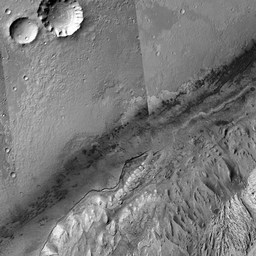


Tile: Row 269, Column 903
HTTP Status: 200
Content Type: image/png
Image dimensions: (256, 256)
Download size: 59365 bytes


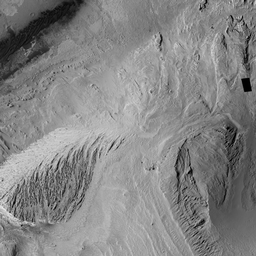


Successfully downloaded tiles: 2


In [154]:
# STEP 47: DOWNLOAD NASA CTX TILES

import requests
from io import BytesIO
from PIL import Image
from IPython.display import display

# NASA WMTS tile service
base_url = (
    "https://trek.nasa.gov/tiles/Mars/EQ/"
    "Gale_CTX_BlockAdj_dd/1.0.0"
)

# Tile configuration
style = "default"
matrix_set = "default028mm"
zoom = 9
row = 269

# The two columns covering our route
columns = [902, 903]

# Store downloaded images
ctx_tiles = {}

for col in columns:

    tile_url = (
        f"{base_url}/{style}/{matrix_set}/"
        f"{zoom}/{row}/{col}.png"
    )

    response = requests.get(tile_url, timeout=60)

    print(f"\nTile: Row {row}, Column {col}")
    print("HTTP Status:", response.status_code)
    print("Content Type:", response.headers.get("Content-Type"))

    if response.status_code == 200:

        tile_image = Image.open(BytesIO(response.content)).convert("RGB")

        ctx_tiles[col] = tile_image

        print("Image dimensions:", tile_image.size)
        print("Download size:", len(response.content), "bytes")

        display(tile_image)

    else:
        print("Tile download failed.")
        print(response.text[:300])

print("\nSuccessfully downloaded tiles:", len(ctx_tiles))


Combined image dimensions: (512, 256)


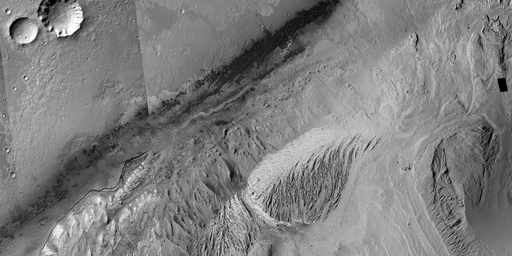

In [155]:
# STEP 48: MERGE NASA CTX TILES

from PIL import Image

# Create a combined image
tile_902 = ctx_tiles[902]
tile_903 = ctx_tiles[903]

combined_ctx = Image.new(
    "RGB",
    (tile_902.width + tile_903.width, tile_902.height)
)

# Place the tiles next to each other
combined_ctx.paste(tile_902, (0, 0))
combined_ctx.paste(tile_903, (tile_902.width, 0))

# Display the result
print("Combined image dimensions:", combined_ctx.size)

display(combined_ctx)


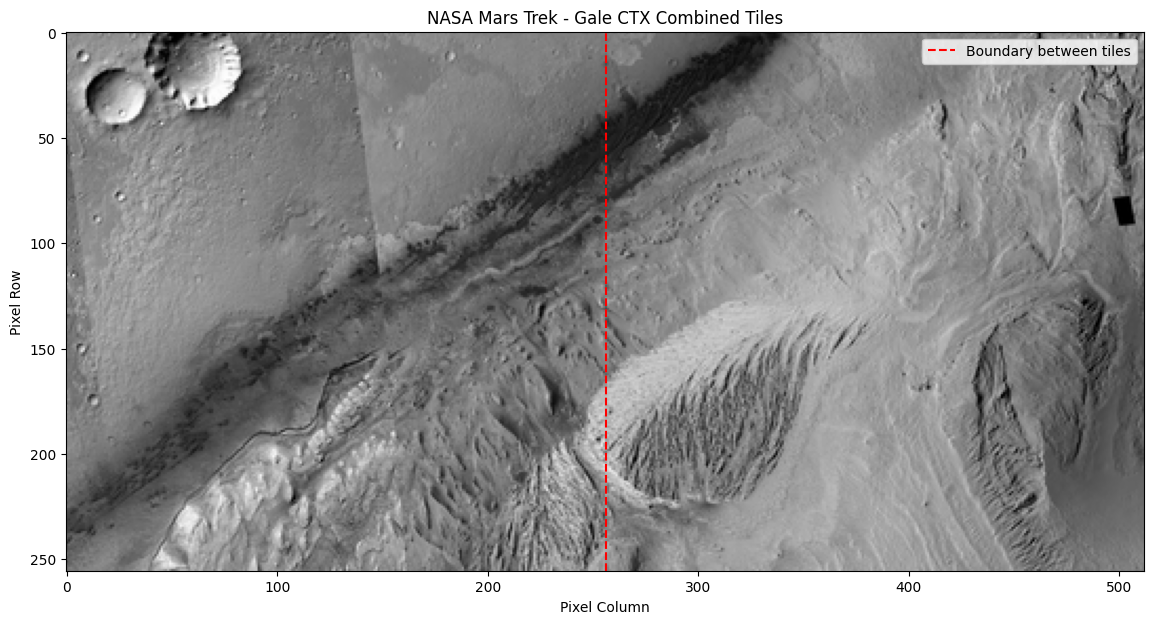

In [156]:
# STEP 49: VISUAL INSPECTION OF COMBINED CTX IMAGE

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

plt.imshow(combined_ctx)

plt.title("NASA Mars Trek - Gale CTX Combined Tiles")
plt.xlabel("Pixel Column")
plt.ylabel("Pixel Row")

plt.axvline(
    x=256,
    color="red",
    linestyle="--",
    label="Boundary between tiles"
)

plt.legend()
plt.grid(False)
plt.show()


In [157]:
# STEP 50: CALCULATE THE GEOGRAPHIC EXTENT OF THE COMBINED IMAGE

# Tile matrix information
matrix_width = 2 ** (zoom + 1)
matrix_height = 2 ** zoom

# Geographic boundaries of the combined tiles
west = (902 / matrix_width) * 360 - 180
east = (904 / matrix_width) * 360 - 180

north = 90 - (269 / matrix_height) * 180
south = 90 - (270 / matrix_height) * 180

print("COMBINED IMAGE GEOGRAPHIC EXTENT")
print("West longitude:", west)
print("East longitude:", east)
print("North latitude:", north)
print("South latitude:", south)

print("\nROUTE COVERAGE CHECK")

print(
    "Route longitude inside image:",
    west <= waypoints_df["Longitude"].min()
    and waypoints_df["Longitude"].max() <= east
)

print(
    "Route latitude inside image:",
    south <= waypoints_df["Latitude"].min()
    and waypoints_df["Latitude"].max() <= north
)


COMBINED IMAGE GEOGRAPHIC EXTENT
West longitude: 137.109375
East longitude: 137.8125
North latitude: -4.5703125
South latitude: -4.921875

ROUTE COVERAGE CHECK
Route longitude inside image: True
Route latitude inside image: True


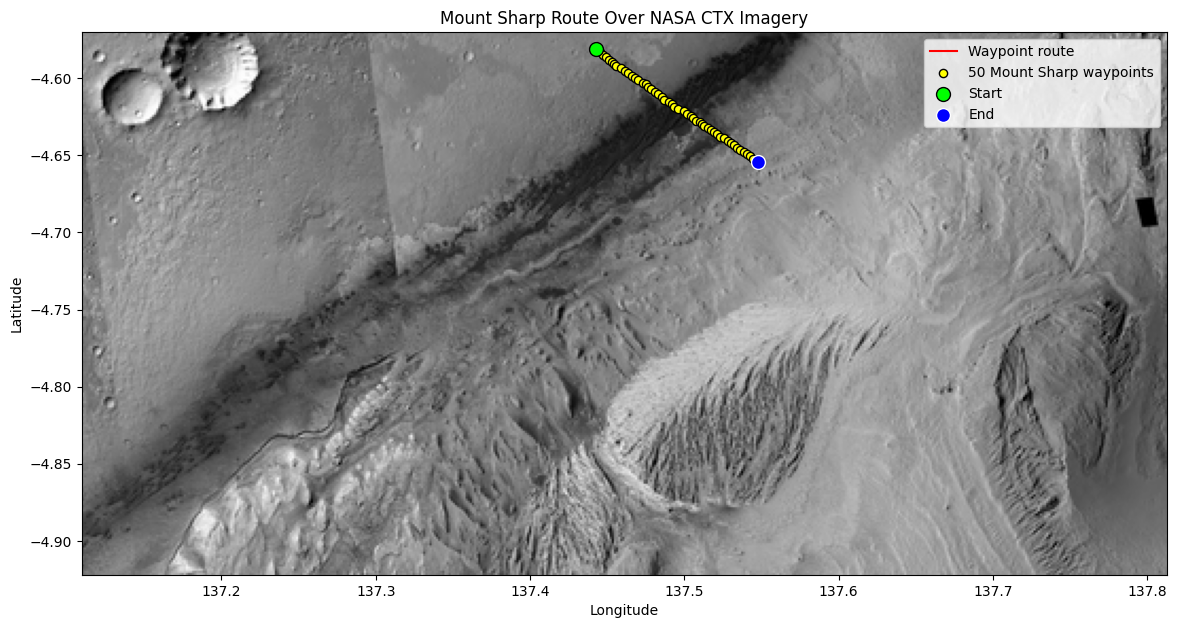

In [158]:
# STEP 51: OVERLAY MOUNT SHARP WAYPOINTS ON NASA CTX IMAGE

import matplotlib.pyplot as plt

# Convert geographic coordinates to image pixel coordinates
waypoints_df["Pixel_X"] = (
    (waypoints_df["Longitude"] - west)
    / (east - west)
    * combined_ctx.width
)

waypoints_df["Pixel_Y"] = (
    (north - waypoints_df["Latitude"])
    / (north - south)
    * combined_ctx.height
)

# Display image and waypoint positions
plt.figure(figsize=(14, 8))

plt.imshow(combined_ctx, extent=[west, east, south, north])

plt.plot(
    waypoints_df["Longitude"],
    waypoints_df["Latitude"],
    color="red",
    linewidth=1.5,
    label="Waypoint route"
)

plt.scatter(
    waypoints_df["Longitude"],
    waypoints_df["Latitude"],
    color="yellow",
    edgecolor="black",
    s=35,
    label="50 Mount Sharp waypoints",
    zorder=3
)

plt.scatter(
    waypoints_df["Longitude"].iloc[0],
    waypoints_df["Latitude"].iloc[0],
    color="lime",
    edgecolor="black",
    s=100,
    label="Start",
    zorder=4
)

plt.scatter(
    waypoints_df["Longitude"].iloc[-1],
    waypoints_df["Latitude"].iloc[-1],
    color="blue",
    edgecolor="white",
    s=100,
    label="End",
    zorder=4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Mount Sharp Route Over NASA CTX Imagery")

plt.legend()
plt.grid(False)
plt.show()


In [159]:
# STEP 52: VERIFY AND SET OUTPUT FOLDER

import os

output_folder = "/content/ASTRO_HEROES/outputs"

os.makedirs(output_folder, exist_ok=True)

print("Output folder:", output_folder)
print("Folder exists:", os.path.exists(output_folder))


Output folder: /content/ASTRO_HEROES/outputs
Folder exists: True


In [160]:
# STEP 53: SAVE COMBINED NASA CTX IMAGE

ctx_output_path = os.path.join(
    output_folder,
    "Mount_Sharp_NASA_CTX_Combined.png"
)

combined_ctx.save(ctx_output_path)

print("Image saved successfully.")
print("File path:", ctx_output_path)
print("Image dimensions:", combined_ctx.size)
print("File size:", round(os.path.getsize(ctx_output_path) / 1024, 2), "KB")


Image saved successfully.
File path: /content/ASTRO_HEROES/outputs/Mount_Sharp_NASA_CTX_Combined.png
Image dimensions: (512, 256)
File size: 157.81 KB


In [161]:
# STEP 54: CHECK GDAL RASTER DRIVERS

import rasterio

with rasterio.Env() as env:

    drivers = env.drivers()

    print("GTiff driver available:", "GTiff" in drivers)
    print("VRT driver available:", "VRT" in drivers)

    print("\nREMOTE RASTER ACCESS ENVIRONMENT")
    print("Rasterio version:", rasterio.__version__)
    print("GDAL version:", rasterio.__gdal_version__)


GTiff driver available: True
VRT driver available: True

REMOTE RASTER ACCESS ENVIRONMENT
Rasterio version: 1.5.2
GDAL version: 3.12.2


In [162]:
# STEP 55: SEARCH USGS FOR MARS CTX ELEVATION MODELS

import requests

# USGS Astrogeology STAC search endpoint
search_url = (
    "https://g6goyz4w56.execute-api.us-west-2.amazonaws.com/"
    "prod/search"
)

# Geographic boundaries of our Mount Sharp route
route_bbox = [
    waypoints_df["Longitude"].min(),
    waypoints_df["Latitude"].min(),
    waypoints_df["Longitude"].max(),
    waypoints_df["Latitude"].max()
]

# Search parameters
search_payload = {
    "collections": ["mro_ctx_controlled_usgs_dtms"],
    "bbox": route_bbox,
    "limit": 100
}

# Send metadata search request
response = requests.post(
    search_url,
    json=search_payload,
    timeout=60
)

print("HTTP Status:", response.status_code)

response.raise_for_status()

if response.status_code == 200:

    search_results = response.json()
    dtm_items = search_results.get("features", [])

    print("DTM products found:", len(dtm_items))

    for item in dtm_items:

        print("\nProduct ID:", item.get("id"))
        print("Geographic coverage:", item.get("bbox"))

        print("Available assets:")

        for asset_name, asset_info in item.get("assets", {}).items():

            print(
                "-",
                asset_name,
                "|",
                asset_info.get("type"),
                "|",
                asset_info.get("href")
            )

else:
    print("Search request failed.")
    print(response.text[:1000])


HTTP Status: 200
DTM products found: 100

Product ID: T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W
Geographic coverage: [137.07530554433166, -5.401201417787599, 137.63305399643536, -4.1292968621681805]
Available assets:
- thumbnail | image/jpeg | https://astrogeo-ard.s3-us-west-2.amazonaws.com/mars/mro/ctx/controlled/usgs/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W-DEM-geoid-hs.jpeg
- geoid_adjusted_dem | image/tiff; application=geotiff; profile=cloud-optimized | https://astrogeo-ard.s3-us-west-2.amazonaws.com/mars/mro/ctx/controlled/usgs/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W-DEM-geoid-adj.tif
- dem | image/tiff; application=geotiff; profile=cloud-optimized | https://astrogeo-ard.s3-us-west-2.amazonaws.com/mars/mro/ctx/controlled/usgs/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S22

In [163]:
# STEP 56: SUMMARIZE DTM PRODUCTS THAT COVER OUR ROUTE

route_west = waypoints_df["Longitude"].min()
route_east = waypoints_df["Longitude"].max()
route_south = waypoints_df["Latitude"].min()
route_north = waypoints_df["Latitude"].max()

matching_dtms = []

for item in search_results.get("features", []):

    bbox = item.get("bbox")

    if not bbox or len(bbox) < 4:
        continue

    west, south, east, north = bbox[:4]

    # Check whether the DTM footprint intersects our route area
    intersects_route = (
        west <= route_east and
        east >= route_west and
        south <= route_north and
        north >= route_south
    )

    if intersects_route:
        matching_dtms.append(item)

print("DTM products intersecting our route:", len(matching_dtms))

# Display only the first 10 matching products
for item in matching_dtms[:10]:

    print("\nProduct:", item.get("id"))
    print("Coverage:", item.get("bbox"))

    print("Assets:")
    for asset_name, asset_info in item.get("assets", {}).items():
        print(
            " -", asset_name,
            "|", asset_info.get("type")
        )


DTM products intersecting our route: 100

Product: T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W
Coverage: [137.07530554433166, -5.401201417787599, 137.63305399643536, -4.1292968621681805]
Assets:
 - thumbnail | image/jpeg
 - geoid_adjusted_dem | image/tiff; application=geotiff; profile=cloud-optimized
 - dem | image/tiff; application=geotiff; profile=cloud-optimized
 - hillshade | image/tiff; application=geotiff; profile=cloud-optimized
 - intersection_error | image/tiff; application=geotiff; profile=cloud-optimized
 - orthoimage | image/tiff; application=geotiff; profile=cloud-optimized
 - final_offsets | text/plain
 - provenance | text/plain
 - qa_metrics | text/plain

Product: T01_000815_1749_XN_05S222W__P22_009650_1772_XI_02S222W
Coverage: [137.07530554433166, -5.4110599967644335, 137.64006891965892, -4.129423723437134]
Assets:
 - thumbnail | image/jpeg
 - geoid_adjusted_dem | image/tiff; application=geotiff; profile=cloud-optimized
 - dem | image/tiff; application=geotif

In [164]:
# STEP 57: INSPECT DTM PRODUCT METADATA

if not search_results.get("features"):
    raise ValueError("USGS STAC search returned no DTM products")
item = search_results["features"][0]

print("PRODUCT ID:")
print(item.get("id"))

print("\nSELECTED METADATA:")
properties = item.get("properties", {})

for key, value in properties.items():
    print(f"{key}: {value}")

print("\nELEVATION ASSET LINKS:")

for asset_name in ["dem", "geoid_adjusted_dem", "hillshade", "qa_metrics"]:
    asset = item.get("assets", {}).get(asset_name)

    if asset:
        print(f"\n{asset_name}:")
        print("URL:", asset.get("href"))
        print("Type:", asset.get("type"))


PRODUCT ID:
T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W

SELECTED METADATA:
start_datetime: 2024-01-01T00:00:00.000000Z
end_datetime: 2024-01-01T00:00:00.000000Z
title: DTM: T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W
description: This is a digital terrain model (DTM) extracted from Context Camera (CTX) stereo images from the Mars Reconnaissance Orbiter mission. This data product is a DTM from stereo images acquired at approximately 6 meters/pixel resolution, which allows an output DTM resolution of 20 meters/pixel. The DTM was generated using the Ames Stereo Pipeline software (https://github.com/NeoGeographyToolkit/StereoPipeline)and using automated methods. All MRO CTX images were relatively controlled to one another before DTM generation. The final DTM is absolutely aligned to MOLA. Therefore,these are absolutely controlled DTMs and orthoimages. The isis_provenance and asp_provenance metadata files provide reproducible workflows for the generation of these DTM 

In [165]:
# STEP 58: INSPECT DTM QUALITY AND PROVENANCE

import requests

# Retrieve the quality and processing metadata
for asset_name in ["qa_metrics", "provenance"]:

    asset = item.get("assets", {}).get(asset_name)

    if asset is None:
        print(f"\n{asset_name}: Not available")
        continue

    url = asset["href"]

    result = requests.get(url, timeout=60)

    print(f"\n{'=' * 20} {asset_name.upper()} {'=' * 20}")
    print("HTTP Status:", result.status_code)

    if result.status_code == 200:
        print(result.text[:5000])
    else:
        print(result.text[:500])



==================== QA_METRICS ====================
HTTP Status: 404
<?xml version="1.0" encoding="UTF-8"?>
<Error><Code>NoSuchKey</Code><Message>The specified key does not exist.</Message><Key>mars/mro/ctx/controlled/usgs/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W/qa_metrics</Key><RequestId>GFFTH9X18M1TBPYZ</RequestId><HostId>0QEMHgZhYrLa7ALpy8wFYQS1jF8Q/Geu28lzyDtUVgUlJMI0S+6bFBAx0LZbrbdF4XrDGC35PD4=</HostId></Error>

==================== PROVENANCE ====================
HTTP Status: 200
# 8.0.1 # Public version number
mroctx2isis from=/calscratch/global/asc/ctx_lvl0/lvl0/T01_000815_1749_XN_05S222W.IMG to=T01_000815_1749_XN_05S222W.cub suffix=18 fillgap=true 
spiceinit from=T01_000815_1749_XN_05S222W.cub web=false attach=TRUE cksmithed=FALSE ckrecon=TRUE ckpredicted=FALSE cknadir=FALSE spksmithed=FALSE spkrecon=TRUE spkpredicted=FALSE pck=/home/jlaura/ctx/init_and_calibrate/pck00009_mars_sphere.tpc shape=SYSTEM startpad=0.0 endpad=0.0 url=https://services.isis.astrogeolo

In [166]:
# STEP 59: INSPECT THE REMOTE DTM RASTER

import rasterio

dem_url = item["assets"]["dem"]["href"]
remote_dem_path = "/vsicurl/" + dem_url

try:
    with rasterio.open(remote_dem_path) as dem:

        print("DTM RASTER METADATA")
        print("-------------------")
        print("CRS:", dem.crs)
        print("Dimensions:", dem.width, "x", dem.height)
        print("Resolution:", dem.res)
        print("Bounds:", dem.bounds)
        print("Number of bands:", dem.count)
        print("Data type:", dem.dtypes)
        print("NoData value:", dem.nodata)
        print("Raster driver:", dem.driver)

except Exception as error:
    print("Could not access remote raster:")
    print(error)


DTM RASTER METADATA
-------------------
CRS: PROJCS["Mars (2015) - Sphere / Ocentric / Equirectangular, clon = 0",GEOGCS["Mars (2015) - Sphere / Ocentric",DATUM["Mars (2015) - Sphere",SPHEROID["Mars (2015) - Sphere",3396190,0,AUTHORITY["IAU","49900"]],AUTHORITY["IAU","49900"]],PRIMEM["Reference Meridian",0,AUTHORITY["IAU","49900"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["IAU","49900"]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["IAU","49910"]]
Dimensions: 1558 x 3697
Resolution: (20.0, 20.0)
Bounds: BoundingBox(left=8126170.0, bottom=-319450.0, right=8157330.0, top=-245510.0)
Number of bands: 1
Data type: ('float32',)
NoData value: -32767.0
Raster driver: GTiff


In [167]:
# STEP 60: CHECK ACTUAL DTM COVERAGE OF ALL WAYPOINTS

import numpy as np

# Mars radius used by this DTM projection
MARS_DTM_RADIUS_M = 3396190.0

# Convert waypoint longitude/latitude (degrees)
# into the DTM's equirectangular projected coordinates (meters)
waypoints_df["DTM_X"] = (
    np.radians(waypoints_df["Longitude"]) * MARS_DTM_RADIUS_M
)

waypoints_df["DTM_Y"] = (
    np.radians(waypoints_df["Latitude"]) * MARS_DTM_RADIUS_M
)

# Read the actual raster bounds from the remote DTM
with rasterio.open(remote_dem_path) as dem:

    left = dem.bounds.left
    right = dem.bounds.right
    bottom = dem.bounds.bottom
    top = dem.bounds.top

# Check whether each waypoint falls inside the raster
waypoints_df["Inside_DTM"] = (
    (waypoints_df["DTM_X"] >= left) &
    (waypoints_df["DTM_X"] <= right) &
    (waypoints_df["DTM_Y"] >= bottom) &
    (waypoints_df["DTM_Y"] <= top)
)

print("DTM raster bounds:")
print(f"X: {left:.2f} to {right:.2f} m")
print(f"Y: {bottom:.2f} to {top:.2f} m")

print("\nWaypoint coverage:")
print("Total waypoints:", len(waypoints_df))
print("Inside DTM:", waypoints_df["Inside_DTM"].sum())
print("Outside DTM:", (~waypoints_df["Inside_DTM"]).sum())

if (~waypoints_df["Inside_DTM"]).sum() == 0:
    print("\n✓ All 50 waypoints are inside the actual DTM raster.")
else:
    print("\n⚠ Some waypoints are outside the actual DTM raster.")

print("\nCoverage by waypoint:")
print(
    waypoints_df[
        ["Waypoint_ID", "Latitude", "Longitude", "DTM_X", "DTM_Y", "Inside_DTM"]
    ].to_string(index=False)
)


DTM raster bounds:
X: 8126170.00 to 8157330.00 m
Y: -319450.00 to -245510.00 m

Waypoint coverage:
Total waypoints: 50
Inside DTM: 50
Outside DTM: 0

✓ All 50 waypoints are inside the actual DTM raster.

Coverage by waypoint:
 Waypoint_ID  Latitude  Longitude        DTM_X          DTM_Y  Inside_DTM
           1  -4.58130  137.44293 8.146888e+06 -271555.171764        True
           2  -4.58299  137.44520 8.147023e+06 -271655.346002        True
           3  -4.58489  137.44736 8.147151e+06 -271767.967928        True
           4  -4.58661  137.44941 8.147272e+06 -271869.920407        True
           5  -4.58812  137.45089 8.147360e+06 -271959.425201        True
           6  -4.58932  137.45297 8.147483e+06 -272030.554838        True
           7  -4.59068  137.45409 8.147550e+06 -272111.168426        True
           8  -4.59252  137.45594 8.147659e+06 -272220.233870        True
           9  -4.59370  137.45861 8.147818e+06 -272290.178013        True
          10  -4.59521  137.46140 

In [168]:
# STEP 61: EXTRACT ACTUAL DTM ELEVATION

import rasterio
import numpy as np

# Use the geoid-adjusted DTM
geoid_dem_url = item["assets"]["geoid_adjusted_dem"]["href"]
remote_geoid_dem = "/vsicurl/" + geoid_dem_url

with rasterio.open(remote_geoid_dem) as dem:

    # Get the raster transform
    transform = dem.transform

    # Convert projected coordinates to raster pixel positions.
    # This DTM has no rotation, so the calculation is straightforward.
    cols = np.floor(
        (waypoints_df["DTM_X"].values - transform.c) / transform.a
    ).astype(int)

    rows = np.floor(
        (waypoints_df["DTM_Y"].values - transform.f) / transform.e
    ).astype(int)

    # Because the Y pixel size is negative, the formula above
    # correctly produces positive row indices.

    # Determine the smallest raster window containing all waypoints
    row_min = rows.min()
    row_max = rows.max()
    col_min = cols.min()
    col_max = cols.max()

    window = rasterio.windows.Window(
        col_min,
        row_min,
        col_max - col_min + 1,
        row_max - row_min + 1
    )

    # Read only the small area surrounding our route
    elevation_data = dem.read(1, window=window)

    # Convert global raster coordinates to local window coordinates
    local_rows = rows - row_min
    local_cols = cols - col_min

    # Extract elevation at each waypoint
    dtm_elevations = elevation_data[
        local_rows,
        local_cols
    ]

# Store the actual DTM elevations
waypoints_df["DTM_Elevation_m"] = dtm_elevations

# Identify NoData values
nodata_mask = (
    waypoints_df["DTM_Elevation_m"] == -32767.0
)

print("DTM elevation extraction complete.")
print("Waypoints sampled:", len(waypoints_df))
print("Valid elevation values:", (~nodata_mask).sum())
print("NoData values:", nodata_mask.sum())

print("\nDTM elevation statistics:")
print(
    waypoints_df["DTM_Elevation_m"]
    .replace(-32767.0, np.nan)
    .describe()
)

print("\nFirst 10 waypoint elevations:")
print(
    waypoints_df[
        ["Waypoint_ID", "Latitude", "Longitude", "DTM_Elevation_m"]
    ].head(10).to_string(index=False)
)


DTM elevation extraction complete.
Waypoints sampled: 50
Valid elevation values: 48
NoData values: 2

DTM elevation statistics:
count      48.000000
mean    -4432.554688
std       122.772797
min     -4538.202148
25%     -4531.390137
50%     -4496.277344
75%     -4357.601562
max     -4163.188477
Name: DTM_Elevation_m, dtype: float64

First 10 waypoint elevations:
 Waypoint_ID  Latitude  Longitude  DTM_Elevation_m
           1  -4.58130  137.44293     -4533.663086
           2  -4.58299  137.44520     -4535.349121
           3  -4.58489  137.44736     -4536.252441
           4  -4.58661  137.44941     -4538.202148
           5  -4.58812  137.45089     -4537.774902
           6  -4.58932  137.45297     -4535.142578
           7  -4.59068  137.45409     -4536.769531
           8  -4.59252  137.45594     -4536.445312
           9  -4.59370  137.45861     -4533.033691
          10  -4.59521  137.46140     -4532.972656


In [169]:
# STEP 62: IDENTIFY AND INSPECT THE NODATA WAYPOINTS

# Find waypoints where the DTM returned NoData
nodata_waypoints = waypoints_df[
    waypoints_df["DTM_Elevation_m"] == -32767.0
]

print("NoData waypoint count:", len(nodata_waypoints))

print("\nNoData waypoints:")
print(
    nodata_waypoints[
        ["Waypoint_ID", "Latitude", "Longitude", "DTM_X", "DTM_Y"]
    ].to_string(index=False)
)

# Also show the nearest valid DTM elevations before and after them
for wp_id in nodata_waypoints["Waypoint_ID"]:

    print(f"\n--- Around Waypoint {wp_id} ---")

    nearby = waypoints_df[
        waypoints_df["Waypoint_ID"].between(
            wp_id - 2,
            wp_id + 2
        )
    ]

    print(
        nearby[
            ["Waypoint_ID", "DTM_Elevation_m"]
        ].to_string(index=False)
    )


NoData waypoint count: 2

NoData waypoints:
 Waypoint_ID  Latitude  Longitude        DTM_X          DTM_Y
          49  -4.65217  137.54466 8.152918e+06 -275755.969577
          50  -4.65420  137.54758 8.153091e+06 -275876.297213

--- Around Waypoint 49 ---
 Waypoint_ID  DTM_Elevation_m
          47     -4165.294434
          48     -4163.188477
          49    -32767.000000
          50    -32767.000000

--- Around Waypoint 50 ---
 Waypoint_ID  DTM_Elevation_m
          48     -4163.188477
          49    -32767.000000
          50    -32767.000000


In [170]:
# STEP 63: INSPECT THE DTM PIXELS AROUND WP49 AND WP50

with rasterio.open(remote_geoid_dem) as dem:

    transform = dem.transform
    nodata = dem.nodata

    for wp_id in [49, 50]:

        point = waypoints_df[
            waypoints_df["Waypoint_ID"] == wp_id
        ].iloc[0]

        col = int(np.floor(
            (point["DTM_X"] - transform.c) / transform.a
        ))

        row = int(np.floor(
            (point["DTM_Y"] - transform.f) / transform.e
        ))

        window = rasterio.windows.Window(
            col - 2, row - 2, 5, 5
        )

        pixels = dem.read(1, window=window)

        valid_pixels = pixels[
            (pixels != nodata) & np.isfinite(pixels)
        ]

        print(f"\n--- WP{wp_id} ---")
        print("Valid pixels:", len(valid_pixels), "out of 25")
        print("NoData pixels:", 25 - len(valid_pixels))

        if len(valid_pixels) > 0:
            print("Nearby minimum:", round(float(valid_pixels.min()), 2))
            print("Nearby maximum:", round(float(valid_pixels.max()), 2))
            print("Nearby mean:", round(float(valid_pixels.mean()), 2))

        print("\n5 x 5 pixel neighborhood:")
        print(pixels)



--- WP49 ---
Valid pixels: 0 out of 25
NoData pixels: 25

5 x 5 pixel neighborhood:
[[-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]]

--- WP50 ---
Valid pixels: 0 out of 25
NoData pixels: 25

5 x 5 pixel neighborhood:
[[-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]]


In [171]:
# STEP 64: CHECK A WIDER AREA AROUND WP49 AND WP50

with rasterio.open(remote_geoid_dem) as dem:

    transform = dem.transform
    nodata = dem.nodata

    for wp_id in [49, 50]:

        point = waypoints_df[
            waypoints_df["Waypoint_ID"] == wp_id
        ].iloc[0]

        col = int(np.floor(
            (point["DTM_X"] - transform.c) / transform.a
        ))

        row = int(np.floor(
            (point["DTM_Y"] - transform.f) / transform.e
        ))

        window = rasterio.windows.Window(
            col - 50, row - 50, 101, 101
        )

        pixels = dem.read(1, window=window)

        valid_mask = (
            (pixels != nodata) &
            np.isfinite(pixels)
        )

        valid_rows, valid_cols = np.where(valid_mask)

        print(f"\n--- WP{wp_id} ---")
        print("Valid pixels in 101 x 101 area:", len(valid_rows))

        if len(valid_rows) > 0:

            distances = np.sqrt(
                (valid_rows - 50)**2 +
                (valid_cols - 50)**2
            ) * 20

            nearest = np.argmin(distances)

            print(
                "Nearest valid pixel distance:",
                round(float(distances[nearest]), 1),
                "meters"
            )

            print(
                "Nearest valid elevation:",
                round(float(pixels[
                    valid_rows[nearest],
                    valid_cols[nearest]
                ]), 2),
                "m"
            )

        else:
            print("No valid terrain pixels found in this area.")



--- WP49 ---
Valid pixels in 101 x 101 area: 4848
Nearest valid pixel distance: 60.0 meters
Nearest valid elevation: -4151.33 m

--- WP50 ---
Valid pixels in 101 x 101 area: 3971
Nearest valid pixel distance: 240.0 meters
Nearest valid elevation: -4132.54 m


In [172]:
# STEP 65: SEARCH FOR OTHER CTX DTMs COVERING WP49 AND WP50

endpoint_points = waypoints_df[
    waypoints_df["Waypoint_ID"].isin([49, 50])
]

lon_min = endpoint_points["Longitude"].min() - 0.02
lon_max = endpoint_points["Longitude"].max() + 0.02
lat_min = endpoint_points["Latitude"].min() - 0.02
lat_max = endpoint_points["Latitude"].max() + 0.02

endpoint_bbox = [
    lon_min, lat_min, lon_max, lat_max
]

endpoint_payload = {
    "collections": ["mro_ctx_controlled_usgs_dtms"],
    "bbox": endpoint_bbox,
    "limit": 100
}

endpoint_response = requests.post(
    search_url,
    json=endpoint_payload,
    timeout=60
)

print("HTTP status:", endpoint_response.status_code)

endpoint_items = endpoint_response.json()["features"]

print("DTM products found:", len(endpoint_items))

for wp_id in [49, 50]:

    point = waypoints_df[
        waypoints_df["Waypoint_ID"] == wp_id
    ].iloc[0]

    matching_items = []

    for candidate in endpoint_items:

        bbox = candidate.get("bbox")

        if bbox is None:
            continue

        if (
            bbox[0] <= point["Longitude"] <= bbox[2]
            and bbox[1] <= point["Latitude"] <= bbox[3]
        ):
            matching_items.append(candidate)

    print(f"\n--- Products covering WP{wp_id} ---")
    print("Count:", len(matching_items))

    for candidate in matching_items[:10]:

        print("\nProduct:", candidate["id"])
        print("Bounding box:", candidate["bbox"])
        print(
            "Has DEM:",
            "dem" in candidate.get("assets", {})
        )


HTTP status: 200
DTM products found: 100

--- Products covering WP49 ---
Count: 100

Product: T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W
Bounding box: [137.07530554433166, -5.401201417787599, 137.63305399643536, -4.1292968621681805]
Has DEM: True

Product: T01_000815_1749_XN_05S222W__P22_009650_1772_XI_02S222W
Bounding box: [137.07530554433166, -5.4110599967644335, 137.64006891965892, -4.129423723437134]
Has DEM: True

Product: T01_000815_1749_XN_05S222W__P22_009571_1756_XI_04S222W
Bounding box: [137.15142281417613, -5.490907777360835, 137.67789045410922, -4.125638870117184]
Has DEM: True

Product: T01_000815_1749_XN_05S222W__P21_009149_1752_XI_04S222W
Bounding box: [137.09462836122833, -5.636286985946641, 137.6950353426613, -4.125638870117184]
Has DEM: True

Product: T01_000815_1749_XN_05S222W__P18_008147_1749_XN_05S222W
Bounding box: [137.11822112548805, -5.87800270267582, 137.72418535221726, -4.386294362423938]
Has DEM: True

Product: T01_000815_1749_XN_05S222W__P02_0017

In [173]:
# STEP 66: INSPECT THE SECOND CTX DTM PRODUCT

alternative_item_id = (
    "T01_000815_1749_XN_05S222W__P22_009650_1772_XI_02S222W"
)

alternative_item = next(
    (item for item in endpoint_items if item["id"] == alternative_item_id), None
)
if alternative_item is None:
    raise ValueError(f"Alternative DTM {alternative_item_id} not found in STAC results")

print("Product:", alternative_item["id"])

print("\nAvailable assets:")
for asset_name, asset_info in alternative_item["assets"].items():
    print(asset_name, ":", asset_info.get("type"))

# Prefer the geoid-adjusted elevation raster
asset_name = (
    "geoid_adjusted_dem"
    if "geoid_adjusted_dem" in alternative_item["assets"]
    else "dem"
)

alternative_dem_url = alternative_item["assets"][asset_name]["href"]
alternative_dem_path = "/vsicurl/" + alternative_dem_url

with rasterio.open(alternative_dem_path) as dem:

    print("\nSelected asset:", asset_name)
    print("CRS:", dem.crs)
    print("Dimensions:", dem.width, "x", dem.height)
    print("Resolution:", dem.res)
    print("Bounds:", dem.bounds)
    print("NoData:", dem.nodata)
    print("Transform:", dem.transform)


Product: T01_000815_1749_XN_05S222W__P22_009650_1772_XI_02S222W

Available assets:
thumbnail : image/jpeg
geoid_adjusted_dem : image/tiff; application=geotiff; profile=cloud-optimized
dem : image/tiff; application=geotiff; profile=cloud-optimized
hillshade : image/tiff; application=geotiff; profile=cloud-optimized
intersection_error : image/tiff; application=geotiff; profile=cloud-optimized
orthoimage : image/tiff; application=geotiff; profile=cloud-optimized
final_offsets : text/plain
provenance : text/plain
qa_metrics : text/plain

Selected asset: geoid_adjusted_dem
CRS: PROJCS["Mars (2015) - Sphere / Ocentric / Equirectangular, clon = 0",GEOGCS["Mars (2015) - Sphere / Ocentric",DATUM["Mars (2015) - Sphere",SPHEROID["Mars (2015) - Sphere",3396190,0,AUTHORITY["IAU","49900"]],AUTHORITY["IAU","49900"]],PRIMEM["Reference Meridian",0,AUTHORITY["IAU","49900"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["IAU","49900"]],PROJECTION["Equirectangular"],PARAMETER["stand

In [174]:
# STEP 67: SAMPLE WP49 AND WP50 FROM THE ALTERNATIVE DTM

with rasterio.open(alternative_dem_path) as dem:

    transform = dem.transform
    nodata = dem.nodata

    for wp_id in [49, 50]:

        point = waypoints_df[
            waypoints_df["Waypoint_ID"] == wp_id
        ].iloc[0]

        col = int(np.floor(
            (point["DTM_X"] - transform.c) / transform.a
        ))

        row = int(np.floor(
            (point["DTM_Y"] - transform.f) / transform.e
        ))

        print(f"\n--- WP{wp_id} ---")

        if not (
            0 <= row < dem.height and
            0 <= col < dem.width
        ):
            print("Waypoint is outside this raster.")
            continue

        window = rasterio.windows.Window(
            col - 2, row - 2, 5, 5
        )

        pixels = dem.read(1, window=window)

        valid_pixels = pixels[
            (pixels != nodata) & np.isfinite(pixels)
        ]

        print("Valid pixels:", len(valid_pixels), "out of 25")
        print("NoData pixels:", 25 - len(valid_pixels))
        print("\n5 x 5 pixel neighborhood:")
        print(pixels)

        if pixels[2, 2] != nodata and np.isfinite(pixels[2, 2]):
            print("\nWaypoint elevation:", pixels[2, 2], "m")
        else:
            print("\nWaypoint center pixel is NoData.")



--- WP49 ---
Valid pixels: 0 out of 25
NoData pixels: 25

5 x 5 pixel neighborhood:
[[-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]]

Waypoint center pixel is NoData.

--- WP50 ---
Valid pixels: 0 out of 25
NoData pixels: 25

5 x 5 pixel neighborhood:
[[-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]
 [-32767. -32767. -32767. -32767. -32767.]]

Waypoint center pixel is NoData.


In [175]:
# STEP 68: TEST A THIRD CTX DTM PRODUCT

third_item_id = (
    "T01_000815_1749_XN_05S222W__P22_009571_1756_XI_04S222W"
)

third_item = next(
    (item for item in endpoint_items if item["id"] == third_item_id), None
)
if third_item is None:
    raise ValueError(f"Third DTM {third_item_id} not found in STAC results")

third_asset = (
    "geoid_adjusted_dem"
    if "geoid_adjusted_dem" in third_item["assets"]
    else "dem"
)

third_dem_url = third_item["assets"][third_asset]["href"]
third_dem_path = "/vsicurl/" + third_dem_url

print("Product:", third_item_id)

with rasterio.open(third_dem_path) as dem:

    print("Resolution:", dem.res)
    print("CRS:", dem.crs)

    for wp_id in [49, 50]:

        point = waypoints_df[
            waypoints_df["Waypoint_ID"] == wp_id
        ].iloc[0]

        col = int(np.floor(
            (point["DTM_X"] - dem.transform.c) / dem.transform.a
        ))

        row = int(np.floor(
            (point["DTM_Y"] - dem.transform.f) / dem.transform.e
        ))

        print(f"\n--- WP{wp_id} ---")

        if not (
            0 <= row < dem.height and
            0 <= col < dem.width
        ):
            print("Outside raster.")
            continue

        pixels = dem.read(
            1,
            window=rasterio.windows.Window(
                col - 2, row - 2, 5, 5
            )
        )

        valid = pixels[
            (pixels != dem.nodata) & np.isfinite(pixels)
        ]

        print("Valid pixels:", len(valid), "out of 25")
        print("Center elevation:", pixels[2, 2])


Product: T01_000815_1749_XN_05S222W__P22_009571_1756_XI_04S222W
Resolution: (20.0, 20.0)
CRS: PROJCS["Mars (2015) - Sphere / Ocentric / Equirectangular, clon = 0",GEOGCS["Mars (2015) - Sphere / Ocentric",DATUM["Mars (2015) - Sphere",SPHEROID["Mars (2015) - Sphere",3396190,0,AUTHORITY["IAU","49900"]],AUTHORITY["IAU","49900"]],PRIMEM["Reference Meridian",0,AUTHORITY["IAU","49900"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["IAU","49900"]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["IAU","49910"]]

--- WP49 ---
Valid pixels: 25 out of 25
Center elevation: -4209.9497

--- WP50 ---
Valid pixels: 25 out of 25
Center elevation: -4173.449


In [176]:
# STEP 69: VALIDATE ELEVATION CONSISTENCY BETWEEN THE TWO DTMs

coordinates = list(zip(
    waypoints_df["DTM_X"],
    waypoints_df["DTM_Y"]
))

with rasterio.open(remote_geoid_dem) as original_dem, \
     rasterio.open(third_dem_path) as alternative_dem:

    original_values = np.array([
        sample[0] for sample in original_dem.sample(coordinates)
    ])

    alternative_values = np.array([
        sample[0] for sample in alternative_dem.sample(coordinates)
    ])

nodata_original = original_dem.nodata
nodata_alternative = alternative_dem.nodata

valid_both = (
    np.isfinite(original_values) &
    np.isfinite(alternative_values) &
    (original_values != nodata_original) &
    (alternative_values != nodata_alternative)
)

differences = (
    alternative_values[valid_both] -
    original_values[valid_both]
)

print("Waypoints valid in both DTMs:", valid_both.sum())

if len(differences) > 0:

    print("\nElevation difference statistics (alternative - original):")
    print("Mean difference:", round(float(np.mean(differences)), 2), "m")
    print("Median difference:", round(float(np.median(differences)), 2), "m")
    print("Mean absolute difference:", round(float(np.mean(np.abs(differences))), 2), "m")
    print("Minimum difference:", round(float(np.min(differences)), 2), "m")
    print("Maximum difference:", round(float(np.max(differences)), 2), "m")
    print("Standard deviation:", round(float(np.std(differences)), 2), "m")

comparison_df = pd.DataFrame({
    "Waypoint_ID": waypoints_df["Waypoint_ID"],
    "Original_DTM_m": original_values,
    "Alternative_DTM_m": alternative_values
})

comparison_df["Difference_m"] = (
    comparison_df["Alternative_DTM_m"] -
    comparison_df["Original_DTM_m"]
)

print("\nComparison at all waypoints:")
print(comparison_df.to_string(index=False))


Waypoints valid in both DTMs: 48

Elevation difference statistics (alternative - original):
Mean difference: -52.23 m
Median difference: -52.56 m
Mean absolute difference: 52.23 m
Minimum difference: -63.94 m
Maximum difference: -40.46 m
Standard deviation: 4.85 m

Comparison at all waypoints:
 Waypoint_ID  Original_DTM_m  Alternative_DTM_m  Difference_m
           1    -4533.663086       -4574.126953    -40.463867
           2    -4535.349121       -4576.510254    -41.161133
           3    -4536.252441       -4579.556152    -43.303711
           4    -4538.202148       -4581.957031    -43.754883
           5    -4537.774902       -4584.027832    -46.252930
           6    -4535.142578       -4584.756836    -49.614258
           7    -4536.769531       -4584.232422    -47.462891
           8    -4536.445312       -4583.958008    -47.512695
           9    -4533.033691       -4583.507324    -50.473633
          10    -4532.972656       -4582.988281    -50.015625
          11    -4532.9

In [177]:
# STEP 70: INSPECT DTM PROVENANCE AND METADATA

for label, current_item in [
    ("ORIGINAL DTM", item),
    ("ALTERNATIVE DTM", third_item)
]:

    print(f"\n{'=' * 20} {label} {'=' * 20}")

    print("Product ID:", current_item["id"])

    properties = current_item.get("properties", {})

    for key, value in properties.items():

        if any(term in key.lower() for term in [
            "title",
            "description",
            "platform",
            "instrument",
            "gsd",
            "processing",
            "proj",
            "datetime",
            "mission",
            "provider"
        ]):

            print(f"{key}: {value}")

    provenance_url = current_item["assets"]["provenance"]["href"]

    provenance_response = requests.get(
        provenance_url,
        timeout=60
    )

    print("\nPROVENANCE:")
    print(provenance_response.text[:5000])



==================== ORIGINAL DTM ====================
Product ID: T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W
start_datetime: 2024-01-01T00:00:00.000000Z
end_datetime: 2024-01-01T00:00:00.000000Z
title: DTM: T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W
description: This is a digital terrain model (DTM) extracted from Context Camera (CTX) stereo images from the Mars Reconnaissance Orbiter mission. This data product is a DTM from stereo images acquired at approximately 6 meters/pixel resolution, which allows an output DTM resolution of 20 meters/pixel. The DTM was generated using the Ames Stereo Pipeline software (https://github.com/NeoGeographyToolkit/StereoPipeline)and using automated methods. All MRO CTX images were relatively controlled to one another before DTM generation. The final DTM is absolutely aligned to MOLA. Therefore,these are absolutely controlled DTMs and orthoimages. The isis_provenance and asp_provenance metadata files provide reproducible workfl

In [178]:
# STEP 71: ANALYZE THE SPATIAL PATTERN OF DTM DIFFERENCES

valid_comparison = comparison_df[
    comparison_df["Original_DTM_m"] != nodata_original
].copy()

valid_comparison = valid_comparison[
    valid_comparison["Alternative_DTM_m"] != nodata_alternative
].copy()

x = valid_comparison["Waypoint_ID"].values
y = valid_comparison["Difference_m"].values

slope, intercept = np.polyfit(x, y, 1)

predicted = slope * x + intercept

residuals = y - predicted

print("Number of valid comparisons:", len(y))

print("\nDifference trend:")
print("Change per waypoint:", round(float(slope), 3), "m")
print("Linear trend intercept:", round(float(intercept), 3), "m")

print("\nResidual statistics:")
print("Residual mean:", round(float(np.mean(residuals)), 3), "m")
print("Residual standard deviation:", round(float(np.std(residuals)), 3), "m")
print("Residual range:",
      round(float(np.min(residuals)), 3),
      "to",
      round(float(np.max(residuals)), 3), "m")

print("\nDifference at beginning:", round(float(y[0]), 2), "m")
print("Difference at end:", round(float(y[-1]), 2), "m")


Number of valid comparisons: 48

Difference trend:
Change per waypoint: -0.271 m
Linear trend intercept: -45.588 m

Residual statistics:
Residual mean: -0.0 m
Residual standard deviation: 3.069 m
Residual range: -6.429 to 5.395 m

Difference at beginning: -40.46 m
Difference at end: -60.27 m


In [179]:
# STEP 72: CALCULATE SLOPE FROM THE ORIGINAL CTX DTM

from scipy.ndimage import distance_transform_edt

with rasterio.open(remote_geoid_dem) as dem:

    elevation = dem.read(1).astype("float64")
    nodata = dem.nodata
    transform = dem.transform

    # Identify valid elevation pixels
    valid_mask = (
        np.isfinite(elevation) &
        (elevation != nodata)
    )

    # Fill missing pixels temporarily for gradient calculation.
    # These filled values will not be used for waypoint sampling.
    nearest_indices = distance_transform_edt(
        ~valid_mask,
        return_distances=False,
        return_indices=True
    )

    filled_elevation = elevation[
        tuple(nearest_indices)
    ]

    # Calculate elevation gradients in meters per meter
    dz_dy, dz_dx = np.gradient(
        filled_elevation,
        abs(transform.e),
        transform.a
    )

    # Calculate slope in degrees
    slope_radians = np.arctan(
        np.sqrt(dz_dx**2 + dz_dy**2)
    )

    slope_raster = np.degrees(slope_radians)

    # Exclude cells within one pixel of any NoData pixel
    distance_to_nodata = distance_transform_edt(valid_mask)

    slope_raster[~valid_mask] = np.nan
    slope_raster[distance_to_nodata <= 1] = np.nan

    # Sample slope at each waypoint
    slope_values = []

    for _, point in waypoints_df.iterrows():

        col = int(np.floor(
            (point["DTM_X"] - transform.c) / transform.a
        ))

        row = int(np.floor(
            (point["DTM_Y"] - transform.f) / transform.e
        ))

        if (
            0 <= row < dem.height and
            0 <= col < dem.width
        ):
            slope_values.append(slope_raster[row, col])
        else:
            slope_values.append(np.nan)

waypoints_df["DTM_Slope_deg"] = slope_values

print("DTM slope calculation complete.")
print("Valid slope samples:", waypoints_df["DTM_Slope_deg"].notna().sum())
print("Missing slope samples:", waypoints_df["DTM_Slope_deg"].isna().sum())

print("\nSlope statistics:")
print(waypoints_df["DTM_Slope_deg"].describe())

print("\nWaypoint slope results:")
print(
    waypoints_df[
        ["Waypoint_ID", "DTM_Elevation_m", "DTM_Slope_deg"]
    ].to_string(index=False)
)


DTM slope calculation complete.
Valid slope samples: 48
Missing slope samples: 2

Slope statistics:
count    48.000000
mean      3.902154
std       2.893679
min       0.456834
25%       1.381061
50%       3.207578
75%       5.781737
max      11.225190
Name: DTM_Slope_deg, dtype: float64

Waypoint slope results:
 Waypoint_ID  DTM_Elevation_m  DTM_Slope_deg
           1     -4533.663086       0.765612
           2     -4535.349121       2.267973
           3     -4536.252441       0.509896
           4     -4538.202148       1.230141
           5     -4537.774902       1.064445
           6     -4535.142578       0.803224
           7     -4536.769531       1.695820
           8     -4536.445312       2.098454
           9     -4533.033691       2.710869
          10     -4532.972656       1.467861
          11     -4532.959473       0.456834
          12     -4531.270508       1.269660
          13     -4531.427734       1.169967
          14     -4531.377441       1.753249
          15

In [180]:
# STEP 73: CALCULATE LOCAL TERRAIN ROUGHNESS

from rasterio.windows import Window

# Correct the NoData elevation markers
waypoints_df.loc[
    waypoints_df["DTM_Elevation_m"] == -32767,
    "DTM_Elevation_m"
] = np.nan

roughness_values = []

with rasterio.open(remote_geoid_dem) as dem:

    transform = dem.transform
    nodata = dem.nodata

    for _, point in waypoints_df.iterrows():

        col = int(np.floor(
            (point["DTM_X"] - transform.c) / transform.a
        ))

        row = int(np.floor(
            (point["DTM_Y"] - transform.f) / transform.e
        ))

        # Check whether a complete 5x5 window is available
        if (
            row < 2 or col < 2 or
            row + 2 >= dem.height or
            col + 2 >= dem.width
        ):
            roughness_values.append(np.nan)
            continue

        window = Window(col - 2, row - 2, 5, 5)
        local_data = dem.read(1, window=window).astype("float64")

        valid = (
            np.isfinite(local_data) &
            (local_data != nodata)
        )

        if valid.sum() < 20:
            roughness_values.append(np.nan)
            continue

        # Local coordinates in meters
        rows, cols = np.indices((5, 5))

        x = (cols - 2) * transform.a
        y = (rows - 2) * transform.e

        # Fit a local plane: elevation = ax + by + c
        design_matrix = np.column_stack([
            x[valid],
            y[valid],
            np.ones(valid.sum())
        ])

        elevations = local_data[valid]

        coefficients, *_ = np.linalg.lstsq(
            design_matrix,
            elevations,
            rcond=None
        )

        predicted = design_matrix @ coefficients
        residuals = elevations - predicted

        # Standard deviation of detrended elevation residuals
        roughness = np.std(residuals)

        roughness_values.append(roughness)

waypoints_df["DTM_Roughness_100m_m"] = roughness_values

print("Terrain roughness calculation complete.")
print("Valid roughness samples:",
      waypoints_df["DTM_Roughness_100m_m"].notna().sum())
print("Missing roughness samples:",
      waypoints_df["DTM_Roughness_100m_m"].isna().sum())

print("\nRoughness statistics (meters):")
print(waypoints_df["DTM_Roughness_100m_m"].describe())

print("\nWaypoint results:")
print(
    waypoints_df[
        [
            "Waypoint_ID",
            "DTM_Elevation_m",
            "DTM_Slope_deg",
            "DTM_Roughness_100m_m"
        ]
    ].to_string(index=False)
)

# ==========================================


Terrain roughness calculation complete.
Valid roughness samples: 48
Missing roughness samples: 2

Roughness statistics (meters):
count    48.000000
mean      0.410090
std       0.294891
min       0.083267
25%       0.261459
50%       0.342757
75%       0.452247
max       1.877751
Name: DTM_Roughness_100m_m, dtype: float64

Waypoint results:
 Waypoint_ID  DTM_Elevation_m  DTM_Slope_deg  DTM_Roughness_100m_m
           1     -4533.663086       0.765612              0.447105
           2     -4535.349121       2.267973              0.334649
           3     -4536.252441       0.509896              0.172638
           4     -4538.202148       1.230141              0.663696
           5     -4537.774902       1.064445              0.378177
           6     -4535.142578       0.803224              0.858342
           7     -4536.769531       1.695820              0.253660
           8     -4536.445312       2.098454              0.671758
           9     -4533.033691       2.710869          

In [181]:
# STEP 9C: CHECK EXISTING DTM VARIABLES
# ==========================================

# Look for variables created by previous
# NASA DTM processing steps

keywords = [
    "dtm", "dem", "raster",
    "terrain", "tif", "url"
]

matches = []

for name, value in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in keywords):
        matches.append((name, type(value).__name__))

print("POTENTIAL DTM VARIABLES:")

for name, variable_type in matches:
    print(f"{name}: {variable_type}")

if not matches:
    print("No existing DTM variables found.")

# ==========================================


POTENTIAL DTM VARIABLES:
rasterio: module
url: str
capabilities_url: str
identifier: Element
base_url: str
tile_url: str
search_url: str
dtm_items: list
matching_dtms: list
dem_url: str
remote_dem_path: str
dem: DatasetReader
MARS_DTM_RADIUS_M: float
geoid_dem_url: str
remote_geoid_dem: str
dtm_elevations: ndarray
alternative_dem_url: str
alternative_dem_path: str
third_dem_url: str
third_dem_path: str
original_dem: DatasetReader
alternative_dem: DatasetReader
provenance_url: str
slope_raster: ndarray
dem_sources: dict
validated_dem_df: DataFrame
dem_comparison_df: DataFrame
terrain: DataFrame
dem_names: list
terrain_shape_df: DataFrame
csv_dem_verification_df: DataFrame
terrain_profile: DataFrame
third_slope_raster: ndarray
third_dem_transform: Affine
third_dem_crs: CRS
marswalk_terrain_df: DataFrame
DEM_OUTPUT: str
inspect_dem_coverage: function
DEM_SOURCE: str
DEM_PATH: str


In [182]:
# STEP 9D: INSPECT EXISTING DEM DATASETS
# ==========================================

import rasterio
import numpy as np

datasets = {
    "Main DEM": dem,
    "Original DEM": original_dem,
    "Alternative DEM": alternative_dem
}

for name, src in datasets.items():

    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    if src.closed:
        print("Dataset is closed.")
        continue

    print("Dataset name:", src.name)
    print("CRS:", src.crs)
    print("Dimensions:", src.width, "x", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Number of bands:", src.count)
    print("Data type:", src.dtypes)
    print("NoData value:", src.nodata)
    print("Units:", src.units)
    print("Descriptions:", src.descriptions)

print("\nEXISTING ELEVATION ARRAY:")
print("Shape:", np.shape(dtm_elevations))
print("Finite values:", np.isfinite(dtm_elevations).sum())

print("\nEXISTING SLOPE ARRAY:")
print("Shape:", np.shape(slope_raster))
print("Finite values:", np.isfinite(slope_raster).sum())

# ==========================================



Main DEM
Dataset is closed.

Original DEM
Dataset is closed.

Alternative DEM
Dataset is closed.

EXISTING ELEVATION ARRAY:
Shape: (50,)
Finite values: 50

EXISTING SLOPE ARRAY:
Shape: (3697, 1558)
Finite values: 3708321


In [183]:
# STEP 9E: REOPEN AND VERIFY NASA DEM SOURCES
# ==========================================

import rasterio

dem_sources = {
    "Main DEM": globals().get("dem_url"),
    "Alternative DEM": globals().get("alternative_dem_url"),
    "Third DEM": globals().get("third_dem_url")
}

for name, source in dem_sources.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Source:", source)

    if not source:
        print("No source URL available.")
        continue

    try:
        with rasterio.open(source) as src:

            print("STATUS: OPENED SUCCESSFULLY")
            print("Driver:", src.driver)
            print("CRS:", src.crs)
            print("Dimensions:", src.width, "x", src.height)
            print("Resolution:", src.res)
            print("Bounds:", src.bounds)
            print("Bands:", src.count)
            print("Data type:", src.dtypes)
            print("NoData:", src.nodata)
            print("Units:", src.units)
            print("Descriptions:", src.descriptions)

    except Exception as e:
        print("STATUS: FAILED")
        print("Error:", str(e)[:300])

# ==========================================



Main DEM
Source: https://astrogeo-ard.s3-us-west-2.amazonaws.com/mars/mro/ctx/controlled/usgs/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W/T01_000815_1749_XN_05S222W__P22_009716_1773_XI_02S223W-DEM.tif
STATUS: OPENED SUCCESSFULLY
Driver: GTiff
CRS: PROJCS["Mars (2015) - Sphere / Ocentric / Equirectangular, clon = 0",GEOGCS["Mars (2015) - Sphere / Ocentric",DATUM["Mars (2015) - Sphere",SPHEROID["Mars (2015) - Sphere",3396190,0,AUTHORITY["IAU","49900"]],AUTHORITY["IAU","49900"]],PRIMEM["Reference Meridian",0,AUTHORITY["IAU","49900"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["IAU","49900"]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["IAU","49910"]]
Dimensions: 1558 x 3697
Resolution: (20.0, 20.0)
Bounds: BoundingBox(left=8126170.0, bottom=-319450

In [184]:
# STEP 9F: VERIFY MOUNT SHARP DEM COVERAGE
# ==========================================

import rasterio
import numpy as np
from pyproj import Transformer

dem_sources = {
    "Main DEM": dem_url,
    "Alternative DEM": alternative_dem_url,
    "Third DEM": third_dem_url
}

latitudes = waypoints_df["Latitude"].to_numpy(dtype=float)
longitudes = waypoints_df["Longitude"].to_numpy(dtype=float)

print("TOTAL MOUNT SHARP WAYPOINTS:", len(waypoints_df))
print("Latitude range:", latitudes.min(), "to", latitudes.max())
print("Longitude range:", longitudes.min(), "to", longitudes.max())

for name, source in dem_sources.items():

    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    with rasterio.open(source) as src:

        # Transform Mars longitude/latitude
        # into the DEM's projected coordinates.
        transformer = Transformer.from_crs(
            src.crs.geodetic_crs,
            src.crs,
            always_xy=True
        )

        x, y = transformer.transform(
            longitudes,
            latitudes
        )

        # Check whether each waypoint is inside
        # the raster's rectangular bounds.
        inside = (
            (x >= src.bounds.left) &
            (x < src.bounds.right) &
            (y >= src.bounds.bottom) &
            (y < src.bounds.top)
        )

        print("Waypoints inside DEM bounds:",
              int(inside.sum()), "/", len(inside))

        print("Projected waypoint X range:",
              round(float(np.min(x)), 2),
              "to",
              round(float(np.max(x)), 2))

        print("Projected waypoint Y range:",
              round(float(np.min(y)), 2),
              "to",
              round(float(np.max(y)), 2))

        print("DEM X bounds:",
              src.bounds.left, "to", src.bounds.right)

        print("DEM Y bounds:",
              src.bounds.bottom, "to", src.bounds.top)

        if inside.any():
            print("STATUS: SOME GEOGRAPHIC OVERLAP")
        else:
            print("STATUS: NO GEOGRAPHIC OVERLAP")

# ==========================================


TOTAL MOUNT SHARP WAYPOINTS: 50
Latitude range: -4.6542 to -4.5813
Longitude range: 137.44293 to 137.54758

Main DEM
Waypoints inside DEM bounds: 50 / 50
Projected waypoint X range: 8146888.1 to 8153091.2
Projected waypoint Y range: -275876.3 to -271555.17
DEM X bounds: 8126170.0 to 8157330.0
DEM Y bounds: -319450.0 to -245510.0
STATUS: SOME GEOGRAPHIC OVERLAP

Alternative DEM
Waypoints inside DEM bounds: 50 / 50
Projected waypoint X range: 8146888.1 to 8153091.2
Projected waypoint Y range: -275876.3 to -271555.17
DEM X bounds: 8127070.0 to 8158030.0
DEM Y bounds: -319890.0 to -257070.0
STATUS: SOME GEOGRAPHIC OVERLAP

Third DEM
Waypoints inside DEM bounds: 50 / 50
Projected waypoint X range: 8146888.1 to 8153091.2
Projected waypoint Y range: -275876.3 to -271555.17
DEM X bounds: 8131610.0 to 8160070.0
DEM Y bounds: -324610.0 to -245490.0
STATUS: SOME GEOGRAPHIC OVERLAP


In [185]:
# STEP 9G: VALIDATE DEM ELEVATION COVERAGE
# ==========================================

import rasterio
import numpy as np
import pandas as pd
from pyproj import Transformer

dem_sources = {
    "Main DEM": dem_url,
    "Alternative DEM": alternative_dem_url,
    "Third DEM": third_dem_url
}

results = waypoints_df[
    ["Waypoint_ID", "Latitude", "Longitude"]
].copy()

for name, source in dem_sources.items():

    with rasterio.open(source) as src:

        transformer = Transformer.from_crs(
            src.crs.geodetic_crs,
            src.crs,
            always_xy=True
        )

        x, y = transformer.transform(
            results["Longitude"].to_numpy(),
            results["Latitude"].to_numpy()
        )

        coordinates = list(zip(x, y))

        # Sample elevation values, respecting
        # the raster's NoData mask.
        samples = list(
            src.sample(coordinates, indexes=1, masked=True)
        )

        elevations = np.array([
            float(sample[0])
            if not np.ma.is_masked(sample[0])
            else np.nan
            for sample in samples
        ])

        elevations[~np.isfinite(elevations)] = np.nan

        results[name] = elevations

        print("\n" + "=" * 40)
        print(name)
        print("=" * 40)

        valid = np.isfinite(elevations)

        print("Valid elevations:", valid.sum(), "/ 50")
        print("Missing elevations:", (~valid).sum())

        if valid.any():
            print("Minimum elevation:",
                  round(np.nanmin(elevations), 2), "m")
            print("Maximum elevation:",
                  round(np.nanmax(elevations), 2), "m")

print("\nFIRST 10 WAYPOINTS:")
print(results.head(10).to_string(index=False))

# Store results for subsequent steps
validated_dem_df = results.copy()

# ==========================================



Main DEM
Valid elevations: 48 / 50
Missing elevations: 2
Minimum elevation: -5092.77 m
Maximum elevation: -4723.0 m

Alternative DEM
Valid elevations: 44 / 50
Missing elevations: 6
Minimum elevation: -4512.46 m
Maximum elevation: -4209.11 m

Third DEM
Valid elevations: 50 / 50
Missing elevations: 0
Minimum elevation: -4584.76 m
Maximum elevation: -4173.45 m

FIRST 10 WAYPOINTS:
 Waypoint_ID  Latitude  Longitude     Main DEM  Alternative DEM    Third DEM
           1  -4.58130  137.44293 -5087.978516     -4492.299805 -4574.126953
           2  -4.58299  137.44520 -5089.748047     -4500.833496 -4576.510254
           3  -4.58489  137.44736 -5090.734375     -4504.349121 -4579.556152
           4  -4.58661  137.44941 -5092.768555     -4511.282227 -4581.957031
           5  -4.58812  137.45089 -5092.427734     -4510.136230 -4584.027832
           6  -4.58932  137.45297 -5089.864258     -4512.455078 -4584.756836
           7  -4.59068  137.45409 -5091.562500     -4510.708008 -4584.232422
  

In [186]:
# STEP 9H: COMPARE DEM ELEVATION CONSISTENCY
# ==========================================

import numpy as np
import pandas as pd

comparison = validated_dem_df.copy()

# Calculate pairwise elevation differences
comparison["Main_minus_Third"] = (
    comparison["Main DEM"] - comparison["Third DEM"]
)

comparison["Alternative_minus_Third"] = (
    comparison["Alternative DEM"] - comparison["Third DEM"]
)

comparison["Main_minus_Alternative"] = (
    comparison["Main DEM"] - comparison["Alternative DEM"]
)

pairs = [
    "Main_minus_Third",
    "Alternative_minus_Third",
    "Main_minus_Alternative"
]

print("=" * 50)
print("DEM ELEVATION DIFFERENCE STATISTICS")
print("=" * 50)

for pair in pairs:

    values = comparison[pair].dropna()

    print(f"\n{pair}")
    print("Valid comparisons:", len(values))
    print("Mean difference:", round(values.mean(), 2), "m")
    print("Standard deviation:", round(values.std(), 2), "m")
    print("Minimum difference:", round(values.min(), 2), "m")
    print("Maximum difference:", round(values.max(), 2), "m")
    print("Difference range:",
          round(values.max() - values.min(), 2), "m")

print("\nFIRST 10 WAYPOINT COMPARISONS:")

print(
    comparison[
        [
            "Waypoint_ID",
            "Main_minus_Third",
            "Alternative_minus_Third",
            "Main_minus_Alternative"
        ]
    ].head(10).round(2).to_string(index=False)
)

# Save for later analysis
dem_comparison_df = comparison.copy()

# ==========================================


DEM ELEVATION DIFFERENCE STATISTICS

Main_minus_Third
Valid comparisons: 48
Mean difference: -504.66 m
Standard deviation: 3.79 m
Minimum difference: -513.85 m
Maximum difference: -495.4 m
Difference range: 18.45 m

Alternative_minus_Third
Valid comparisons: 44
Mean difference: 72.88 m
Standard deviation: 6.39 m
Minimum difference: 58.63 m
Maximum difference: 82.98 m
Difference range: 24.35 m

Main_minus_Alternative
Valid comparisons: 44
Mean difference: -578.11 m
Standard deviation: 8.34 m
Minimum difference: -595.68 m
Maximum difference: -555.44 m
Difference range: 40.24 m

FIRST 10 WAYPOINT COMPARISONS:
 Waypoint_ID  Main_minus_Third  Alternative_minus_Third  Main_minus_Alternative
           1           -513.85                    81.83                 -595.68
           2           -513.24                    75.68                 -588.91
           3           -511.18                    75.21                 -586.39
           4           -510.81                    70.67           

In [187]:
# STEP 9I: COMPARE RELATIVE TERRAIN SHAPES
# ==========================================

import pandas as pd
import numpy as np

terrain = validated_dem_df.sort_values(
    "Waypoint_ID"
).copy()

dem_names = [
    "Main DEM",
    "Alternative DEM",
    "Third DEM"
]

# Calculate elevation change between
# consecutive waypoints
for name in dem_names:
    terrain[name + "_change"] = terrain[name].diff()

print("=" * 50)
print("ELEVATION CHANGE STATISTICS")
print("=" * 50)

for name in dem_names:
    changes = terrain[name + "_change"].dropna()

    print(f"\n{name}")
    print("Valid consecutive changes:", len(changes))
    print("Mean change:", round(changes.mean(), 2), "m")
    print("Minimum change:", round(changes.min(), 2), "m")
    print("Maximum change:", round(changes.max(), 2), "m")

# Compare terrain-change agreement
change_columns = [
    name + "_change" for name in dem_names
]

print("\nELEVATION CHANGE CORRELATIONS:")
print(
    terrain[change_columns].corr().round(3)
)

# Display first 10 waypoint changes
print("\nFIRST 10 WAYPOINT CHANGES:")
print(
    terrain[
        ["Waypoint_ID"] + change_columns
    ].head(10).round(2).to_string(index=False)
)

# Save for later analysis
terrain_shape_df = terrain.copy()

# ==========================================


ELEVATION CHANGE STATISTICS

Main DEM
Valid consecutive changes: 47
Mean change: 7.77 m
Minimum change: -2.03 m
Maximum change: 31.89 m

Alternative DEM
Valid consecutive changes: 43
Mean change: 6.59 m
Minimum change: -8.53 m
Maximum change: 26.39 m

Third DEM
Valid consecutive changes: 49
Mean change: 8.18 m
Minimum change: -3.05 m
Maximum change: 36.5 m

ELEVATION CHANGE CORRELATIONS:
                        Main DEM_change  Alternative DEM_change  \
Main DEM_change                   1.000                   0.897   
Alternative DEM_change            0.897                   1.000   
Third DEM_change                  0.960                   0.926   

                        Third DEM_change  
Main DEM_change                    0.960  
Alternative DEM_change             0.926  
Third DEM_change                   1.000  

FIRST 10 WAYPOINT CHANGES:
 Waypoint_ID  Main DEM_change  Alternative DEM_change  Third DEM_change
           1              NaN                     NaN               

In [188]:
# STEP 9J: COMPARE CSV VS THIRD DEM
# ==========================================

import pandas as pd
import numpy as np

# Combine original CSV and sampled DEM values
verification = waypoints_df[
    ["Waypoint_ID", "Elevation_m", "Slope_deg"]
].merge(
    validated_dem_df[["Waypoint_ID", "Third DEM"]],
    on="Waypoint_ID",
    how="left",
    validate="one_to_one"
)

# Calculate differences
verification["Elevation_Difference_m"] = (
    verification["Elevation_m"] -
    verification["Third DEM"]
)

# Compare elevation changes along waypoint order
verification = verification.sort_values("Waypoint_ID")

verification["CSV_Elevation_Change"] = (
    verification["Elevation_m"].diff()
)

verification["DEM_Elevation_Change"] = (
    verification["Third DEM"].diff()
)

print("=" * 50)
print("CSV VS THIRD DEM VERIFICATION")
print("=" * 50)

print("\nELEVATION DIFFERENCES:")
print(
    verification["Elevation_Difference_m"]
    .describe().round(2)
)

print("\nELEVATION CHANGE CORRELATION:")
print(
    verification[
        ["CSV_Elevation_Change", "DEM_Elevation_Change"]
    ].corr().round(3)
)

print("\nFIRST 10 WAYPOINTS:")
print(
    verification[
        [
            "Waypoint_ID",
            "Elevation_m",
            "Third DEM",
            "Elevation_Difference_m"
        ]
    ].head(10).round(2).to_string(index=False)
)

# Store results
csv_dem_verification_df = verification.copy()


CSV VS THIRD DEM VERIFICATION

ELEVATION DIFFERENCES:
count      50.00
mean      643.27
std       289.66
min       106.90
25%       401.23
50%       684.92
75%       912.93
max      1051.54
Name: Elevation_Difference_m, dtype: float64

ELEVATION CHANGE CORRELATION:
                      CSV_Elevation_Change  DEM_Elevation_Change
CSV_Elevation_Change                 1.000                 0.148
DEM_Elevation_Change                 0.148                 1.000

FIRST 10 WAYPOINTS:
 Waypoint_ID  Elevation_m  Third DEM  Elevation_Difference_m
           1     -4467.23   -4574.13                  106.90
           2     -4447.79   -4576.51                  128.72
           3     -4433.69   -4579.56                  145.87
           4     -4422.50   -4581.96                  159.46
           5     -4387.63   -4584.03                  196.40
           6     -4364.01   -4584.76                  220.75
           7     -4335.13   -4584.23                  249.10
           8     -4306.15   -4

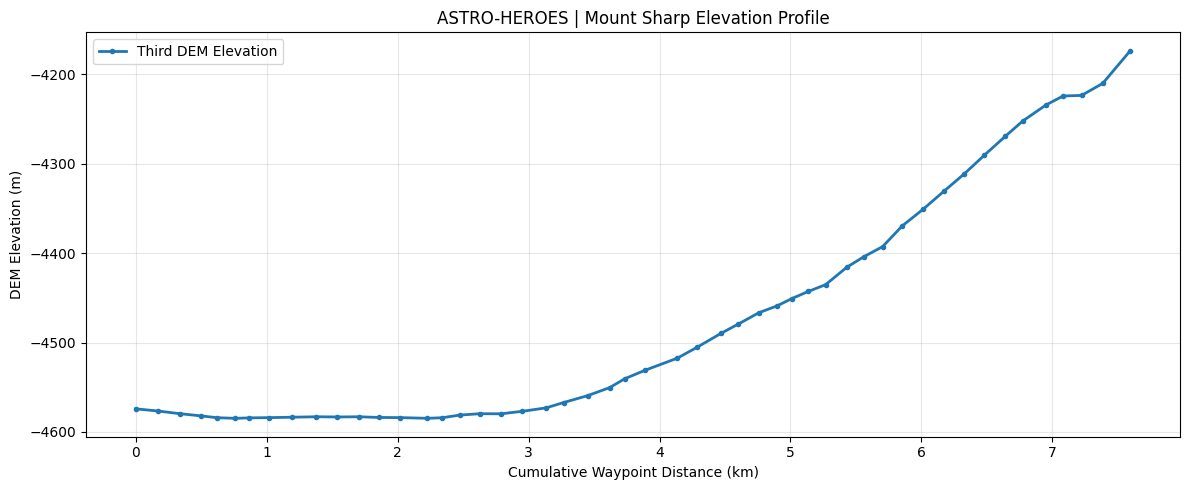

TOTAL WAYPOINT DISTANCE: 7.6 km
MINIMUM ELEVATION: -4584.76 m
MAXIMUM ELEVATION: -4173.45 m
NET ELEVATION CHANGE: 400.68 m
TOTAL ASCENT: 413.37 m
TOTAL DESCENT: 12.69 m


In [189]:
# STEP 10A: MOUNT SHARP ELEVATION PROFILE
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use elevations extracted from the Third DEM
terrain_profile = validated_dem_df.sort_values(
    "Waypoint_ID"
).copy()

# Calculate distances between consecutive waypoints
# using the Mars radius in kilometers
MARS_RADIUS_KM = 3389.5

lat = np.radians(terrain_profile["Latitude"].to_numpy())
lon = np.radians(terrain_profile["Longitude"].to_numpy())

dlat = np.diff(lat)
dlon = np.diff(lon)

a = (
    np.sin(dlat / 2)**2
    + np.cos(lat[:-1]) * np.cos(lat[1:])
    * np.sin(dlon / 2)**2
)

a = np.clip(a, 0, 1)

segment_km = (
    2 * MARS_RADIUS_KM * np.arcsin(np.sqrt(a))
)

terrain_profile["Distance_km"] = np.concatenate(
    ([0], np.cumsum(segment_km))
)

# Plot elevation profile
plt.figure(figsize=(12, 5))

plt.plot(
    terrain_profile["Distance_km"],
    terrain_profile["Third DEM"],
    marker="o",
    markersize=3,
    linewidth=2,
    label="Third DEM Elevation"
)

plt.xlabel("Cumulative Waypoint Distance (km)")
plt.ylabel("DEM Elevation (m)")
plt.title("ASTRO-HEROES | Mount Sharp Elevation Profile")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Display route statistics
elevations = terrain_profile["Third DEM"].to_numpy()

elevation_changes = np.diff(elevations)

print("TOTAL WAYPOINT DISTANCE:",
      round(terrain_profile["Distance_km"].iloc[-1], 2), "km")

print("MINIMUM ELEVATION:",
      round(np.nanmin(elevations), 2), "m")

print("MAXIMUM ELEVATION:",
      round(np.nanmax(elevations), 2), "m")

print("NET ELEVATION CHANGE:",
      round(elevations[-1] - elevations[0], 2), "m")

print("TOTAL ASCENT:",
      round(np.nansum(np.maximum(elevation_changes, 0)), 2), "m")

print("TOTAL DESCENT:",
      round(np.nansum(np.maximum(-elevation_changes, 0)), 2), "m")

# ==========================================


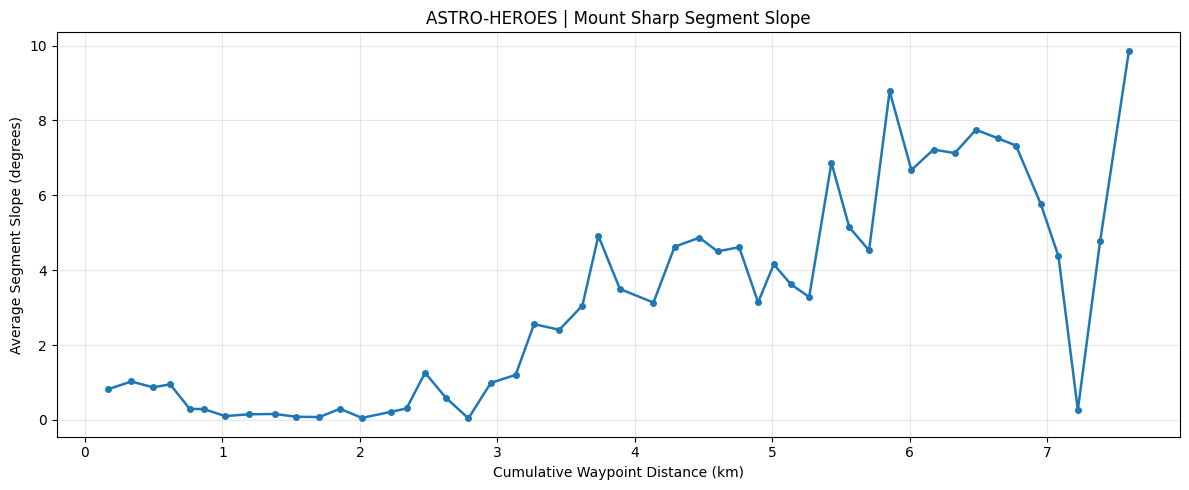

SEGMENTS ANALYZED: 49
MEAN ABSOLUTE SLOPE: 3.19 degrees
MAXIMUM SEGMENT SLOPE: 9.86 degrees

FIVE STEEPEST SEGMENTS:
 Waypoint_ID  Distance_km  Segment_Slope_deg  Absolute_Slope_deg
          50         7.60               9.86                9.86
          39         5.85               8.78                8.78
          43         6.48               7.75                7.75
          44         6.64               7.53                7.53
          45         6.77               7.33                7.33


In [190]:
# STEP 11A: MARSWALK SEGMENT SLOPE ANALYSIS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

slope_profile = terrain_profile.copy()

# Horizontal distance between waypoints (meters)
distance_m = (
    slope_profile["Distance_km"].diff() * 1000
)

# Elevation change between waypoints (meters)
elevation_change = slope_profile["Third DEM"].diff()

# Calculate signed segment slope angle
slope_profile["Segment_Slope_deg"] = np.degrees(
    np.arctan2(elevation_change, distance_m)
)

# Absolute slope magnitude
slope_profile["Absolute_Slope_deg"] = (
    slope_profile["Segment_Slope_deg"].abs()
)

# First waypoint has no preceding segment
slope_profile.loc[
    slope_profile.index[0],
    ["Segment_Slope_deg", "Absolute_Slope_deg"]
] = np.nan

# Plot slope profile
plt.figure(figsize=(12, 5))

plt.plot(
    slope_profile["Distance_km"],
    slope_profile["Absolute_Slope_deg"],
    marker="o",
    markersize=4,
    linewidth=1.8
)

plt.xlabel("Cumulative Waypoint Distance (km)")
plt.ylabel("Average Segment Slope (degrees)")
plt.title("ASTRO-HEROES | Mount Sharp Segment Slope")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print statistics
valid_slopes = slope_profile["Absolute_Slope_deg"].dropna()

print("SEGMENTS ANALYZED:", len(valid_slopes))
print("MEAN ABSOLUTE SLOPE:",
      round(valid_slopes.mean(), 2), "degrees")
print("MAXIMUM SEGMENT SLOPE:",
      round(valid_slopes.max(), 2), "degrees")

print("\nFIVE STEEPEST SEGMENTS:")
print(
    slope_profile.nlargest(
        5, "Absolute_Slope_deg"
    )[
        [
            "Waypoint_ID",
            "Distance_km",
            "Segment_Slope_deg",
            "Absolute_Slope_deg"
        ]
    ].round(2).to_string(index=False)
)

# Save for next step
marswalk_slope_df = slope_profile.copy()

# ==========================================


THIRD DEM LOCAL SLOPE RESULTS
Valid slope pixels: 3652626
Mean slope: 7.4 degrees
Median slope: 5.35 degrees
Maximum slope: 74.04 degrees
95th percentile: 21.19 degrees


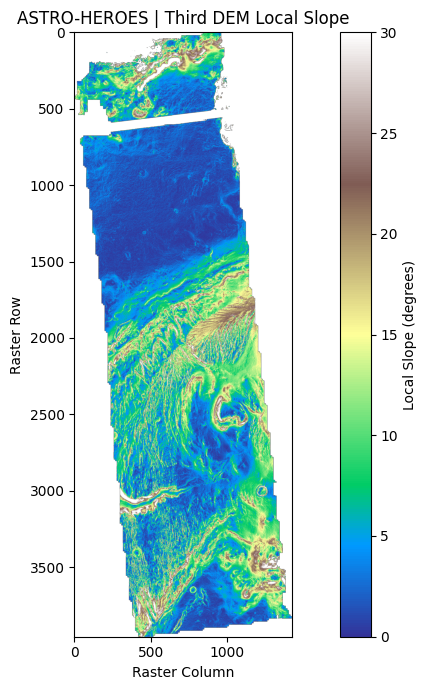

In [191]:
# STEP 11C: THIRD DEM LOCAL SLOPE ANALYSIS
# ==========================================

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

with rasterio.open(third_dem_url) as src:

    # Read elevation and respect NoData mask
    elevation = src.read(1, masked=True)
    valid = ~np.ma.getmaskarray(elevation)

    z = elevation.filled(0).astype(np.float64)

    dx, dy = map(abs, src.res)

    # Horn 3x3 slope calculation
    kernel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ]) / (8 * dx)

    kernel_y = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ]) / (8 * dy)

    dz_dx = convolve(z, kernel_x, mode="nearest")
    dz_dy = convolve(z, kernel_y, mode="nearest")

    slope_deg = np.degrees(
        np.arctan(np.hypot(dz_dx, dz_dy))
    )

    # Require all 9 neighboring pixels to be valid
    neighborhood_count = convolve(
        valid.astype(np.uint8),
        np.ones((3, 3), dtype=np.uint8),
        mode="constant",
        cval=0
    )

    slope_deg[neighborhood_count != 9] = np.nan

    # Store raster information for later steps
    third_slope_raster = slope_deg
    third_dem_transform = src.transform
    third_dem_crs = src.crs

valid_slopes = third_slope_raster[
    np.isfinite(third_slope_raster)
]

print("THIRD DEM LOCAL SLOPE RESULTS")
print("Valid slope pixels:", len(valid_slopes))
print("Mean slope:", round(valid_slopes.mean(), 2), "degrees")
print("Median slope:", round(np.median(valid_slopes), 2), "degrees")
print("Maximum slope:", round(valid_slopes.max(), 2), "degrees")
print("95th percentile:",
      round(np.percentile(valid_slopes, 95), 2), "degrees")

plt.figure(figsize=(10, 7))

plt.imshow(
    third_slope_raster,
    cmap="terrain",
    vmin=0,
    vmax=30
)

plt.colorbar(label="Local Slope (degrees)")
plt.title("ASTRO-HEROES | Third DEM Local Slope")
plt.xlabel("Raster Column")
plt.ylabel("Raster Row")
plt.tight_layout()
plt.show()

# ==========================================


In [192]:
# STEP 11B: INSPECT THIRD DEM SLOPE RASTER
# ==========================================

import numpy as np
import rasterio

with rasterio.open(third_dem_url) as src:

    print("THIRD DEM DIMENSIONS:")
    print("Height:", src.height)
    print("Width:", src.width)
    print("Resolution:", src.res)
    print("CRS:", src.crs.to_string())

    print("\nEXISTING SLOPE RASTER:")
    print("Shape:", third_slope_raster.shape)

    dimensions_match = (
        third_slope_raster.shape == (src.height, src.width)
    )

    print("Dimensions match Third DEM:",
          dimensions_match)

# Analyze finite slope values
valid = third_slope_raster[np.isfinite(third_slope_raster)]

print("\nSLOPE STATISTICS:")
print("Valid pixels:", len(valid))

if len(valid) > 0:
    print("Minimum:", round(float(valid.min()), 2))
    print("Mean:", round(float(valid.mean()), 2))
    print("Median:", round(float(np.median(valid)), 2))
    print("Maximum:", round(float(valid.max()), 2))
    print("95th percentile:",
          round(float(np.percentile(valid, 95)), 2))

    print("\nVALUES OUTSIDE 0-90 DEGREES:",
          int(((valid < 0) | (valid > 90)).sum()))

# ==========================================


THIRD DEM DIMENSIONS:
Height: 3956
Width: 1423
Resolution: (20.0, 20.0)
CRS: PROJCS["Mars (2015) - Sphere / Ocentric / Equirectangular, clon = 0",GEOGCS["Mars (2015) - Sphere / Ocentric",DATUM["Mars (2015) - Sphere",SPHEROID["Mars (2015) - Sphere",3396190,0,AUTHORITY["IAU","49900"]],AUTHORITY["IAU","49900"]],PRIMEM["Reference Meridian",0,AUTHORITY["IAU","49900"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["IAU","49900"]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["IAU","49910"]]

EXISTING SLOPE RASTER:
Shape: (3956, 1423)
Dimensions match Third DEM: True

SLOPE STATISTICS:
Valid pixels: 3652626
Minimum: 0.0
Mean: 7.4
Median: 5.35
Maximum: 74.04
95th percentile: 21.19

VALUES OUTSIDE 0-90 DEGREES: 0


In [193]:
# STEP 11D: EXTRACT LOCAL SLOPE AT WAYPOINTS
# ==========================================

import numpy as np
import pandas as pd
import rasterio
from pyproj import Transformer

waypoint_slopes = marswalk_slope_df.copy()

with rasterio.open(third_dem_url) as src:

    transformer = Transformer.from_crs(
        src.crs.geodetic_crs,
        src.crs,
        always_xy=True
    )

    x, y = transformer.transform(
        waypoint_slopes["Longitude"].to_numpy(),
        waypoint_slopes["Latitude"].to_numpy()
    )

    rows, cols = rasterio.transform.rowcol(
        src.transform, x, y
    )

    local_slopes = []

    for row, col in zip(rows, cols):

        if (
            0 <= row < third_slope_raster.shape[0]
            and 0 <= col < third_slope_raster.shape[1]
        ):
            value = third_slope_raster[row, col]
            local_slopes.append(
                float(value) if np.isfinite(value)
                else np.nan
            )
        else:
            local_slopes.append(np.nan)

waypoint_slopes["Local_DEM_Slope_deg"] = local_slopes

print("WAYPOINT LOCAL SLOPE RESULTS")
print("Total waypoints:", len(waypoint_slopes))
print("Valid local slopes:",
      waypoint_slopes["Local_DEM_Slope_deg"].notna().sum())

print("\nLOCAL SLOPE STATISTICS:")
print(
    waypoint_slopes["Local_DEM_Slope_deg"]
    .describe().round(2)
)

print("\n10 STEEPEST WAYPOINT LOCATIONS:")
print(
    waypoint_slopes.nlargest(
        10, "Local_DEM_Slope_deg"
    )[
        [
            "Waypoint_ID",
            "Distance_km",
            "Absolute_Slope_deg",
            "Local_DEM_Slope_deg"
        ]
    ].round(2).to_string(index=False)
)

# Save for future risk assessment
marswalk_terrain_df = waypoint_slopes.copy()

# ==========================================


WAYPOINT LOCAL SLOPE RESULTS
Total waypoints: 50
Valid local slopes: 50

LOCAL SLOPE STATISTICS:
count    50.00
mean      4.18
std       3.19
min       0.37
25%       1.20
50%       4.21
75%       5.81
max      13.90
Name: Local_DEM_Slope_deg, dtype: float64

10 STEEPEST WAYPOINT LOCATIONS:
 Waypoint_ID  Distance_km  Absolute_Slope_deg  Local_DEM_Slope_deg
          50         7.60                9.86                13.90
          39         5.85                8.78                 9.81
          43         6.48                7.75                 9.10
          40         6.01                6.68                 8.90
          36         5.43                6.87                 8.75
          45         6.77                7.33                 8.62
          44         6.64                7.53                 8.45
          38         5.70                4.53                 8.37
          42         6.33                7.13                 8.31
          41         6.17             

In [194]:
# ASTRO-HEROES | STEPS 12–14
# FINAL TERRAIN ANALYSIS AND VISUALIZATION
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from scipy.ndimage import uniform_filter
from pyproj import Transformer
from rasterio.transform import rowcol
from IPython.display import display

# -----------------------------------------------------


In [195]:
# STEP 12: DEM ELEVATION VARIABILITY
# -----------------------------------------------------

terrain = marswalk_terrain_df.copy()
terrain = terrain.sort_values(
    "Waypoint_ID"
).reset_index(drop=True)

assert len(terrain) == 50
assert terrain["Local_DEM_Slope_deg"].notna().any(), "No valid local DEM slopes; inspect coverage"

print("Starting ASTRO-HEROES terrain processing...")

with rasterio.open(third_dem_url) as src:

    elevation = src.read(1, masked=True)
    valid = ~np.ma.getmaskarray(elevation)

    z = elevation.filled(0).astype(np.float64)

    transform = src.transform
    crs = src.crs

    pixel_size = abs(src.res[0])
    window_size = 5

    # 5 x 5 pixels, approximately 100 m
    valid_float = valid.astype(np.float64)

    local_count = uniform_filter(
        valid_float,
        size=window_size,
        mode="constant",
        cval=0
    ) * window_size**2

    local_sum = uniform_filter(
        z,
        size=window_size,
        mode="constant",
        cval=0
    ) * window_size**2

    local_sum_sq = uniform_filter(
        z**2,
        size=window_size,
        mode="constant",
        cval=0
    ) * window_size**2

    roughness = np.full(
        z.shape, np.nan, dtype=np.float32
    )

    complete = (
        local_count >= window_size**2 - 0.01
    )

    local_mean = np.zeros_like(z)
    local_variance = np.zeros_like(z)

    local_mean[complete] = (
        local_sum[complete] / local_count[complete]
    )

    local_variance[complete] = (
        local_sum_sq[complete] / local_count[complete]
        - local_mean[complete]**2
    )

    roughness[complete] = np.sqrt(
        np.maximum(local_variance[complete], 0)
    ).astype(np.float32)

    # Transform Mars coordinates into DEM pixels
    transformer = Transformer.from_crs(
        crs.geodetic_crs,
        crs,
        always_xy=True
    )

    xs, ys = transformer.transform(
        terrain["Longitude"].to_numpy(),
        terrain["Latitude"].to_numpy()
    )

    rows, cols = rowcol(transform, xs, ys)

    waypoint_roughness = []

    for r, c in zip(rows, cols):

        if (
            0 <= r < roughness.shape[0]
            and 0 <= c < roughness.shape[1]
        ):
            value = roughness[r, c]

            waypoint_roughness.append(
                float(value)
                if np.isfinite(value)
                else np.nan
            )

        else:
            waypoint_roughness.append(np.nan)

terrain["Roughness_100m_m"] = waypoint_roughness

print("\nSTEP 12: ELEVATION VARIABILITY RESULTS")

print(
    "Valid waypoints:",
    terrain["Roughness_100m_m"].notna().sum(),
    "/ 50"
)

print(
    terrain["Roughness_100m_m"]
    .describe()
    .round(2)
)

# -----------------------------------------------------


Starting ASTRO-HEROES terrain processing...

STEP 12: ELEVATION VARIABILITY RESULTS
Valid waypoints: 50 / 50
count    50.00
mean      2.07
std       1.61
min       0.18
25%       0.59
50%       2.07
75%       3.22
max       7.18
Name: Roughness_100m_m, dtype: float64



STEP 13: TERRAIN HAZARD RESULTS
Terrain_Hazard
Low         25
Moderate    15
High        10
Name: count, dtype: int64

HIGHEST-PRIORITY WAYPOINTS:


,Waypoint_ID,Distance_km,Local_DEM_Slope_deg,Roughness_100m_m,Terrain_Hazard,Data_Status
49,50,7.60,13.90,7.18,High,Preliminary
38,39,5.85,9.81,4.77,High,Preliminary
42,43,6.48,9.10,4.43,High,Preliminary
39,40,6.01,8.90,4.45,High,Preliminary
35,36,5.43,8.75,4.08,High,Preliminary
44,45,6.77,8.62,4.04,High,Preliminary
43,44,6.64,8.45,4.28,High,Preliminary
37,38,5.70,8.37,4.06,High,Preliminary
41,42,6.33,8.31,4.18,High,Preliminary
40,41,6.17,8.25,4.12,High,Preliminary


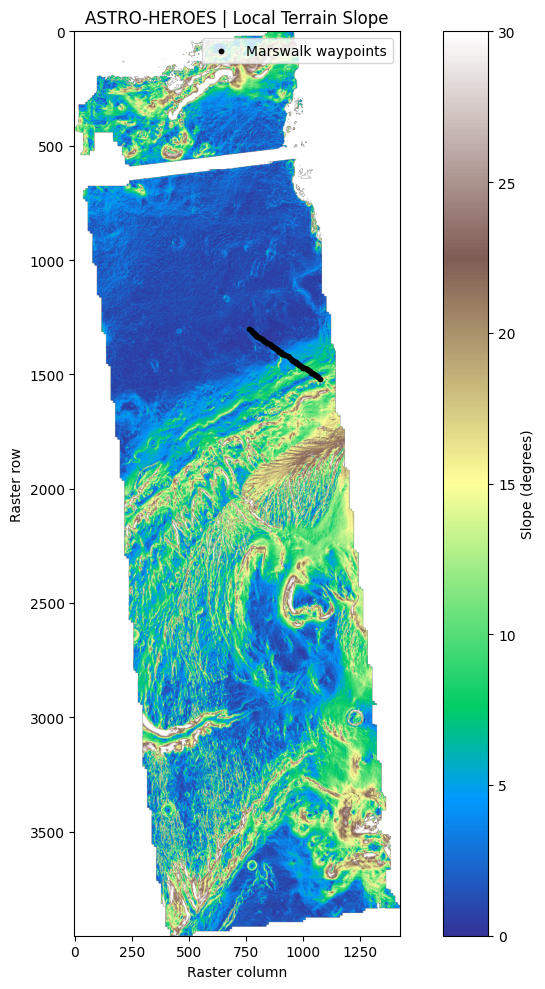

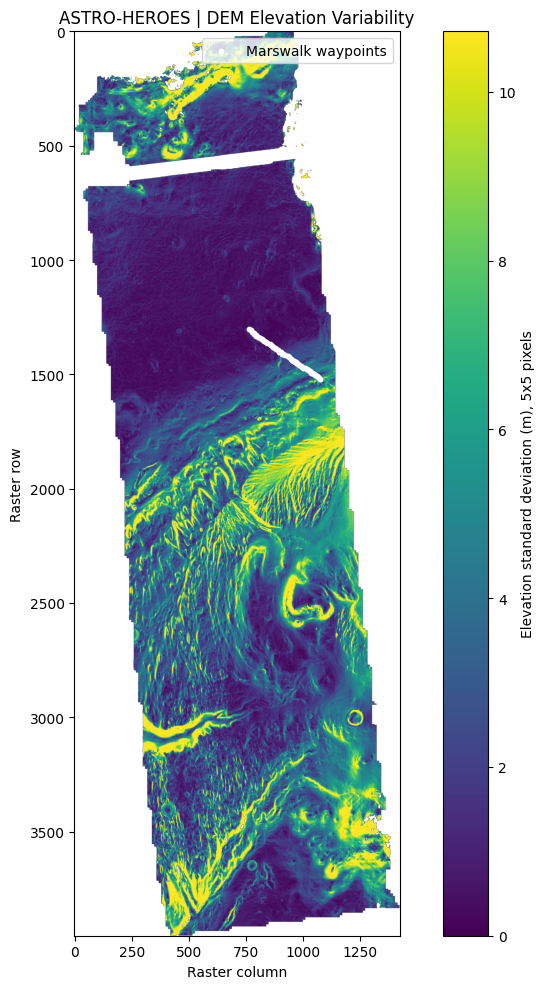

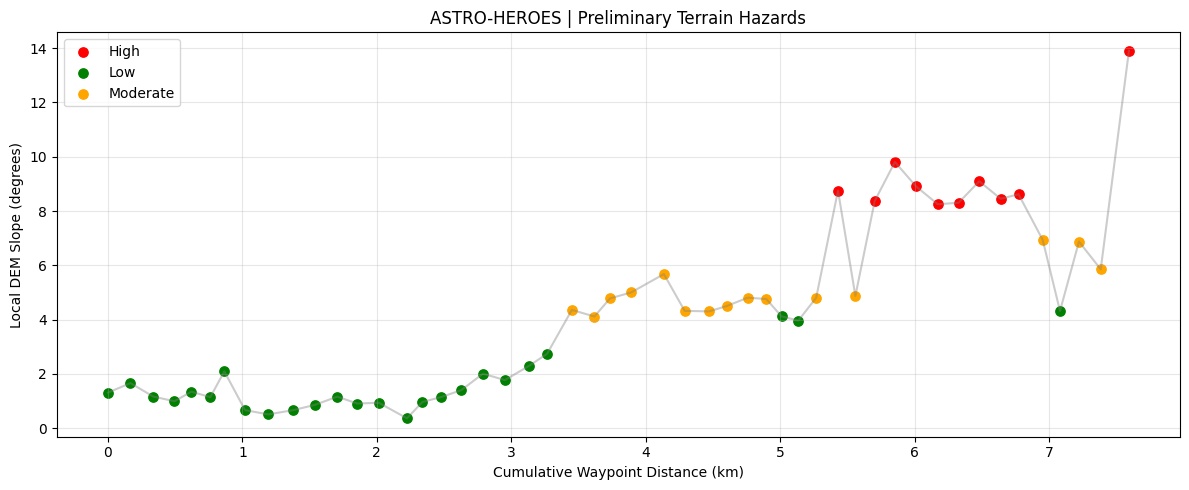

In [196]:
# STEP 13: PRELIMINARY TERRAIN HAZARDS
# -----------------------------------------------------

# Illustrative thresholds only.
# NOT validated astronaut safety limits.

SLOPE_LOW = 5.0
SLOPE_HIGH = 10.0

valid_roughness = (
    terrain["Roughness_100m_m"].dropna()
)

if valid_roughness.empty:
    raise ValueError(
        "No valid DEM elevation variability values."
    )

rough_low = valid_roughness.quantile(0.50)
rough_high = valid_roughness.quantile(0.80)

def classify_slope(value):

    if pd.isna(value):
        return 3

    if value < SLOPE_LOW:
        return 1

    if value < SLOPE_HIGH:
        return 2

    return 3


def classify_roughness(value):

    if pd.isna(value):
        return 3

    if value < rough_low:
        return 1

    if value < rough_high:
        return 2

    return 3


terrain["Slope_Class"] = (
    terrain["Local_DEM_Slope_deg"]
    .apply(classify_slope)
)

terrain["Roughness_Class"] = (
    terrain["Roughness_100m_m"]
    .apply(classify_roughness)
)

terrain["Terrain_Hazard_Class"] = terrain[
    ["Slope_Class", "Roughness_Class"]
].max(axis=1)

class_labels = {
    1: "Low",
    2: "Moderate",
    3: "High"
}

terrain["Terrain_Hazard"] = (
    terrain["Terrain_Hazard_Class"]
    .map(class_labels)
)

terrain["Data_Status"] = np.where(
    terrain["Roughness_100m_m"].isna(),
    "Incomplete",
    "Preliminary"
)

print("\nSTEP 13: TERRAIN HAZARD RESULTS")

print(
    terrain["Terrain_Hazard"]
    .value_counts()
    .reindex(
        ["Low", "Moderate", "High"],
        fill_value=0
    )
)

priority = terrain.sort_values(
    ["Terrain_Hazard_Class", "Local_DEM_Slope_deg"],
    ascending=[False, False]
)

print("\nHIGHEST-PRIORITY WAYPOINTS:")

display(
    priority[
        [
            "Waypoint_ID",
            "Distance_km",
            "Local_DEM_Slope_deg",
            "Roughness_100m_m",
            "Terrain_Hazard",
            "Data_Status"
        ]
    ].head(15).round(2)
)

# -----------------------------------------------------
# VISUALIZATION 1: LOCAL SLOPE MAP
# -----------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 10))

im = ax.imshow(
    third_slope_raster,
    cmap="terrain",
    vmin=0,
    vmax=30
)

ax.scatter(
    cols,
    rows,
    c="black",
    s=10,
    label="Marswalk waypoints"
)

fig.colorbar(
    im,
    ax=ax,
    label="Slope (degrees)"
)

ax.set_title(
    "ASTRO-HEROES | Local Terrain Slope"
)

ax.set_xlabel("Raster column")
ax.set_ylabel("Raster row")
ax.legend()

fig.tight_layout()
plt.show()

# -----------------------------------------------------
# VISUALIZATION 2: DEM ELEVATION VARIABILITY
# -----------------------------------------------------

rough_display_max = np.nanpercentile(
    roughness, 95
)

fig, ax = plt.subplots(figsize=(9, 10))

im = ax.imshow(
    roughness,
    cmap="viridis",
    vmin=0,
    vmax=rough_display_max
)

ax.scatter(
    cols,
    rows,
    c="white",
    s=10,
    label="Marswalk waypoints"
)

fig.colorbar(
    im,
    ax=ax,
    label="Elevation standard deviation (m), 5x5 pixels"
)

ax.set_title(
    "ASTRO-HEROES | DEM Elevation Variability"
)

ax.set_xlabel("Raster column")
ax.set_ylabel("Raster row")
ax.legend()

fig.tight_layout()
plt.show()

# -----------------------------------------------------
# VISUALIZATION 3: WAYPOINT HAZARD PROFILE
# -----------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

colors = {
    "Low": "green",
    "Moderate": "orange",
    "High": "red"
}

for hazard, group in terrain.groupby(
    "Terrain_Hazard"
):

    ax.scatter(
        group["Distance_km"],
        group["Local_DEM_Slope_deg"],
        color=colors[hazard],
        label=hazard,
        s=45
    )

ax.plot(
    terrain["Distance_km"],
    terrain["Local_DEM_Slope_deg"],
    color="gray",
    alpha=0.4
)

ax.set_xlabel(
    "Cumulative Waypoint Distance (km)"
)

ax.set_ylabel(
    "Local DEM Slope (degrees)"
)

ax.set_title(
    "ASTRO-HEROES | Preliminary Terrain Hazards"
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

# -----------------------------------------------------


In [197]:
# STEP 14: FINAL ENGINEERING VERIFICATION
# -----------------------------------------------------

print("\n" + "=" * 55)
print("ASTRO-HEROES TERRAIN ANALYSIS COMPLETE")
print("=" * 55)

print("Waypoints processed:", len(terrain))

print(
    "Valid slope waypoints:",
    terrain["Local_DEM_Slope_deg"].notna().sum()
)

print(
    "Valid variability waypoints:",
    terrain["Roughness_100m_m"].notna().sum()
)

print(
    "Maximum local slope:",
    round(
        terrain["Local_DEM_Slope_deg"].max(), 2
    ),
    "degrees"
)

print(
    "Maximum elevation variability:",
    round(
        terrain["Roughness_100m_m"].max(), 2
    ),
    "m"
)

print("\nENGINEERING INTERPRETATION:")
print(
    "Higher-priority terrain inspection areas occur "
    "toward the later portion of the waypoint sequence."
)

print("\nLIMITATIONS:")
print("- Hazard classes are preliminary.")
print("- Thresholds are not NASA safety limits.")
print("- The waypoint path is not verified traversable.")
print("- 20 m DEM data cannot resolve boot-scale hazards.")
print("- Elevation variability includes terrain gradient.")
print("- DEM vertical reference requires verification.")

print("\nNO FILE EXPORTS PERFORMED.")

# =====================================================



ASTRO-HEROES TERRAIN ANALYSIS COMPLETE
Waypoints processed: 50
Valid slope waypoints: 50
Valid variability waypoints: 50
Maximum local slope: 13.9 degrees
Maximum elevation variability: 7.18 m

ENGINEERING INTERPRETATION:
Higher-priority terrain inspection areas occur toward the later portion of the waypoint sequence.

LIMITATIONS:
- Hazard classes are preliminary.
- Thresholds are not NASA safety limits.
- The waypoint path is not verified traversable.
- 20 m DEM data cannot resolve boot-scale hazards.
- Elevation variability includes terrain gradient.
- DEM vertical reference requires verification.

NO FILE EXPORTS PERFORMED.


ASTRO-HEROES | MOBILITY ASSESSMENT
Waypoints: 50

MOBILITY SCREENING RESULTS
Mobility_Screening_Class
Low         25
Moderate    15
High        10
Name: count, dtype: int64

TOP PRIORITY WAYPOINTS


,Waypoint_ID,Distance_km,Local_DEM_Slope_deg,Roughness_100m_m,Ideal_Static_Friction_Min,Mobility_Screening_Class,Engineering_Recommendation
49,50,7.595,13.903,7.181,0.248,High,"Priority inspection: assess footing, soil trac..."
38,39,5.854,9.806,4.768,0.173,High,"Priority inspection: assess footing, soil trac..."
42,43,6.481,9.096,4.433,0.160,High,"Priority inspection: assess footing, soil trac..."
39,40,6.012,8.903,4.448,0.157,High,"Priority inspection: assess footing, soil trac..."
35,36,5.431,8.754,4.081,0.154,High,"Priority inspection: assess footing, soil trac..."
44,45,6.774,8.618,4.037,0.152,High,"Priority inspection: assess footing, soil trac..."
43,44,6.641,8.449,4.284,0.149,High,"Priority inspection: assess footing, soil trac..."
37,38,5.704,8.373,4.061,0.147,High,"Priority inspection: assess footing, soil trac..."
41,42,6.328,8.306,4.180,0.146,High,"Priority inspection: assess footing, soil trac..."
40,41,6.173,8.248,4.120,0.145,High,"Priority inspection: assess footing, soil trac..."


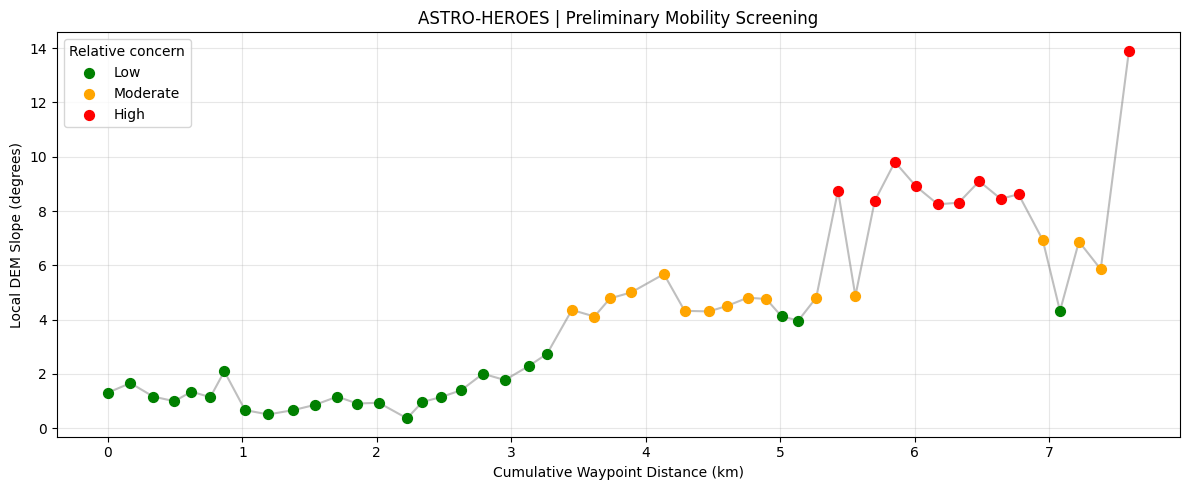

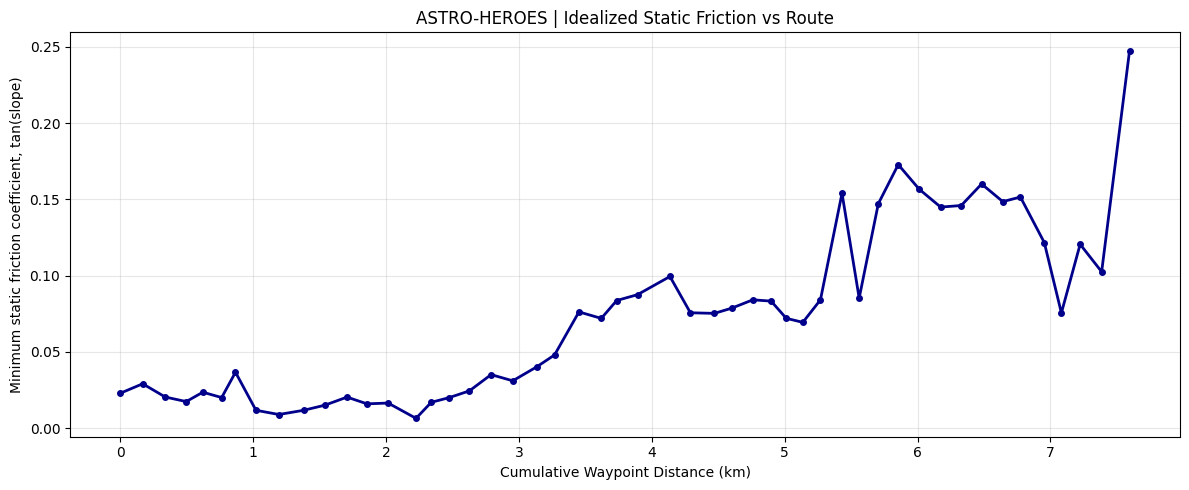


ASTRO-HEROES MOBILITY ASSESSMENT COMPLETE
Waypoints assessed: 50
Maximum slope: 13.9 degrees
Maximum idealized friction coefficient: 0.248
Highest-priority waypoint: 50

ENGINEERING CONCLUSIONS:
- Steeper slopes increase the downslope component of gravity.
- Higher idealized friction requirements indicate greater potential traction demand.
- DEM elevation variability highlights areas needing closer terrain inspection.
- High-screening waypoints should receive priority for detailed assessment.

IMPORTANT LIMITATIONS:
- Screening classes are illustrative.
- Soil friction and bearing strength are unknown.
- Astronaut boot traction is not measured.
- Dynamic walking stability is not modeled.
- Local obstacles below DEM resolution are unresolved.
- No astronaut route is certified safe by this analysis.

NO FILE EXPORTS PERFORMED.
    Waypoint_ID  Latitude  Longitude
0             1   -4.5813  137.44293
49           50   -4.6542  137.54758


In [198]:
# ASTRO-HEROES | STEP 15
# PRELIMINARY ASTRONAUT MOBILITY ASSESSMENT
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# -----------------------------------------------------
# 1. PREPARE EXISTING TERRAIN DATA
# -----------------------------------------------------

mobility = terrain.copy()
mobility = mobility.sort_values(
    "Waypoint_ID"
).reset_index(drop=True)

required_columns = [
    "Waypoint_ID",
    "Distance_km",
    "Local_DEM_Slope_deg",
    "Roughness_100m_m",
    "Terrain_Hazard"
]

missing = [
    col for col in required_columns
    if col not in mobility.columns
]

if missing:
    raise ValueError(
        f"Missing terrain columns: {missing}"
    )

print("ASTRO-HEROES | MOBILITY ASSESSMENT")
print("Waypoints:", len(mobility))

# -----------------------------------------------------
# 2. SLOPE-RELATED MOBILITY SCREENING
# -----------------------------------------------------

# Illustrative screening bands, not NASA limits.
# These represent relative terrain challenges.

def slope_mobility_class(slope):

    if pd.isna(slope):
        return "Unknown"

    if slope < 5:
        return "Low"

    if slope < 10:
        return "Moderate"

    return "High"


mobility["Slope_Mobility_Class"] = (
    mobility["Local_DEM_Slope_deg"]
    .apply(slope_mobility_class)
)

# -----------------------------------------------------
# 3. TRACTION AND STABILITY CONSIDERATIONS
# -----------------------------------------------------

# DEM slope is not a direct measurement of traction.
# Soil strength, friction, and loose material
# are not available in this dataset.

# Gravitational acceleration on Mars (m/s^2)
MARS_GRAVITY = 3.71

slope_rad = np.deg2rad(
    mobility["Local_DEM_Slope_deg"]
)

# Normalized downslope gravity component:
# sin(theta) = g_parallel / g
mobility["Downslope_Gravity_Fraction"] = (
    np.sin(slope_rad)
)

# Idealized static friction coefficient needed
# to resist sliding on a uniform incline:
# mu >= tan(theta)
#
# This is NOT a validated boot-soil traction model.

mobility["Ideal_Static_Friction_Min"] = (
    np.tan(slope_rad)
)

# Gravitational acceleration component
# along the slope (m/s^2)
mobility["Downslope_Acceleration_m_s2"] = (
    MARS_GRAVITY * np.sin(slope_rad)
)

# -----------------------------------------------------
# 4. TERRAIN VARIABILITY SCREENING
# -----------------------------------------------------

# The existing 5x5 DEM elevation STD includes
# changes caused by overall terrain gradient.
# It is NOT slope-corrected physical roughness.

q50 = mobility["Roughness_100m_m"].quantile(0.50)
q80 = mobility["Roughness_100m_m"].quantile(0.80)

def variability_class(value):

    if pd.isna(value):
        return "Unknown"

    if value < q50:
        return "Low"

    if value < q80:
        return "Moderate"

    return "High"


mobility["Variability_Class"] = (
    mobility["Roughness_100m_m"]
    .apply(variability_class)
)

# -----------------------------------------------------
# 5. COMBINED MOBILITY SCREENING
# -----------------------------------------------------

risk_rank = {
    "Low": 1,
    "Moderate": 2,
    "High": 3,
    "Unknown": 3
}

risk_label = {
    1: "Low",
    2: "Moderate",
    3: "High"
}

mobility["Mobility_Screening_Score"] = np.maximum(
    mobility["Slope_Mobility_Class"].map(risk_rank),
    mobility["Variability_Class"].map(risk_rank)
)

mobility["Mobility_Screening_Class"] = (
    mobility["Mobility_Screening_Score"]
    .map(risk_label)
)

# Qualitative engineering interpretation
def mobility_note(row):

    if row["Mobility_Screening_Class"] == "High":
        return (
            "Priority inspection: assess footing, "
            "soil traction, and local obstacles"
        )

    if row["Mobility_Screening_Class"] == "Moderate":
        return (
            "Additional terrain and footing "
            "verification recommended"
        )

    return (
        "Lower relative terrain concern; "
        "footing remains unverified"
    )


mobility["Engineering_Recommendation"] = (
    mobility.apply(mobility_note, axis=1)
)

# -----------------------------------------------------
# 6. DISPLAY ASSESSMENT RESULTS
# -----------------------------------------------------

print("\nMOBILITY SCREENING RESULTS")

print(
    mobility["Mobility_Screening_Class"]
    .value_counts()
    .reindex(
        ["Low", "Moderate", "High"],
        fill_value=0
    )
)

print("\nTOP PRIORITY WAYPOINTS")

priority_mobility = mobility.sort_values(
    [
        "Mobility_Screening_Score",
        "Local_DEM_Slope_deg"
    ],
    ascending=[False, False]
)

display(
    priority_mobility[
        [
            "Waypoint_ID",
            "Distance_km",
            "Local_DEM_Slope_deg",
            "Roughness_100m_m",
            "Ideal_Static_Friction_Min",
            "Mobility_Screening_Class",
            "Engineering_Recommendation"
        ]
    ].head(15).round(3)
)

# -----------------------------------------------------
# 7. VISUALIZATION 1: MOBILITY SCREENING PROFILE
# -----------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

colors = {
    "Low": "green",
    "Moderate": "orange",
    "High": "red"
}

for category in ["Low", "Moderate", "High"]:

    group = mobility[
        mobility["Mobility_Screening_Class"] == category
    ]

    ax.scatter(
        group["Distance_km"],
        group["Local_DEM_Slope_deg"],
        color=colors[category],
        s=50,
        label=category,
        zorder=3
    )

ax.plot(
    mobility["Distance_km"],
    mobility["Local_DEM_Slope_deg"],
    color="gray",
    alpha=0.5
)

ax.set_title(
    "ASTRO-HEROES | Preliminary Mobility Screening"
)

ax.set_xlabel(
    "Cumulative Waypoint Distance (km)"
)

ax.set_ylabel(
    "Local DEM Slope (degrees)"
)

ax.grid(alpha=0.3)
ax.legend(title="Relative concern")

fig.tight_layout()
plt.show()

# -----------------------------------------------------
# 8. VISUALIZATION 2: IDEALIZED FRICTION REQUIREMENT
# -----------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    mobility["Distance_km"],
    mobility["Ideal_Static_Friction_Min"],
    color="darkblue",
    linewidth=2,
    marker="o",
    markersize=4
)

ax.set_title(
    "ASTRO-HEROES | Idealized Static Friction vs Route"
)

ax.set_xlabel(
    "Cumulative Waypoint Distance (km)"
)

ax.set_ylabel(
    "Minimum static friction coefficient, tan(slope)"
)

ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

# -----------------------------------------------------
# 9. FINAL ENGINEERING SUMMARY
# -----------------------------------------------------

print("\n" + "=" * 55)
print("ASTRO-HEROES MOBILITY ASSESSMENT COMPLETE")
print("=" * 55)

print("Waypoints assessed:", len(mobility))

print(
    "Maximum slope:",
    round(mobility["Local_DEM_Slope_deg"].max(), 2),
    "degrees"
)

print(
    "Maximum idealized friction coefficient:",
    round(
        mobility["Ideal_Static_Friction_Min"].max(),
        3
    )
)

print(
    "Highest-priority waypoint:",
    int(
        mobility.loc[
            mobility["Local_DEM_Slope_deg"].idxmax(),
            "Waypoint_ID"
        ]
    )
)

print("\nENGINEERING CONCLUSIONS:")
print(
    "- Steeper slopes increase the downslope "
    "component of gravity."
)
print(
    "- Higher idealized friction requirements "
    "indicate greater potential traction demand."
)
print(
    "- DEM elevation variability highlights "
    "areas needing closer terrain inspection."
)
print(
    "- High-screening waypoints should receive "
    "priority for detailed assessment."
)

print("\nIMPORTANT LIMITATIONS:")
print("- Screening classes are illustrative.")
print("- Soil friction and bearing strength are unknown.")
print("- Astronaut boot traction is not measured.")
print("- Dynamic walking stability is not modeled.")
print("- Local obstacles below DEM resolution are unresolved.")
print("- No astronaut route is certified safe by this analysis.")

print("\nNO FILE EXPORTS PERFORMED.")

print(
    terrain[
        ["Waypoint_ID", "Latitude", "Longitude"]
    ].iloc[[0, -1]]
)

# ==========================================


In [199]:
# STEP 16A — Install and unpack the actual Marswalk routing engine
# The engine, FastAPI service and web UI are bundled inside this notebook.
%pip -q install rasterio pyproj scipy fastapi uvicorn
import os, sys, io, zipfile, base64
os.makedirs('/content', exist_ok=True)
_MARSWALK_ZIP_B64 = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_MARSWALK_ZIP_B64))) as archive:
    archive.extractall('/content')
sys.path.insert(0, '/content')
from marswalk_router import MarswalkRouter, RouterConfig
ROUTER_AVAILABLE = True
print('Marswalk router, api.py, and web/index.html installed in /content')


Marswalk router, api.py, and web/index.html installed in /content


In [200]:
# STEP 16B — Generate a real, georeferenced dem_clip.tif from the discovered CTX DTM
# Requires STEP 55–68 (STAC DEM discovery) to have run successfully.
# The PNG dem_clip.png is only a picture; it cannot provide terrain elevations.
import os
import numpy as np
import rasterio
from rasterio.windows import from_bounds
from pyproj import CRS, Transformer

HABITAT = (137.44293, -4.58130)
TARGETS = [(137.49000, -4.61500), (137.54758, -4.65420)]
MISSION_POINTS = [HABITAT, *TARGETS]
MARGIN_M = 800
DEM_OUTPUT = '/content/ASTRO_HEROES/outputs/layers/dem_clip.tif'
os.makedirs(os.path.dirname(DEM_OUTPUT), exist_ok=True)

# Prefer an existing valid local GeoTIFF. Otherwise try the STAC DEM assets.
source_candidates = [
    '/content/ASTRO_HEROES/outputs/layers/dem_clip.tif',
    '/content/dem_clip.tif',
    globals().get('third_dem_url'),
    globals().get('alternative_dem_url'),
    globals().get('geoid_dem_url'),
    globals().get('dem_url'),
]

def inspect_dem_coverage(path):
    uri = '/vsicurl/' + path if str(path).startswith(('http://', 'https://')) else path
    with rasterio.open(uri) as src:
        if src.crs is None:
            raise ValueError('DEM has no CRS')
        crs = CRS.from_wkt(src.crs.to_wkt())
        if not crs.is_projected:
            raise ValueError('DEM must be in a projected metric Mars CRS; cannot assume degree units')
        transformer = Transformer.from_crs(crs.geodetic_crs, crs, always_xy=True)
        xs, ys = transformer.transform([p[0] for p in MISSION_POINTS],
                                       [p[1] for p in MISSION_POINTS])
        if not np.isfinite(xs).all() or not np.isfinite(ys).all():
            raise ValueError('Coordinate transformation returned nonfinite values')
        if not all(src.bounds.left <= x <= src.bounds.right and
                   src.bounds.bottom <= y <= src.bounds.top for x, y in zip(xs, ys)):
            raise ValueError('DEM does not cover all mission points')
        window = from_bounds(min(xs)-MARGIN_M, min(ys)-MARGIN_M,
                             max(xs)+MARGIN_M, max(ys)+MARGIN_M,
                             transform=src.transform)
        window = window.round_offsets().round_lengths()
        window = window.intersection(rasterio.windows.Window(0, 0, src.width, src.height))
        if window.width < 5 or window.height < 5:
            raise ValueError('DEM overlap too small')
        data = src.read(1, window=window, masked=True)
        if np.ma.count(data) == 0:
            raise ValueError('DEM clip contains no valid elevation pixels')
        for x, y in zip(xs, ys):
            r, c = rasterio.transform.rowcol(src.window_transform(window), x, y)
            if not (0 <= r < data.shape[0] and 0 <= c < data.shape[1]):
                raise ValueError('Mission point outside DEM clip')
            if np.ma.is_masked(data[r, c]) or not np.isfinite(float(data[r, c])):
                raise ValueError('DEM has NoData at a mission point')
        return uri, window

DEM_SOURCE = None
problems = []
for candidate in source_candidates:
    if not candidate:
        continue
    if str(candidate) == DEM_OUTPUT and not os.path.isfile(DEM_OUTPUT):
        continue
    try:
        uri, window = inspect_dem_coverage(candidate)
        DEM_SOURCE = candidate
        print('Valid source:', candidate)
        break
    except Exception as exc:
        problems.append(f'{candidate}: {exc}')
        print('Skipping source:', str(candidate)[:100], '—', exc)

if DEM_SOURCE is None:
    raise RuntimeError('No available DEM covers all mission points with valid elevations. '
                       'Run the earlier STAC search or provide the original georeferenced CTX DTM.\n' +
                       '\n'.join(problems))

# Export an actual GeoTIFF preserving its CRS, geotransform, nodata and elevation values.
if os.path.abspath(str(DEM_SOURCE)) != os.path.abspath(DEM_OUTPUT):
    with rasterio.open(uri) as src:
        profile = src.profile.copy()
        profile.update(driver='GTiff', height=int(window.height), width=int(window.width),
                       count=1, transform=src.window_transform(window),
                       compress='deflate', tiled=False)
        with rasterio.open(DEM_OUTPUT, 'w', **profile) as dst:
            dst.write(src.read(1, window=window), 1)
else:
    print('Existing DEM clip reused')

# Validate the exported file independently.
inspect_dem_coverage(DEM_OUTPUT)
with rasterio.open(DEM_OUTPUT) as verified:
    print('GeoTIFF created:', DEM_OUTPUT)
    print('Shape:', verified.shape, '| CRS:', verified.crs, '| Resolution:', verified.res)
    print('Valid elevation pixels:', int(np.ma.count(verified.read(1, masked=True))))


Valid source: /content/ASTRO_HEROES/outputs/layers/dem_clip.tif
Existing DEM clip reused
GeoTIFF created: /content/ASTRO_HEROES/outputs/layers/dem_clip.tif
Shape: (296, 390) | CRS: PROJCS["Mars (2015) - Sphere / Ocentric / Equirectangular, clon = 0",GEOGCS["Mars (2015) - Sphere / Ocentric",DATUM["Mars (2015) - Sphere",SPHEROID["Mars (2015) - Sphere",3396190,0,AUTHORITY["IAU","49900"]],AUTHORITY["IAU","49900"]],PRIMEM["Reference Meridian",0,AUTHORITY["IAU","49900"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["IAU","49900"]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["IAU","49910"]] | Resolution: (20.0, 20.0)
Valid elevation pixels: 115440


In [201]:
# STEP 16C — Initialize the real Marswalk router using the exported GeoTIFF
import os
from marswalk_router import MarswalkRouter, RouterConfig
DEM_PATH = '/content/ASTRO_HEROES/outputs/layers/dem_clip.tif'
if not os.path.isfile(DEM_PATH):
    raise FileNotFoundError('Run STEP 16B to create the georeferenced dem_clip.tif first.')
OBSTACLE_RADIUS_M = 300
cfg = RouterConfig(max_slope_deg=15, warn_slope_deg=10,
                   safety_buffer_m=20, margin_m=800)
router = MarswalkRouter(DEM_PATH, MISSION_POINTS, cfg)
ROUTER_AVAILABLE = True
print('Router initialized from:', DEM_PATH)
print('Grid:', router.shape, '| Resolution:', router.res, 'm')


Router initialized from: /content/ASTRO_HEROES/outputs/layers/dem_clip.tif
Grid: (296, 390) | Resolution: 20.0 m


In [202]:

import json

# Route planning and obstacle rerouting
if ROUTER_AVAILABLE:
    # 1) Plan the safe route
    route = router.plan(HABITAT, TARGETS)
    print("PLANNED ROUTE:", json.dumps(route["summary"], indent=2))

    # 2) Astronaut reports an obstacle ahead
    current = route["points"][len(route["points"]) // 4]
    ahead = route["points"][len(route["points"]) // 2]

    new_route = router.reroute(
        current_lonlat=(current["lon"], current["lat"]),
        goal_lonlats=TARGETS,
        obstacle={
            "lon": ahead["lon"],
            "lat": ahead["lat"],
            "radius_m": OBSTACLE_RADIUS_M,
            "kind": "boulder field",
            "note": "Reported by astronaut"
        },
    )

    print("RE-ROUTED:", json.dumps(new_route["summary"], indent=2))

else:
    print("Skipped: router module not available.")


PLANNED ROUTE: {
  "length_m": 8009.4,
  "ascent_m": 419.4,
  "descent_m": 18.7,
  "max_slope_deg": 13.9,
  "mean_slope_deg": 3.7,
  "est_duration_min": 234,
  "hazard": "High",
  "alerts": 6,
  "obstacles_known": 0
}
RE-ROUTED: {
  "length_m": 5991.8,
  "ascent_m": 414.5,
  "descent_m": 2.3,
  "max_slope_deg": 13.9,
  "mean_slope_deg": 4.7,
  "est_duration_min": 186,
  "hazard": "High",
  "alerts": 11,
  "obstacles_known": 1
}


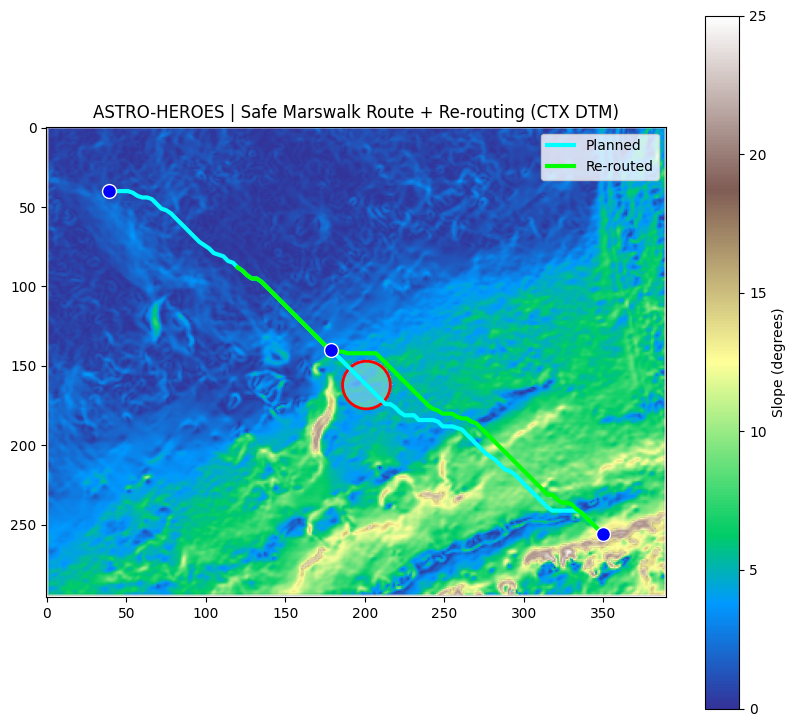

In [203]:
# Route visualization
if ROUTER_AVAILABLE:
    # 3) Plot on the slope map
    fig, ax = plt.subplots(figsize=(10, 9))
    im = ax.imshow(np.ma.masked_invalid(router.slope), cmap="terrain", vmin=0, vmax=25)
    ax.imshow(np.ma.masked_where(~router.blocked, router.blocked), cmap="Reds", alpha=0.35)
    for r, color, label in [(route, "cyan", "Planned"), (new_route, "lime", "Re-routed")]:
        rc = [router.lonlat_to_rc(p["lon"], p["lat"]) for p in r["points"]]
        ax.plot([c for _, c in rc], [r_ for r_, _ in rc], color=color, lw=3, label=label)
    for lon, lat in [HABITAT, *TARGETS]:
        rr, cc = router.lonlat_to_rc(lon, lat)
        ax.plot(cc, rr, "o", ms=10, mec="white", mfc="blue")
    orr, occ = router.lonlat_to_rc(ahead["lon"], ahead["lat"])
    ax.add_patch(plt.Circle((occ, orr), OBSTACLE_RADIUS_M / router.res, color="red", fill=False, lw=2))
    fig.colorbar(im, ax=ax, label="Slope (degrees)")
    ax.set_title("ASTRO-HEROES | Safe Marswalk Route + Re-routing (CTX DTM)")
    ax.legend()
    plt.show()
else:
    print("Skipped: router module not available.")

In [204]:
# Router layer and JSON exports
if ROUTER_AVAILABLE:
    # 4) Export for the map / HUD team
    router.save_layers("/content/ASTRO_HEROES/outputs/layers")      # dem_clip, slope, roughness, cost .tif
    router.save_json(route, "/content/ASTRO_HEROES/outputs/route.json")
    router.save_json(new_route, "/content/ASTRO_HEROES/outputs/route_rerouted.json")
    router.save_json(router.obstacles_geojson(), "/content/ASTRO_HEROES/outputs/obstacles.geojson")
    print("Exports saved.")
else:
    print("Skipped: router module not available.")

Exports saved.


In [205]:
# Optional ZIP export
# OPTIONAL: run this cell manually after router exports complete.
# import shutil
# from google.colab import files
# shutil.make_archive('/content/ASTRO_HEROES_outputs', 'zip', '/content/ASTRO_HEROES/outputs')
# files.download('/content/ASTRO_HEROES_outputs.zip')

In [206]:
# Optional Google Drive backup
# OPTIONAL: run this cell manually if you want a Drive backup.
# from google.colab import drive
# import shutil
# drive.mount('/content/drive')
# shutil.copytree('/content/ASTRO_HEROES/outputs',
#                 '/content/drive/MyDrive/ASTRO_HEROES_outputs',
#                 dirs_exist_ok=True)

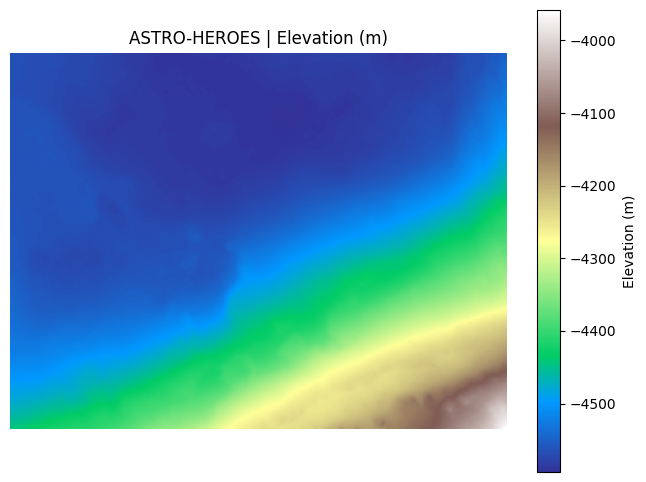

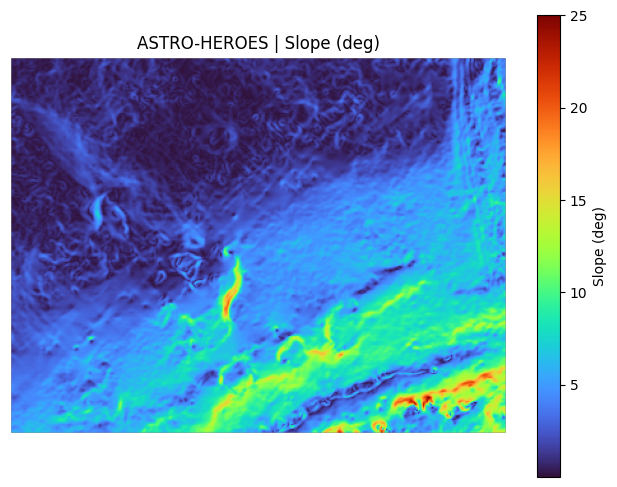

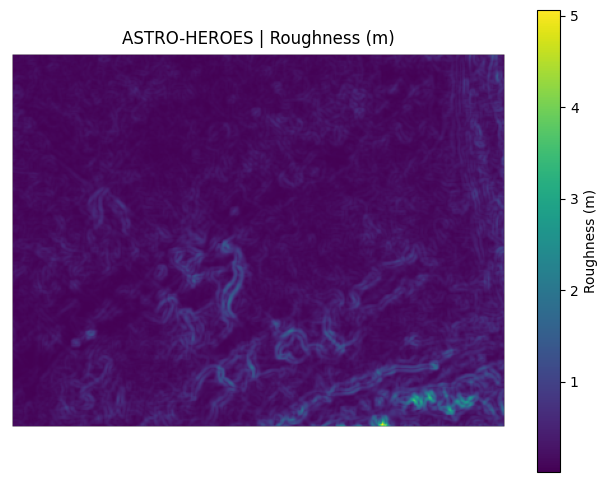

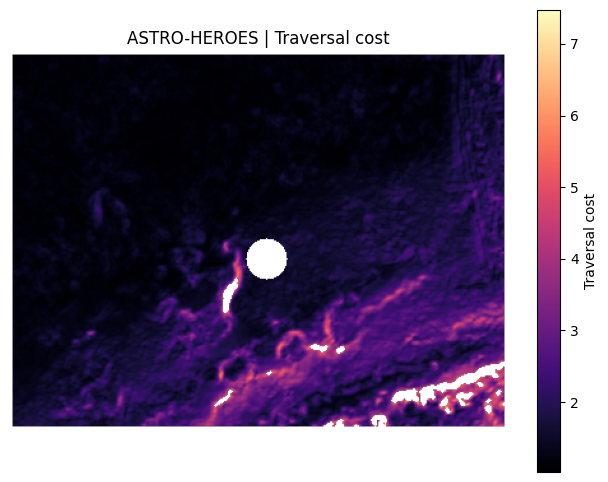

In [207]:
# Visualize exported router layers
if ROUTER_AVAILABLE and os.path.isdir("/content/ASTRO_HEROES/outputs/layers"):
    import rasterio, numpy as np, matplotlib.pyplot as plt, os

    folder = "/content/ASTRO_HEROES/outputs/layers"
    styles = {"dem_clip": ("terrain", "Elevation (m)"),
              "slope": ("turbo", "Slope (deg)"),
              "roughness": ("viridis", "Roughness (m)"),
              "cost": ("magma", "Traversal cost")}

    for name, (cmap, label) in styles.items():
        with rasterio.open(f"{folder}/{name}.tif") as src:
            data = src.read(1, masked=True)
        plt.figure(figsize=(8, 6))
        plt.imshow(data, cmap=cmap)
        plt.colorbar(label=label)
        plt.title(f"ASTRO-HEROES | {label}")
        plt.axis("off")
        plt.savefig(f"{folder}/{name}.png", dpi=150, bbox_inches="tight")
        plt.show()
else:
    print("Skipped: router layers not available.")

In [208]:
# STEP 17A — Compare uploaded historical results (optional)
import json, os
paths = {'original':'/content/route.json', 'rerouted':'/content/route_rerouted.json'}
if all(os.path.isfile(p) for p in paths.values()):
    for name, path in paths.items():
        with open(path, encoding='utf-8') as f:
            result = json.load(f)
        print(name.upper(), json.dumps(result.get('summary', {}), indent=2))
    print('Note: the rerouted route may start partway along the original route; compare equivalent endpoints.')
else:
    print('Optional saved JSON files not uploaded; new router results above are still usable.')


Optional saved JSON files not uploaded; new router results above are still usable.
